# Forecasting the 2026 U.S. House and Senate elections with a linear model

This notebook forecasts every 2026 House and Senate race: the Democratic candidate's share of the two-party vote, an 80% prediction interval around that share, and the probability that the Democrat wins. Simulating all races together gives a distribution of seats for each chamber.

The forecast is frozen as of **27 October 2026**, a week before election day, and uses only information that was available then. It was built for a forecasting competition, so a few conventions (which candidate counts as "the Democrat", which races are scored, the format of the output files) follow the competition's rules rather than my own choices.

### The forecast

| | Median Democratic seats | 80% range | P(Democratic majority) |
|---|---|---|---|
| House | 242 | 222–267 | 0.94 |
| Senate | 51 | 47–55 | 0.55 |

In 12% of the Senate simulations the chamber splits 50–50, which counts as Republican control because the vice president is a Republican. These figures come from the run saved in this notebook (Section 7). They are conditional on the model's assumptions, the most important being that the 2026 national polling error behaves like those of 2012–2024.

### How the model works

Each race result is treated as two pieces: the national environment, and where the race sits relative to it.

* **National environment.** The generic-ballot polling average, adjusted for the polls' average miss in past cycles. Because the average miss rests on only seven elections, the adjustment is shrunk toward zero.
* **Position relative to the nation.** A weighted least-squares regression on about 2,950 contested races from 2012–2024. Its inputs include 46 different features. Recent cycles count more: each cycle gets 0.75 times the weight of the one after it, so 2024 carries about four times the weight of 2014.
* **Uncertainty.** A Monte Carlo simulation adds an error shared by every race, one shared within each state and one specific to each race, all sized from the model's own out-of-sample errors.

The national swing is kept out of the regression because there are only seven past examples of it. What the regression learns instead, how races line up against each other, is far more stable from one election to the next (Section 4).

### How it was tested

Every quantity the forecast reports has a backtest on 2012–2024 in which each past election is forecast without using its own results (Section 6): vote-share error for the point forecasts, Brier score and log loss for the win probabilities, coverage for the intervals, and seat-count error for the chamber totals. The short version: the full model beats simple baselines on race-level vote share by about 0.3–0.4 points of mean absolute error, but not on House seat totals, where carrying each district's last result forward ("uniform swing") did better. Seven elections is a small sample for any of these comparisons.

### Contents

1. Setup
2. Data
3. Features
4. Two patterns in the data
5. Model
6. Evaluation
7. The 2026 forecast
8. What drives the forecasts
9. Saved outputs
10. Limitations
11. Summary

The input data is not distributed with this notebook. Section 2.1 lists every file and where it comes from.

## Terms and conventions

| Term | Meaning here |
|---|---|
| D share | The Democratic-side candidate's share of the two-party vote, D / (D + R) × 100. 50 is a tie. Shares and errors are in percentage points ("pts") of D share unless stated otherwise; the submission files use fractions (0–1). |
| D side, R side | The competition's convention for who counts as "the Democrat". An independent running in place of a Democrat, such as Dan Osborn in Nebraska's Senate race, is on the D side. |
| Cycle | One election year. All races in a cycle share a national environment. |
| National House vote | The D share of all House votes cast nationwide. It defines the training target and is known only after the election. |
| Generic ballot | The poll question "which party's candidate would you vote for in your House district?" Its polling average sets the forecast's national level. |
| PVI | Partisan voting index: how much more Democratic a district or state voted than the nation in recent presidential elections, in pts (positive = Democratic lean). Built only from presidential elections held before each race. |
| Prior result | The district's D share in the previous House election, used only when the district's lines did not change. Also called the lag. |
| Expert rating | A race rating from Cook Political Report, Inside Elections or Sabato's Crystal Ball, coded from Safe R (−3) through Tossup (0) to Safe D (+3). |
| Scored race | A race the competition scores (`scored = 1` in `races_2026.csv`). Unscored races have no real two-party contest, for example no Republican on the ballot, and the competition fixes their prediction. |
| LOCO | Leave-one-cycle-out cross-validation: fit on six cycles, predict the seventh (Section 5.1). |

## 1. Setup

### 1.1 Packages

The next cell checks installed versions against the ones the notebook was tested with, and installs `shap` if it is missing (Colab does not always include it). `shap` only draws the plots in Section 8; the SHAP values themselves are computed directly from the coefficients. Versions are saved to `environment.json` in Section 9.

In [ ]:
import importlib.metadata
import re
import subprocess
import sys

MIN_VERSIONS = {
    "numpy": "1.24",
    "pandas": "2.0",
    "scipy": "1.10",
    "scikit-learn": "1.3",
    "matplotlib": "3.7",
    "joblib": "1.2",
    "shap": "0.44",
}


def installed_version(package: str) -> str | None:
    """Installed version of `package`, or None if it is not installed."""
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def version_tuple(version: str) -> tuple[int, ...]:
    """'2.2.3' or '2.2.3+cu121' -> (2, 2, 3), for comparisons."""
    return tuple(int(part) for part in re.findall(r"\d+", version.split("+")[0])[:3])


if installed_version("shap") is None:
    print("Installing shap (used only for the Section 8 plots) ...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", f"shap>={MIN_VERSIONS['shap']}"])

PACKAGE_VERSIONS = {pkg: installed_version(pkg) for pkg in MIN_VERSIONS}
too_old = [pkg for pkg, minimum in MIN_VERSIONS.items()
           if PACKAGE_VERSIONS[pkg] is None
           or version_tuple(PACKAGE_VERSIONS[pkg]) < version_tuple(minimum)]
print(f"Python {sys.version.split()[0]}")
for pkg, version in PACKAGE_VERSIONS.items():
    print(f"  {pkg:<13} {version or 'not installed':<10} (needs >= {MIN_VERSIONS[pkg]})")
if too_old:
    raise RuntimeError(f"Please upgrade: pip install -U {' '.join(too_old)}")

Python 3.13.18
  numpy         2.4.6      (needs >= 1.24)
  pandas        2.2.3      (needs >= 2.0)
  scipy         1.16.3     (needs >= 1.10)
  scikit-learn  1.6.1      (needs >= 1.3)
  matplotlib    3.10.0     (needs >= 3.7)
  joblib        1.6.0      (needs >= 1.2)
  shap          0.54.1     (needs >= 0.44)


### 1.2 Imports

In [ ]:
import json
import logging
import os
import unicodedata
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from scipy import stats
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import LeaveOneGroupOut

### 1.3 Configuration

Every setting that can change a result is in the next cell.

**Paths.** The project folder holds this notebook, the `build_*.py` scripts, the input folder `new data/` and the output folder `outputs_linear_updated/`. On Colab the project folder is `MyDrive/Election Predicting` on Google Drive; elsewhere it is the folder Jupyter was started in. Setting the environment variable `FORECAST_PROJECT_DIR` overrides both.

**Notes.** Ordinary least squares has no tuning parameters, but several choices around it affect the results. None was set by a formal search. Some were set with the backtest in view, which makes the backtest a weaker check on them (Section 5.2).

| Setting | Value | What it controls | Basis |
|---|---|---|---|
| `NAT_SHRINK_N0` | 3 | Strength of the polling-bias correction (5.1). With seven equally weighted cycles the average past miss would be applied at 7/(7+3) = 70%. The 2026 recency weights sum to about 3.5, so it is applied at about 54%. | The bias estimate rests on seven elections. |
| `NATIONAL_SD_FLOOR` | 2.25 pts | Minimum SD of the error shared by all races in a cycle (6.3). | Chosen after looking at the seat-count backtest (6.4), where smaller values left the 2018 and 2020 House totals well outside their 80% ranges. The held-out errors alone imply about 1.4 pts, so the width of the seat distributions owes more to this setting than to the data. |
| `COMMON_ERROR_DF` | 5 | Tail weight of the shared error. | |
| `POLL_TIMING_SD` | 0.75 pts | Extra national uncertainty for 2026. The 2026 generic-ballot average ends on 26 October, eight days before the election, while the training years use final averages. | |
| `MAJOR_THIRD_SHARE` | 15% | Races in which a third candidate reaches this share are dropped from training. | |
| `POLL_WINDOW_DAYS` | 28 | Race polls are averaged over the 28 days ending 7 days before election day, in every year. | Makes the training polls exactly as old as the 2026 polls. |
| `USE_SWING_INTERACTIONS` | True | Adds demographics × expected-national-swing features (3.5). | |
| `RECENCY_DECAY` | 0.75 | Weight of each training cycle relative to the next one (5.1); 1.0 means equal weights. | Recent elections should resemble 2026 more, but down-weighting old cycles shrinks an already small sample. The equal-weights model is reported in 6.2 rather than used to tune this value. |
| `RECENCY_WEIGHT_NATIONAL` | True | Applies the same recency weights to the polling-bias correction. | |
| `ALLOW_SAME_YEAR_DISTRICT_ACS` | True | Lets training years use district ACS estimates for the election year itself, which were published after the election (3.5). | The ACS measures population shares, not votes, and they change slowly. Setting it to False substitutes state values. |

In [ ]:
# --- Where the data lives ------------------------------------------------------------------------
try:                         # Colab: the project folder is on Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    DEFAULT_PROJECT_DIR = "/content/drive/MyDrive/Election Predicting"
except ImportError:          # elsewhere: the folder Jupyter was started in
    DEFAULT_PROJECT_DIR = "."

PROJECT_DIR = Path(os.environ.get("FORECAST_PROJECT_DIR", DEFAULT_PROJECT_DIR)).resolve()
DATA_DIR = PROJECT_DIR / "new data"
OUTPUT_DIR = PROJECT_DIR / "outputs_linear_updated"
FIGURE_DIR = OUTPUT_DIR / "figures"
SAVE_FIGURES = False          # True: also write each figure to OUTPUT_DIR/figures/<name>.png

# --- The election being forecast -----------------------------------------------------------------
ELECTION_YEAR = 2026
FORECAST_DATE = os.environ.get("FORECAST_DATE", "2026-10-27")  # also the scandal-marker cutoff
ELECTION_DATE = "2026-11-03"
PRESIDENT_PARTY = "R"        # party holding the White House on election day
IS_MIDTERM = 1
FIRST_TRAIN_YEAR = 2012
SCANDAL_HIST_ASOF = "10-15"  # MM-DD cutoff of the historical scandal markers

# --- Reproducibility -----------------------------------------------------------------------------
SEED = 42                    # seeds every Monte Carlo simulation

# --- National level ------------------------------------------------------------------------------
NAT_SHRINK_N0 = 3            # polling-bias correction = sum(w * (actual - poll)) / (sum(w) + N0)

# --- Recency weighting (Section 5.1) -------------------------------------------------------------
RECENCY_DECAY = 0.75         # weight of each earlier cycle relative to the next; 1.0 = equal weights
RECENCY_WEIGHT_NATIONAL = True   # also recency-weight the polling-bias correction

# --- Evaluation ----------------------------------------------------------------------------------
FORWARD_TEST_YEARS = [2016, 2018, 2020, 2022, 2024]  # forward-in-time evaluation (Section 6.2)

# --- Feature-engineering thresholds --------------------------------------------------------------
MAJOR_THIRD_SHARE = 15       # % for a third candidate that excludes a race from training
COMPETITIVE_PVI = 10         # |PVI| <= 10 counts as a competitive race in the error tables
MONEY_Z_CLIP = 3             # clip the standardised money feature at +/- 3 SD
SHARE_CLIP = (1, 99)         # bounds for point forecasts (% D share)

# --- Demographics (Section 3.5) ------------------------------------------------------------------
USE_DEMOGRAPHICS = True          # demographics_state.csv: Senate races and House fallbacks
USE_DISTRICT_DEMOGRAPHICS = True # district_demographics_2012_2026.csv: House races
ALLOW_SAME_YEAR_DISTRICT_ACS = True  # new-lines training years may use the first ACS on those lines
USE_SWING_INTERACTIONS = True    # add demographics x expected-swing features (see table above)
ACS_2025_RELEASE = "2026-10-29"  # 2025 ACS 1-year release; before it, 2026 must use the 2024 ACS

# --- Race polls (Section 3.6) --------------------------------------------------------------------
USE_SENATE_POLLS = True      # use senate_polls.csv if it is present
USE_HOUSE_POLLS = True       # use house_polls.csv if it is present
POLL_WINDOW_DAYS = 28        # average polls from the 28 days ending at the forecast lead

# --- Expert race ratings (Section 3.7) -----------------------------------------------------------
USE_RATINGS = True           # use race_ratings.csv (checked against race_ratings_long.csv)

# --- Uncertainty simulation (Section 6.3) --------------------------------------------------------
N_SIMS = 20_000              # simulated elections for the 2026 forecast
N_SIMS_BACKTEST = 5_000      # simulated elections per cycle in the calibration backtest
POLL_TIMING_SD = 0.75        # extra national SD (pts): the 2026 average ends 8 days out
NATIONAL_SD_FLOOR = 2.25     # minimum SD (pts) of the shared error; binds in the final fit
COMMON_ERROR_DF = 5          # Student-t degrees of freedom of the shared error
INTERVAL = 0.80              # width of the reported prediction intervals
SIM_CLIP = (0.5, 99.5)       # bounds for simulated shares (% D share)

# --- Chamber control -----------------------------------------------------------------------------
HOUSE_MAJORITY = 218         # of 435
SENATE_MAJORITY = 51         # of 100; at 50-50 the Republican vice president breaks ties
# Race types scored on vote share whose seat the D side cannot win (SEN_MT_2026: Bankhead (D)
# + Bodnar (I) combined vs Alme (R) under the plurality rule; see races_2026.csv)
ZERO_WIN_RACE_TYPES = {"combined_D_side"}

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project folder: {PROJECT_DIR}")
print(f"Data from:      {DATA_DIR}")
print(f"Outputs to:     {OUTPUT_DIR}")
print(f"Forecast date {FORECAST_DATE}; seed {SEED}; {N_SIMS:,} simulations; "
      f"recency decay {RECENCY_DECAY}")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Election Predicting
Data from:      /content/drive/MyDrive/Election Predicting/new data
Outputs to:     /content/drive/MyDrive/Election Predicting/outputs_linear_updated
Forecast date 2026-10-27; seed 42; 20,000 simulations; recency decay 0.75


### 1.4 Logging, display and helpers

The regression is deterministic. Randomness enters only through the Monte Carlo simulations, and each one gets its own seeded generator. The global NumPy seed set below only fixes the jitter in the `shap` beeswarm plot.

Data checks use `require` rather than `assert`, because Python skips `assert` statements when run with `-O`.

In [ ]:
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)  # keep library deprecation notices out
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

log = logging.getLogger("forecast")
if not log.handlers:
    _handler = logging.StreamHandler(sys.stdout)
    _handler.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
    log.addHandler(_handler)
log.setLevel(logging.INFO)
log.propagate = False


def show_figure(fig: plt.Figure, name: str) -> None:
    """Tighten the layout, save to FIGURE_DIR/<name>.png if SAVE_FIGURES, and display."""
    if fig.get_layout_engine() is None:
        fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()


def require(condition: object, message: str) -> None:
    """Raise ValueError(message) unless `condition` holds."""
    if not condition:
        raise ValueError(message)

## 2. Data

### 2.1 Sources

The input files are not distributed with this notebook. All of them describe real elections.

* **Competition files**, compiled by the organisers from official sources (details in the table below).
* **Files built by the `build_*.py` scripts in this project.** They download public data, and each script's header documents its sources, look-ahead rules and output columns. They produce state demographics from the Census ACS API, 2024–2026 race polls from Wikipedia, and expert ratings from Wikipedia's ratings pages, read as of each cycle's cutoff where an archived version exists.
* **Scandal markers** from `wikipedia_scandal.py`, a separate script.

**Required files.** The notebook stops if any is missing.

| File | Contents | Coverage | Source | Used for |
|---|---|---|---|---|
| `races_2026.csv` | 2026 races: candidates, incumbency, open seats, PVI, redistricting flag, race type, scoring rules, fixed predictions | 435 House + 35 Senate | Competition (official race list and scoring rules) | Forecast frame, features |
| `hw4_results_2012_2024.csv` | Certified results, D-side two-party share, incumbency, PVI with its basis in `pvi_basis` | House and Senate, 2012–2024 | Competition, from official returns; PVI from Daily Kos / Downballot presidential-by-district data | Target and features |
| `hw5_money_2012_2024.csv` | FEC receipts of the D and R nominees (full-cycle totals) | 2012–2024 | Competition, from FEC candidate summaries | Money feature |
| `races_money_2026.csv` | FEC receipts by race through `fec_coverage_end` (30 September 2026 for 455 of the 470 races) | 2026 | Competition, from the FEC | Money feature for 2026 |
| `hw6_seniority_2012_2026.csv` | Incumbent's terms served, first-term flag | 2012–2026 | Competition | Seniority features |
| `elections_pooled.csv` | National House two-party share of the president's party, Gallup approval, election type | 1954–2024 | Competition | National House vote; approval for context |
| `economy_oct.csv` | Real disposable income, inflation, unemployment, consumer sentiment, gas prices; 2026 approval | 1947–2026 | Competition (BEA, BLS and Michigan survey via FRED) | Context only, not a model input |
| `senate_seats_not_up_2026.csv` | Senate seats not on the 2026 ballot, by party | 2026 | Competition | Senate seat totals |
| `generic_ballot_rcp.csv` | RCP final generic-ballot averages (its 2026 row is not used) | 2010–2024 | Hand-transcribed from RealClearPolling, accessed 21 October 2026 | National level |
| `generic_ballot_2026.csv` | 2026 generic-ballot averages from five aggregators and their mean; the RCP row (9–26 October) is used | 2026 | Transcribed from Wikipedia (revision recorded in the file), updated 27 October 2026 | National level |

**Optional files.** The notebook runs without them and reports each one that is missing.

| File | Contents | Source | Used for |
|---|---|---|---|
| `demographics_state.csv` | State and U.S. shares: college degree, white non-college, Hispanic, Black, … | `build_state_demographics.py` (Census ACS 1-year API) | Demographic features for Senate races and for House districts without district values; puts district values on the U.S. scale (3.5) |
| `district_demographics_2012_2026.csv` | Congressional-district shares (same measures), population, ACS product and vintage, district lines | ACS 1-year district tables; for the 2026 lines, the 2020–2024 5-year ACS re-aggregated | Demographic features for House races (3.5) |
| `hw7_polls_1998_2022.csv` | One row per general-election poll, 1998–2022 | Competition (538's poll archive) | Race polls, 2012–2022 (3.6) |
| `house_polls.csv`, `senate_polls.csv` | One row per general-election poll | `build_house_polls.py`, `build_senate_polls.py` | Race polls, 2024 and 2026 (3.6) |
| `senate_polls_2026.csv` | One row per 2026 Senate poll, through 18 October 2026 | Hand-entered from Wikipedia race pages (revisions recorded in the file) | 2026 Senate polls (3.6) |
| `race_ratings.csv` | One row per race and cycle: Cook, Inside Elections and Sabato ratings (−3 … +3), their mean, a `listed` flag and the page `snapshot` | `build_race_ratings.py` (Wikipedia ratings pages) | Expert-rating features (3.7) |
| `race_ratings_long.csv` | One row per race and rater, with the rating's publication date and the cutoff used | `build_race_ratings.py` | Checks `race_ratings.csv` and flags ratings published after the cutoff (3.7) |
| `scandal_markers.csv` | Scandal marker per candidate from Wikipedia page versions before each election's cutoff | `wikipedia_scandal.py` (external) | Scandal features (3.3) |
| `scandal_overrides.csv` | Hand corrections of scandal markers (`race_id, side, marker, note`) | Manual | Applied after the automatic markers |
| `economy_sept.csv`, `economy.csv` | Earlier vintages of `economy_oct.csv` | Competition | Check that the vintages agree before 2026 |
| `candidates_2026.csv` | Candidate-level FEC detail | Competition | Check that candidate totals add up to the race file |
| `hw4_results_candidates_2012_2024.csv` | Candidate-level results | Competition | Check that candidate votes add up to race-level votes |
| `district_pvi_2026.csv`, `state_pvi_2026.csv` | 2026 PVI by district and by state | Competition | Check against the PVI in `races_2026.csv` |
| `competitive_races_2026.csv`, `competitive_races_2026_copy.csv` | Subsets of the race list | Competition | Check that candidate names agree with `races_2026.csv` |

**Files in the project folder that are not read.** `ces2022_small.csv` (survey respondents) is unused. Two files contain rows that come from elsewhere instead: the 2012–2022 polls in `house_polls.csv` and `senate_polls.csv` are taken from `hw7_polls_1998_2022.csv`, and 2026 Senate polls for the races `senate_polls_2026.csv` covers are taken from that file.

### 2.2 Loading

Identifiers (`race_id`, `side`) are read as strings in every file. A manifest of which files were found is written to `data_manifest.csv`.

In [ ]:
REQUIRED_FILES = {
    "races": "races_2026.csv",
    "results": "hw4_results_2012_2024.csv",
    "money_hist": "hw5_money_2012_2024.csv",
    "money_2026": "races_money_2026.csv",
    "seniority": "hw6_seniority_2012_2026.csv",
    "pooled": "elections_pooled.csv",
    "economy_oct": "economy_oct.csv",
    "notup": "senate_seats_not_up_2026.csv",
    "generic": "generic_ballot_rcp.csv",
    "generic_2026": "generic_ballot_2026.csv",
}
OPTIONAL_FILES = {
    "demographics": "demographics_state.csv",
    "demographics_district": "district_demographics_2012_2026.csv",
    "poll_archive": "hw7_polls_1998_2022.csv",
    "senate_polls": "senate_polls.csv",
    "senate_polls_2026": "senate_polls_2026.csv",
    "house_polls": "house_polls.csv",
    "ratings": "race_ratings.csv",
    "ratings_long": "race_ratings_long.csv",
    "scandal_markers": "scandal_markers.csv",
    "scandal_overrides": "scandal_overrides.csv",
    "economy_sept": "economy_sept.csv",
    "economy": "economy.csv",
    "candidates": "candidates_2026.csv",
    "results_candidates": "hw4_results_candidates_2012_2024.csv",
    "district_pvi": "district_pvi_2026.csv",
    "state_pvi": "state_pvi_2026.csv",
    "competitive": "competitive_races_2026.csv",
}
STRING_COLUMNS = {"race_id": str, "side": str}


def load_inputs(data_dir: Path, required: dict, optional: dict) -> tuple[dict, pd.DataFrame]:
    """Read the input CSVs into {key: DataFrame} and a manifest of what was read.

    A missing required file raises FileNotFoundError; a missing optional file is recorded in the
    manifest (rows = NaN) and left out of the dict.
    """
    missing = [name for name in required.values() if not (data_dir / name).exists()]
    if missing:
        raise FileNotFoundError(f"Missing required input files in {data_dir}: {missing}. "
                                "See Section 2.1 for where each file comes from.")
    tables, manifest = {}, []
    for key, name in {**required, **optional}.items():
        path = data_dir / name
        entry = {"key": key, "file": name, "required": key in required, "rows": None, "cols": None}
        if path.exists():
            tables[key] = pd.read_csv(path, low_memory=False, dtype=STRING_COLUMNS)
            entry.update(rows=len(tables[key]), cols=tables[key].shape[1])
        manifest.append(entry)
    return tables, pd.DataFrame(manifest)


raw, manifest = load_inputs(DATA_DIR, REQUIRED_FILES, OPTIONAL_FILES)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
manifest.to_csv(OUTPUT_DIR / "data_manifest.csv", index=False)
manifest

,key,file,required,rows,cols
0,races,races_2026.csv,True,470,23
1,results,hw4_results_2012_2024.csv,True,3289,31
2,money_hist,hw5_money_2012_2024.csv,True,3289,15
3,money_2026,races_money_2026.csv,True,470,16
4,seniority,hw6_seniority_2012_2026.csv,True,3759,5
5,pooled,elections_pooled.csv,True,36,10
6,economy_oct,economy_oct.csv,True,80,8
7,notup,senate_seats_not_up_2026.csv,True,2,4
8,generic,generic_ballot_rcp.csv,True,9,8
9,generic_2026,generic_ballot_2026.csv,True,6,9


### 2.3 Checking the inputs

Later sections rely on a few facts about the data. The next cell checks each one and stops if any fails:

* The 2026 race list has 435 House and 35 Senate races, each with a PVI, and only the unscored race types (`no_R_side`, `same_party_D`, `same_party_R`) carry a fixed prediction.
* `dem_share` is the D-side two-party share; it is recomputed from the raw vote counts.
* PVI is positive for Democratic seats (checked on Massachusetts) and correlates strongly with D share.
* PVI uses only presidential elections held before each race. The printed crosstab shows which presidential years feed each cycle's PVI. This is the main look-ahead check on the features.
* Races in `ZERO_WIN_RACE_TYPES` are scored and have no fixed prediction.
* Where the optional cross-check files are present, they agree with the main files: candidate FEC totals with race totals, candidate votes with race votes, district and state PVI with the race list, and candidate names with `races_2026.csv`.

In [ ]:
def validate_inputs(tables: dict) -> None:
    """Check the assumptions the rest of the notebook relies on; print a short report."""
    races, results = tables["races"], tables["results"]

    # 2026 race list
    require(races.race_id.is_unique and len(races) == 470, "race list needs 470 unique races")
    require((races.office == "house").sum() == 435 and (races.office == "senate").sum() == 35,
            "race list should have 435 House and 35 Senate races")
    require(races.pvi.notna().all(), "every 2026 race needs a PVI")
    unscored = races.scored == 0
    require(set(races.loc[unscored, "race_type"]) <= {"no_R_side", "same_party_D", "same_party_R"},
            "unexpected race type among unscored races")
    require(races.loc[unscored, "fixed_prediction"].notna().all()
            and races.loc[~unscored, "fixed_prediction"].isna().all(),
            "fixed_prediction must be set exactly for unscored races")

    # Historical results: target definition and PVI sign
    require(results.race_id.is_unique, "duplicate race_id in results")
    contested = results.contested == 1
    require(results.loc[contested, "dem_share"].between(0, 100).all()
            and results.loc[~contested, "dem_share"].isna().all(),
            "dem_share must be 0-100 for contested races and missing otherwise")
    two_party = 100 * results.dem_votes / (results.dem_votes + results.rep_votes)
    require((two_party[contested] - results.dem_share[contested]).abs().max() < 0.06,
            "dem_share is not the two-party share")
    require(results[["pvi", "dem_share"]].corr().iloc[0, 1] > 0.9,
            "PVI should correlate strongly and positively with D share")
    ma_senate = races[(races.office == "senate") & (races.state == "MA")]
    require((ma_senate.pvi > 10).all(), "PVI sign convention: positive should mean D lean")
    print("PVI vintage (rows = basis, columns = election year):")
    print(pd.crosstab(results.pvi_basis, results.year).to_string())

    # National series
    pooled = tables["pooled"]
    require(pooled.year.is_unique and pooled.year.min() == 1954 and pooled.year.max() == 2024,
            "elections_pooled.csv should cover 1954-2024 once per year")

    # 2026 money: one row per race
    money = tables["money_2026"]
    require(money.race_id.is_unique and set(money.race_id) == set(races.race_id),
            "races_money_2026.csv must have exactly one row per 2026 race")

    # Race types whose seat the D side cannot win (Section 7.1)
    zero_win = races.race_type.isin(ZERO_WIN_RACE_TYPES)
    require((races.loc[zero_win, "scored"] == 1).all()
            and races.loc[zero_win, "fixed_prediction"].isna().all(),
            "races in ZERO_WIN_RACE_TYPES must be scored and have no fixed prediction")
    if zero_win.any():
        print(f"Scored races the D side cannot win (p_dem_win = 0): {list(races.race_id[zero_win])}")

    # Optional consistency checks
    if "district_pvi" in tables:
        pvi = tables["district_pvi"].set_index("race_id").pvi
        gap = (races.set_index("race_id").pvi.reindex(pvi.index) - pvi).abs()
        require(gap.max() < 1e-6, "district_pvi_2026.csv disagrees with races_2026.csv")
    if "state_pvi" in tables:
        state_pvi = tables["state_pvi"].set_index("state").pvi
        senate = races[races.office == "senate"]
        require(np.nanmax(np.abs(senate.pvi.values - senate.state.map(state_pvi).values)) < 1e-6,
                "state_pvi_2026.csv disagrees with races_2026.csv")
    if "results_candidates" in tables:
        votes = (tables["results_candidates"].query("side in ['D', 'R']")
                 .groupby(["race_id", "side"]).votes.sum().unstack())
        both = results.set_index("race_id")[["dem_votes", "rep_votes"]].join(votes)
        worst = max((both.dem_votes.fillna(0) - both.D.fillna(0)).abs().max(),
                    (both.rep_votes.fillna(0) - both.R.fillna(0)).abs().max())
        require(worst < 1, "candidate-level votes do not add up to the race-level votes")
        print("Candidate-level votes add up to the race-level votes.")
    if "candidates" in tables:
        cands = tables["candidates"]
        by_side = (cands[cands.side.isin(["D", "R"])]
                   .groupby(["race_id", "side"]).fec_receipts.sum().unstack())
        both = money.set_index("race_id")[["dem_receipts", "rep_receipts"]].join(by_side)
        print(f"Candidate vs race FEC receipts, max |difference|: "
              f"D ${(both.dem_receipts - both.D).abs().max():,.0f}, "
              f"R ${(both.rep_receipts - both.R).abs().max():,.0f}")
    for key in ["competitive", "competitive_copy"]:
        if key in tables:
            merged = tables[key].merge(races[["race_id", "dem_candidate", "rep_candidate"]],
                                       on="race_id", suffixes=("", "_race"))
            differ = merged[(merged.dem_candidate != merged.dem_candidate_race)
                            | (merged.rep_candidate != merged.rep_candidate_race)]
            print(f"{OPTIONAL_FILES[key]}: {len(differ)} race(s) disagree with races_2026.csv "
                  f"{list(differ.race_id)}")
    print("All required checks passed.")


validate_inputs(raw)

PVI vintage (rows = basis, columns = election year):
year                                               2012  2014  2016  2018  2020  2022  2024
pvi_basis                                                                                  
0.75*2012 + 0.25*2008; 2020 lines (Daily Kos)         0   313   313     0     0     0     0
0.75*2016 + 0.25*2012; 2020 lines (Daily Kos)         0     0     0   395   408     0     0
2008 only; 2020 lines (Daily Kos)                   313     0     0     0     0     0     0
2012 only; 2020 lines (Daily Kos)                     0    53    64     0     0     0     0
2016 only; 2020 lines (Daily Kos)                     0     0     0    27    27     0     0
2020 only; 2022 lines (Daily Kos)                     0     0     0     0     0   435   353
2020 only; 2024 lines = 2026 lines (Downballot)       0     0     0     0     0     0    40
old course file (PS9 2012 values)                   122    69     0     0     0     0     0
old course file (PS9 2016 v

The crosstab also shows that PVI comes from several sources (Daily Kos, Downballot, and older values carried over in the competition file), so a given PVI does not mean exactly the same thing in every cycle (Section 10). `competitive_races_2026_copy.csv` disagrees with the race list on three candidates; it is used only for this check, and `races_2026.csv` is treated as authoritative.

## 3. Features

This section turns the raw files into two tables with the same feature columns:

* `hist`: one row per training race (contested House and Senate races, 2012–2024), with the target;
* `races_2026`: one row per 2026 race, without a target.

Both are built by the same functions, so a feature cannot be defined one way for training and another way for forecasting.

### 3.1 Training races and the prior result

**Which races are used.** The target is the D-side two-party share checked in 2.3. Where an independent occupies one side (Osborn in Nebraska's 2024 Senate race; the Idaho, South Dakota and Nebraska Senate races in 2026; Kiley in CA-06 in 2026, on the R side), the competition's convention decides which side. Uncontested and same-party races have no two-party share, so they are neither trained on nor scored. Races in which a third candidate won at least `MAJOR_THIRD_SHARE` = 15% are also left out of training, unless an independent occupies the D side. Angus King's Maine Senate races are the obvious examples; the full list is printed below.

**The prior result.** After partisanship, the strongest single predictor is how the district voted last time. It is used only where it is comparable:

* House races only, and only when the district had the same lines in the previous cycle and that race was contested. Lines changed almost everywhere in 2012 and 2022 (at-large states excepted), mid-decade in Florida, North Carolina and Virginia (2016), Pennsylvania (2018) and North Carolina (2020), and in the 2024 redraws. The 2024 redraws are detected from the data: a district whose PVI changed between 2022 and 2024, even though both are built from the 2020 presidential result, must have new lines. For 2026, the race file's `redrawn_since_2024` flag marks redrawn districts.
* Measured relative to that cycle's national House vote. A district that voted 55% D when the nation voted 54% D counts as +1, not +5, so the previous cycle's national swing does not leak into this one.

The lag variable supplied in `hw6_seniority_2012_2026.csv` does not blank out mid-decade redraws, so it is not used.

In [ ]:
AT_LARGE_STATES = {"AK", "DE", "ND", "SD", "VT", "WY"}
MID_DECADE_REDRAWS = {2016: {"FL", "NC", "VA"}, 2018: {"PA"}, 2020: {"NC"}}  # court-ordered maps


def districts_redrawn_in_2024(results: pd.DataFrame) -> set[tuple[str, int]]:
    """(state, district) pairs whose 2024 PVI differs from 2022's.

    Both PVIs use 2020 presidential results, so a change means the lines changed.
    """
    house = results[results.office == "house"]
    pvi_2022 = house[house.year == 2022].set_index(["state", "district"]).pvi
    pvi_2024 = house[house.year == 2024].set_index(["state", "district"]).pvi
    return set((pvi_2024 - pvi_2022).abs().loc[lambda diff: diff > 0.01].index)


def lines_changed(row: pd.Series, redrawn_2024: set) -> bool:
    """True if the race's previous result is not comparable (Senate, or House with new lines)."""
    year, state = row.year, row.state
    if row.office != "house":
        return True                     # a Senate lag (6 years, other candidates) is not used here
    if year == 2012 or (year == 2022 and state not in AT_LARGE_STATES):
        return True
    if state in MID_DECADE_REDRAWS.get(year, set()):
        return True
    return year == 2024 and (state, row.district) in redrawn_2024


def add_lagged_results(results: pd.DataFrame, nat_dem_by_year: pd.Series,
                       redrawn_2024: set) -> pd.DataFrame:
    """Add the district's previous result (same lines only), absolute and relative to national."""
    out = results.copy()
    out["key"] = out.race_id.str.replace(r"_\d{4}(_S)?$", "", regex=True)   # e.g. HOU_AL_01
    out["is_special"] = out.race_id.str.endswith("_S").astype(int)
    previous = out[out.is_special == 0].set_index(["key", "year"]).dem_share
    lag_raw = [previous.get((key, year - 2), np.nan) for key, year in zip(out.key, out.year)]
    out["lines_changed"] = out.apply(lines_changed, axis=1, redrawn_2024=redrawn_2024)
    out["lag_share"] = np.where(out.lines_changed | (out.is_special == 1), np.nan, lag_raw)
    out["lag_rel"] = out.lag_share - (out.year - 2).map(nat_dem_by_year)
    return out


def training_races(results: pd.DataFrame) -> pd.DataFrame:
    """Contested historical races with a two-party share and no major third candidate."""
    return results[(results.contested == 1) & results.dem_share.notna() & ~results.major_third]


races = raw["races"].copy()
pooled = raw["pooled"].copy()
# elections_pooled.csv gives the *president's party's* House share; convert it to the D share.
pooled["dem_house_share"] = np.where(pooled.in_party == "D", pooled.in_party_house_share,
                                     100 - pooled.in_party_house_share)
NAT_DEM_BY_YEAR = pooled.set_index("year").dem_house_share   # national D two-party House vote

REDRAWN_2024 = districts_redrawn_in_2024(raw["results"])
results = add_lagged_results(raw["results"], NAT_DEM_BY_YEAR, REDRAWN_2024)
results["major_third"] = ((results.top_other_share.fillna(0) >= MAJOR_THIRD_SHARE)
                          & (results.d_side_party != "I"))

print("2024 districts with new lines, by state:",
      pd.Series([state for state, _ in REDRAWN_2024]).value_counts().to_dict())
print("\nExcluded from training (major third candidate):")
print(results.loc[results.major_third & (results.contested == 1),
                  ["race_id", "dem_share", "top_other_name", "top_other_share"]].to_string())
print("\nRaces per cycle, and how many have a comparable prior result:")
results.groupby("year").agg(races=("race_id", "size"), contested=("contested", "sum"),
                            prior_result_available=("lag_share", lambda s: s.notna().sum()))

2024 districts with new lines, by state: {'NY': 19, 'OH': 15, 'NC': 14, 'GA': 8, 'AL': 7, 'LA': 6}

Excluded from training (major third candidate):
             race_id  dem_share           top_other_name  top_other_share
2407  HOU_MT_02_2022      26.28           BUCHANAN, GARY            21.88
3053     SEN_MD_2012      68.01          SOBHANI, S. ROB            16.38
3054     SEN_ME_2012      22.87      KING, ANGUS S., JR.            54.32
3108     SEN_SD_2014      36.94       PRESSLER, LARRY L.            17.09
3114     SEN_AK_2016      20.76  MILLER, JOSEPH W. (JOE)            29.23
3157     SEN_ME_2018      30.13      KING, ANGUS S., JR.            52.91
3168     SEN_NM_2018      63.92         JOHNSON, GARY E.            15.38
3239     SEN_ND_2022      30.69             BECKER, RICK            18.51
3264     SEN_ME_2024      23.82      KING, ANGUS S., JR.            52.06

Races per cycle, and how many have a comparable prior result:


,races,contested,prior_result_available
year,,,
2012,468,423,0
2014,471,395,390
2016,469,405,319
2018,470,421,357
2020,470,441,375
2022,471,438,5
2024,470,434,338


Almost no 2012 or 2022 race has a comparable prior result, because nearly every district was redrawn. The model handles missing prior results with an availability flag and a separate PVI slope (3.4).

### 3.2 National factors

These take one value per cycle, shared by every race in it.

* **Generic-ballot average** (`poll_dem2`): RealClearPolitics' final average for 2012–2024 and its 9–26 October average for 2026, converted to a two-party share. With the polling-bias correction (5.1) it sets the national level of every forecast. Only RCP is used because the bias correction is estimated from RCP's own past misses; the average across aggregators is printed for comparison.
* **Actual national House vote** (`actual_nat_dem`): defines the target and measures past polling errors (`poll_error` = actual − poll). It is never a feature.
* **Expected swing** (`exp_swing`): the generic-ballot share minus the previous cycle's national House vote. It is known before the election and used only in the demographic interactions (3.5).
* **Economic conditions and presidential approval** are shown for context but are not model inputs. Each has only seven training values, several 2026 values fall outside the training range, and by late October the generic ballot already reflects the national mood. An earlier version of the model that used them mostly reproduced past polling misses.

In [ ]:
econ = raw["economy_oct"].set_index("year").sort_index()
ECON_COLUMNS = ["gdp_nominal", "real_disp_income", "inflation", "unemployment",
                "consumer_sentiment"]
for key in ["economy_sept", "economy"]:   # earlier vintages should differ only in 2026
    if key in raw:
        older = raw[key].set_index("year").sort_index()
        require(np.allclose(older.loc[:2025, ECON_COLUMNS].fillna(-9).values,
                            econ.loc[:2025, ECON_COLUMNS].fillna(-9).values),
                f"{OPTIONAL_FILES[key]} and economy_oct.csv disagree before 2026")
econ["rdi_growth"] = 100 * econ.real_disp_income.pct_change()
econ["unemp_change"] = econ.unemployment.diff()
econ["gas_change"] = 100 * econ.gas_price.pct_change()



def generic_ballot(finals: pd.DataFrame, current: pd.DataFrame) -> pd.DataFrame:
    """RCP final averages of past cycles plus the RCP row of the current-cycle file.

    Only RCP is used, because the polling-bias correction (Section 5.1) is estimated from RCP's
    own past misses; the other aggregators' average is printed for comparison.
    """
    rcp = current[current.aggregator.str.contains("RealClear", case=False, na=False)]
    require(len(rcp) == 1, "generic_ballot_2026.csv needs exactly one RealClearPolitics row")
    r = rcp.iloc[0]
    require(str(r.updated) <= FORECAST_DATE,
            f"the {ELECTION_YEAR} generic-ballot average is dated after FORECAST_DATE")
    row = {"year": ELECTION_YEAR,
           "poll_window": f"{pd.Timestamp(r.start_date):%m/%d}-{pd.Timestamp(r.end_date):%m/%d}",
           "dem_pct": float(r.dem_pct), "rep_pct": float(r.rep_pct),
           "vintage": f"as of {r.updated}", "source_url": r.source, "accessed": str(r.updated),
           "note": "RealClearPolitics row of generic_ballot_2026.csv"}
    average = current[current.aggregator.str.lower() == "average"]
    if len(average):
        a = average.iloc[0]
        print(f"{ELECTION_YEAR} generic ballot, RCP: D {100 * r.dem_pct / (r.dem_pct + r.rep_pct):.2f}%"
              f" two-party; average of all aggregators: "
              f"D {100 * a.dem_pct / (a.dem_pct + a.rep_pct):.2f}%")
    out = pd.concat([finals[finals.year < ELECTION_YEAR], pd.DataFrame([row])], ignore_index=True)
    out["year"] = out.year.astype(int)
    return out


generic = generic_ballot(raw["generic"], raw["generic_2026"])
generic["poll_dem2"] = 100 * generic.dem_pct / (generic.dem_pct + generic.rep_pct)
GENERIC_BY_YEAR = generic.set_index("year")
POOLED_BY_YEAR = pooled.set_index("year")
YEARS = list(range(FIRST_TRAIN_YEAR, ELECTION_YEAR, 2)) + [ELECTION_YEAR]


def year_factors(years: list[int]) -> pd.DataFrame:
    """One row per election year: national polling, the national vote and context series."""
    rows = []
    for year in years:
        is_target = year == ELECTION_YEAR
        e = econ.loc[year]
        rows.append({
            "year": year,
            "president": PRESIDENT_PARTY if is_target else POOLED_BY_YEAR.loc[year, "in_party"],
            "midterm": IS_MIDTERM if is_target
            else int(POOLED_BY_YEAR.loc[year, "election_type"] == "midterm"),
            "approval": float(e.approval if is_target else POOLED_BY_YEAR.loc[year, "approval"]),
            "rdi_growth": e.rdi_growth,
            "unemp_change": e.unemp_change,
            "inflation": e.inflation,
            "consumer_sentiment": e.consumer_sentiment,
            "gas_change": e.gas_change,
            "poll_dem2": GENERIC_BY_YEAR.loc[year, "poll_dem2"],
            "prev_nat_dem": NAT_DEM_BY_YEAR.loc[year - 2],
            "actual_nat_dem": NAT_DEM_BY_YEAR.get(year, np.nan),   # evaluation only
        })
    factors = pd.DataFrame(rows).set_index("year")
    factors["poll_error"] = factors.actual_nat_dem - factors.poll_dem2
    factors["exp_swing"] = factors.poll_dem2 - factors.prev_nat_dem
    return factors


YEAR_FACTORS = year_factors(YEARS)
CONTEXT_COLUMNS = ["approval", "rdi_growth", "unemp_change", "inflation", "consumer_sentiment",
                   "gas_change"]
require(YEAR_FACTORS[["poll_dem2", "prev_nat_dem"] + CONTEXT_COLUMNS].notna().all().all(),
        "missing national or economic data for some year")
poll_error = YEAR_FACTORS.poll_error.dropna()
print(f"Generic-ballot error {FIRST_TRAIN_YEAR}-{ELECTION_YEAR - 2} (actual - poll): "
      f"mean {poll_error.mean():+.2f} pts, RMSE {np.sqrt((poll_error ** 2).mean()):.2f} pts")
YEAR_FACTORS[["president", "midterm"] + CONTEXT_COLUMNS
             + ["poll_dem2", "actual_nat_dem", "poll_error", "exp_swing"]].round(2)

2026 generic ballot, RCP: D 54.37% two-party; average of all aggregators: D 54.50%
Generic-ballot error 2012-2024 (actual - poll): mean -0.74 pts, RMSE 1.27 pts


,president,midterm,approval,rdi_growth,unemp_change,inflation,consumer_sentiment,gas_change,poll_dem2,actual_nat_dem,poll_error,exp_swing
year,,,,,,,,,,,,
2012,D,0,50.8,1.95,-0.86,2.07,76.54,3.32,49.89,50.46,0.56,3.37
2014,D,1,41.2,2.64,-1.20,1.62,84.12,-4.51,48.65,47.10,-1.55,-1.81
2016,D,0,54.0,1.11,-0.40,1.26,91.84,-12.50,50.33,49.28,-1.05,3.23
2018,R,1,42.2,3.02,-0.47,2.44,98.37,13.58,53.96,54.28,0.32,4.68
2020,R,0,44.5,5.93,4.42,1.23,81.54,-17.80,53.70,51.26,-2.45,-0.58
2022,D,1,38.5,-6.11,-1.72,8.00,58.97,34.23,48.66,48.82,0.16,-2.59
2024,D,0,40.0,2.03,0.58,3.20,72.54,-5.71,49.84,48.68,-1.16,1.01
2026,R,1,36.0,0.92,-0.02,3.32,52.16,24.14,54.37,NaN,NaN,5.69


Over 2012–2024 the generic ballot overstated Democrats by 0.74 pts on average, with a typical miss (RMSE) of 1.27 pts. The 2026 average puts Democrats at 54.4% of the two-party vote, 5.7 pts above their 2024 House vote. That is a larger expected swing than in any training cycle.

### 3.3 Wikipedia scandal markers

For each candidate, `wikipedia_scandal.py` reads the version of the candidate's Wikipedia page that existed before a cutoff date (15 October of each historical election year; the forecast date for 2026), so a scandal that surfaced later cannot leak into training. It returns

* **1** if the page described a scandal at the cutoff;
* **0** if the page clearly belongs to the candidate and shows no scandal;
* **−1** if the result is unknown: no page yet, several possible pages, or a disambiguation page.

Hand corrections from `scandal_overrides.csv` are applied here, after the automatic markers. The name parser below follows the script's rules; in this notebook it is used to match Senate incumbents to their own earlier races (3.4).

In [ ]:
NAME_SUFFIXES = {"jr", "jr.", "sr", "sr.", "ii", "iii", "iv"}


def fold(text: str) -> str:
    """Lower-case, accent-free text for matching names."""
    return unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower()


def parse_name(raw_name: object) -> dict | None:
    """Parse 'LAST, FIRST MIDDLE (NICK), JR.' or 'First Last' into first/last/query/middle."""
    if not isinstance(raw_name, str) or not raw_name.strip():
        return None
    name = raw_name.split(";")[0].strip()
    nickname = re.search(r"\(([^)]+)\)", name)
    name = re.sub(r"\([^)]*\)", " ", name)
    if "," in name:
        parts = [p.strip() for p in name.split(",") if p.strip()]
        last = parts[0]
        given = [t for t in (parts[1].split() if len(parts) > 1 else [])
                 if fold(t) not in NAME_SUFFIXES]
        if nickname:
            first, rest = nickname.group(1).strip(), given[1:]
        elif len(given) > 1 and len(given[0].rstrip(".")) == 1:   # "T. JONATHAN" -> "Jonathan"
            first, rest = given[1], given[2:]
        else:
            first, rest = (given[0] if given else ""), given[1:]
        query = f"{first} {last}"
    else:
        tokens = [t for t in name.split() if fold(t) not in NAME_SUFFIXES]
        if not tokens:
            return None
        first, last, query, rest = tokens[0], tokens[-1], " ".join(tokens), tokens[1:-1]
    middle = [t.rstrip(".").upper() for t in rest if len(t.rstrip(".")) == 1]

    def recase(token: str) -> str:
        return token.title() if token.isupper() else token

    return {"first": recase(first), "last": recase(last),
            "query": " ".join(recase(t) for t in query.split()), "middle": middle}


require(parse_name("BONNER, JOSIAH ROBIAS (JO), JR.")["query"] == "Jo Bonner", "parse_name")
require(parse_name("HUNTER, DUNCAN D.")["middle"] == ["D"], "parse_name middle initial")
require(parse_name("Nancy Pelosi")["last"] == "Pelosi" and parse_name("") is None, "parse_name")

The next cell lists every candidate who needs a marker (both sides of every training race and every scored 2026 race), attaches the markers and applies the overrides. A candidate missing from the markers file counts as unknown. Unknown is not treated as a number: it gets its own indicator, so the model can learn what "no usable page" means on its own terms.

In [ ]:
MARKER_KEY = ["race_id", "side"]


def candidate_table(results: pd.DataFrame, races: pd.DataFrame) -> pd.DataFrame:
    """Every (race, side) the model needs a scandal marker for, with the marker's cutoff date."""
    hist = training_races(results).copy()
    hist["year"] = hist.year.astype(int)
    hist["as_of"] = hist.year.astype(str) + "-" + SCANDAL_HIST_ASOF
    current = races[races.scored == 1].copy()
    current["year"], current["as_of"] = ELECTION_YEAR, FORECAST_DATE
    pieces = []
    for frame in (hist, current):
        for side, column in (("D", "dem_candidate"), ("R", "rep_candidate")):
            pieces.append(frame[["race_id", "year", "state", "office", "as_of"]]
                          .assign(side=side, name=frame[column].values))
    return pd.concat(pieces, ignore_index=True)[
        ["race_id", "year", "side", "name", "state", "office", "as_of"]]


def attach_markers(candidates: pd.DataFrame, markers: pd.DataFrame | None) -> pd.DataFrame:
    """Merge the scandal-marker file onto the candidate list (missing -> -1 'unknown')."""
    if markers is None:
        log.warning("No %s found: every scandal marker is -1 (unknown).",
                    OPTIONAL_FILES["scandal_markers"])
        return candidates.assign(marker=-1, status="no_markers_file")
    markers = markers.drop_duplicates(MARKER_KEY, keep="last")
    keep = [c for c in ["marker", "status", "title", "revid", "rev_timestamp", "evidence",
                        "classifier_version", "as_of"] if c in markers]
    merged = candidates.merge(markers[MARKER_KEY + keep].rename(columns={"as_of": "file_as_of"}),
                              on=MARKER_KEY, how="left")
    missing = merged.marker.isna()
    merged.loc[missing, "status"] = "missing_from_markers_file"
    merged["marker"] = pd.to_numeric(merged.marker, errors="coerce").fillna(-1).astype(int)
    if "file_as_of" in merged:
        stale = ~missing & (merged.file_as_of.astype(str) != merged.as_of.astype(str))
        if stale.any():
            log.warning("%d markers were built with a different cutoff than expected "
                        "(FORECAST_DATE %s). Rebuild with: python wikipedia_scandal.py "
                        "--forecast-date %s", int(stale.sum()), FORECAST_DATE, FORECAST_DATE)
    if missing.any():
        log.warning("%d of %d candidates are not in the markers file and count as -1.",
                    int(missing.sum()), len(merged))
    if "classifier_version" in markers:
        print("Markers built with classifier version(s):",
              sorted(set(markers.classifier_version.dropna().astype(str))))
    return merged


def apply_overrides(scandal: pd.DataFrame, candidates: pd.DataFrame,
                    overrides: pd.DataFrame | None) -> pd.DataFrame:
    """Replace automatic markers with hand corrections from scandal_overrides.csv."""
    if overrides is None or overrides.empty:
        print("No scandal_overrides.csv: no hand corrections applied.")
        return scandal
    overrides = overrides.copy()
    overrides["side"] = overrides.side.str.strip().str.upper()
    require(overrides.marker.isin([-1, 0, 1]).all() and overrides.side.isin(["D", "R"]).all(),
            "bad rows in scandal_overrides.csv")
    overrides = overrides.drop_duplicates(MARKER_KEY, keep="last")
    unmatched = (overrides.merge(candidates[MARKER_KEY], on=MARKER_KEY, how="left",
                                 indicator=True).query("_merge == 'left_only'"))
    if len(unmatched):
        log.warning("%d override rows match no candidate (check race_id / side): %s",
                    len(unmatched), ", ".join(unmatched.race_id + "/" + unmatched.side))
    columns = MARKER_KEY + ["marker"] + (["note"] if "note" in overrides else [])
    scandal = scandal.merge(overrides[columns].rename(columns={"marker": "override",
                                                               "note": "override_note"}),
                            on=MARKER_KEY, how="left")
    has_override = scandal.override.notna()
    scandal.loc[has_override, "marker"] = scandal.loc[has_override, "override"].astype(int)
    scandal.loc[has_override, "status"] = "override"
    print(f"Applied {int(has_override.sum())} hand overrides.")
    return scandal


candidates = candidate_table(results, races)
SCANDAL = attach_markers(candidates, raw.get("scandal_markers"))
SCANDAL = apply_overrides(SCANDAL, candidates, raw.get("scandal_overrides"))
require(SCANDAL.marker.isin([-1, 0, 1]).all() and len(SCANDAL) == len(candidates),
        "scandal markers must be -1, 0 or 1, one per candidate")
SCANDAL.to_csv(OUTPUT_DIR / "scandal_markers.csv", index=False)

print(f"{len(SCANDAL):,} candidates")
display(SCANDAL.groupby("status").size().rename("candidates").to_frame())
pd.crosstab([SCANDAL.year >= ELECTION_YEAR, SCANDAL.side], SCANDAL.marker).rename_axis(
    ["2026 race", "side"])

Markers built with classifier version(s): ['2026-10-21.3']
Applied 505 hand overrides.
6,800 candidates


,candidates
status,
ambiguous,2
disambiguation_page,360
no_matching_page_before_cutoff,2651
ok,3282
override,505


marker            -1     0    1
2026 race side                 
False     D     1361  1436  151
          R     1309  1452  187
True      D      212   220   20
          R      228   197   27

The cutoff warning is expected. The 2026 markers were built on 21 October, six days before the forecast date, so they are slightly stale, in part because it took 18 hours to run the code due to API limits in querying Wikipedia. About 45% of training candidates and half of the 2026 candidates are unknown, mostly because they had no Wikipedia page before the cutoff. That makes the unknown flag partly a measure of how prominent a candidate is, and in the fitted model it carries more signal than the scandal flag itself (5.3).

### 3.4 Race-level features

Every feature is defined the same way for training and for 2026, and uses only information available before the election. Signs are oriented so that a positive value favours the D side; "expected sign" is the direction one would guess before fitting.

| Group | Feature | Definition | Expected sign |
|---|---|---|---|
| Partisanship | `pvi` | PVI of the district or state (pts, D+) | + |
| | `pvi_nolag` | `pvi` × (no comparable prior result): a separate PVI slope where the prior result is missing | + |
| | `senate`, `senate_x_pvi` | Senate indicator, and Senate × PVI | ? |
| Prior result | `lag_rel_f` | Previous House result on the same lines minus that cycle's national House vote; 0 if unavailable | + |
| | `lag_avail` | 1 if `lag_rel_f` is available | ? |
| | `lag_x_open` | `lag_rel_f` × open seat (the previous winner is not on the ballot) | − (weaker) |
| Senate prior result | `sen_lag_f`, `sen_lag_avail` | The Senate incumbent's own result six years earlier minus that cycle's national House vote, when the earlier winner has the incumbent's surname; 0 otherwise | + |
| Incumbency | `inc` | +1 D-side incumbent, −1 R incumbent, 0 open seat | + |
| | `inc_first_term` | `inc` × first-term incumbent (the "sophomore surge") | + |
| | `inc_log_terms` | `inc` × log(1 + terms served) | ? |
| | `senate_x_inc` | Senate × `inc` | ? |
| Money | `money_z` | log(1 + D receipts) − log(1 + R receipts), z-scored within cycle × chamber, clipped at ±3 | + |
| | `money_d_missing`, `money_r_missing` | That side has no FEC record (no committee) | − / + |
| Scandal | `d_scandal`, `r_scandal` | Marker = 1 for that side's candidate | − / + |
| | `d_scandal_unknown`, `r_scandal_unknown` | Marker = −1 (unknown) for that side | ? |
| Race type | `d_indep` | An independent occupies the D side | ? |
| | `special` | Special election | ? |

**Missing values.** A missing raw value is set to 0 and paired with an availability flag (`lag_avail`, `sen_lag_avail`, the money-missing flags). The flag gets its own coefficient, so "no information" is not read as "a value of zero". A missing FEC total counts as zero receipts in the log ratio because historically it means the candidate never registered a campaign committee.

**Why money is standardised.** The historical money file has full-cycle FEC totals; the 2026 file stops on 30 September (earlier for 15 races). Raw dollars would compare two different reporting periods. A z-score within cycle and chamber keeps each race's position relative to the other races of its year, which is more comparable across the two. It narrows the timing difference but does not remove it (Section 10).

**Hand corrections of 2026 money.** Where the FEC figures are known to mislead (a nominee chosen after the coverage date, or a funded nominee whose receipts are missing), the money feature is set to z = 0, which is neutral because the z-score is centred within each cycle. `MONEY_CORRECTIONS` lists seven races at risk, each with the condition under which its correction applies. With coverage running through 30 September, after every nomination, none of the conditions holds in the current money file, so no correction is active. Section 3.8 prints the status of each.

In [ ]:
# "nominated": date the nominee was chosen ("August primary" -> 2026-08-31, the latest possible
# date); the correction applies while the FEC coverage ends before it. "missing": the side whose
# receipts must be missing for a data-gap correction to apply.
MONEY_CORRECTIONS = {
    "SEN_ME_2026": {"reason": "data gap: no receipts for D nominee Troy Jackson; FEC shows "
                              "committees registered 2026-07-07, $20.4M raised by 2026-09-30 "
                              "(fec.gov/data/candidate/S6ME00464)", "missing": "dem"},
    "SEN_SC_2026": {"reason": "late nominee: R nominee won the runoff 2026-08-25",
                    "nominated": "2026-08-25"},
    "HOU_NC_11_2026": {"reason": "late nominee: R replacement nominee named 2026-08-10",
                       "nominated": "2026-08-10"},
    "HOU_CT_01_2026": {"reason": "late nominee: D nominee won the 2026-08-11 primary over the "
                                 "incumbent", "nominated": "2026-08-11"},
    "HOU_FL_07_2026": {"reason": "late nominee: R nominee beat the incumbent in the August "
                                 "primary", "nominated": "2026-08-31"},
    "HOU_MI_13_2026": {"reason": "late nominee: D nominee beat the incumbent in the August "
                                 "primary", "nominated": "2026-08-31"},
    "HOU_TN_05_2026": {"reason": "late nominee: R nominee beat the incumbent in the August "
                                 "primary", "nominated": "2026-08-31"},
}


def active_money_corrections(money: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
    """The corrections whose condition holds in this money file, and a status table of all."""
    m = money.set_index("race_id")
    active, status = {}, []
    for race, rule in MONEY_CORRECTIONS.items():
        end = str(m.at[race, "fec_coverage_end"])
        if "nominated" in rule:
            applies = end < rule["nominated"]
            test = f"coverage ends {end} {'before' if applies else 'after'} {rule['nominated']}"
        else:
            applies = pd.isna(m.at[race, f"{rule['missing']}_receipts"])
            test = f"{rule['missing']} receipts {'missing' if applies else 'present'} ({end})"
        if applies:
            active[race] = f"{rule['reason']}; {test}"
        status.append({"race_id": race, "neutral (z = 0)": applies, "test": test,
                       "reason": rule["reason"]})
    return active, pd.DataFrame(status).set_index("race_id")


MONEY_UNKNOWN, MONEY_CORRECTION_STATUS = active_money_corrections(raw["money_2026"])

BASE_FEATURE_GROUPS = {
    "partisanship": ["pvi", "pvi_nolag", "senate", "senate_x_pvi"],
    "prior result": ["lag_rel_f", "lag_avail", "lag_x_open"],
    "Senate prior result": ["sen_lag_f", "sen_lag_avail"],
    "incumbency & seniority": ["inc", "inc_first_term", "inc_log_terms", "senate_x_inc"],
    "money (FEC)": ["money_z", "money_d_missing", "money_r_missing"],
    "scandal (Wikipedia)": ["d_scandal", "r_scandal", "d_scandal_unknown", "r_scandal_unknown"],
    "race type": ["d_indep", "special"],
}
FEATURE_LABELS = {
    "pvi": "PVI (district lean, D+)", "pvi_nolag": "PVI × no comparable prior result",
    "senate": "Senate race", "senate_x_pvi": "Senate × PVI",
    "lag_rel_f": "Prior result vs national (same lines)", "lag_avail": "Prior result available",
    "lag_x_open": "Prior result × open seat",
    "sen_lag_f": "Senate incumbent's prior result vs national",
    "sen_lag_avail": "Senate prior result available", "inc": "Incumbency (+1 D, −1 R)",
    "inc_first_term": "First-term incumbent (signed)",
    "inc_log_terms": "Seniority, log terms (signed)", "senate_x_inc": "Senate × incumbency",
    "money_z": "FEC receipts, D vs R (z)", "money_d_missing": "No D FEC money",
    "money_r_missing": "No R FEC money", "d_scandal": "D candidate scandal",
    "r_scandal": "R candidate scandal", "d_scandal_unknown": "D scandal marker unknown",
    "r_scandal_unknown": "R scandal marker unknown", "d_indep": "Independent on D side",
    "special": "Special election",
}

`build_hist_frame` and `build_2026_frame` assemble each table's raw inputs (incumbency, prior result, money). `add_features` then derives the model features and the target: D share minus the actual national House vote of that cycle, which is missing for 2026.

One asymmetry between the two source files: in the historical file an independent incumbent counts as a D-side incumbent only when the independent is on the D side. In 2026 the only independent incumbent, Kiley in CA-06, is on the R side, so `inc` is −1 there.

In [ ]:
def money_feature(money: pd.DataFrame, d_col: str, r_col: str):
    """Signed log receipts ratio plus 'no FEC money' flags for each side.

    `money` must be indexed by race_id. Races in MONEY_UNKNOWN get NaN, which becomes neutral
    (z = 0) after standardising.
    """
    d_raw = pd.to_numeric(money[d_col], errors="coerce")
    r_raw = pd.to_numeric(money[r_col], errors="coerce")
    log_ratio = (np.log1p(d_raw.clip(lower=0).fillna(0))
                 - np.log1p(r_raw.clip(lower=0).fillna(0)))
    unknown = money.index.isin(list(MONEY_UNKNOWN))
    log_ratio = log_ratio.mask(unknown)
    d_missing = (d_raw.isna() & ~unknown).astype(int)
    r_missing = (r_raw.isna() & ~unknown).astype(int)
    return log_ratio, d_missing, r_missing


def standardise_within(frame: pd.DataFrame, column: str, by: list[str]) -> pd.Series:
    """z-score `column` within groups `by`; missing values become 0 (the group mean)."""
    grouped = frame.groupby(by)[column]
    z = (frame[column] - grouped.transform("mean")) / grouped.transform("std")
    return z.fillna(0.0)


def last_name_key(name: object) -> str | None:
    """Accent-free upper-case surname, or None if the name cannot be parsed."""
    parsed = parse_name(name)
    return fold(parsed["last"]).upper() if parsed else None


def senate_winners(results: pd.DataFrame) -> pd.DataFrame:
    """Regular Senate races indexed by (state, year), with the winner's surname."""
    senate = results[(results.office == "senate") & (results.is_special == 0)].copy()
    senate["winner_last"] = np.where(senate.winner_party == "D",
                                     senate.dem_candidate.map(last_name_key),
                                     senate.rep_candidate.map(last_name_key))
    return senate.drop_duplicates(["state", "year"]).set_index(["state", "year"])


def senate_prior_result(frame: pd.DataFrame, winners: pd.DataFrame) -> np.ndarray:
    """Senate incumbent's own result 6 years earlier minus that cycle's national vote.

    Filled only when the earlier winner has the same surname as the current incumbent.
    """
    values = []
    for _, row in frame.iterrows():
        value = np.nan
        earlier = (row.state, row.year - 6)
        if row.senate == 1 and row.inc != 0 and earlier in winners.index:
            prior = winners.loc[earlier]
            same_person = (prior.winner_last is not None
                           and prior.winner_last == last_name_key(row.incumbent_name))
            if same_person and pd.notna(prior.dem_share):
                value = prior.dem_share - NAT_DEM_BY_YEAR.get(row.year - 6, np.nan)
        values.append(value)
    return np.array(values)


def add_money_columns(frame: pd.DataFrame, money: pd.DataFrame) -> pd.DataFrame:
    """Attach the raw money log-ratio and missing flags (standardised later in add_features)."""
    log_ratio, d_missing, r_missing = money_feature(
        money.set_index("race_id").reindex(frame.race_id), "dem_receipts", "rep_receipts")
    frame["money_lr"] = log_ratio.values
    frame["money_d_missing"] = d_missing.values
    frame["money_r_missing"] = r_missing.values
    return frame


def build_hist_frame(results: pd.DataFrame, money_hist: pd.DataFrame,
                     winners: pd.DataFrame) -> pd.DataFrame:
    """Race-level inputs for the 2012-2024 training races."""
    frame = training_races(results).copy()
    frame["senate"] = (frame.office == "senate").astype(int)
    inc_party = frame.incumbent_party.fillna("")
    d_side_incumbent = (inc_party == "D") | ((inc_party == "I") & (frame.d_side_party == "I"))
    frame["inc"] = np.select([d_side_incumbent, inc_party == "R"], [1, -1], 0)
    frame.loc[frame.open_seat == 1, "inc"] = 0
    frame["d_indep"] = (frame.d_side_party == "I").astype(int)
    frame["special"] = frame.is_special
    frame = add_money_columns(frame, money_hist)
    frame["sen_lag_rel"] = senate_prior_result(frame, winners)
    return frame


def build_2026_frame(races: pd.DataFrame, results: pd.DataFrame, money_2026: pd.DataFrame,
                     winners: pd.DataFrame) -> pd.DataFrame:
    """Race-level inputs for every 2026 race (scored or not)."""
    previous_year = ELECTION_YEAR - 2
    frame = races.copy()
    frame["year"] = ELECTION_YEAR
    frame["senate"] = (frame.office == "senate").astype(int)
    # The only 'I' incumbent in 2026 (Kiley, CA-06) is on the R side, hence -1.
    frame["inc"] = np.select([frame.incumbent_party.eq("D"),
                              frame.incumbent_party.isin(["R", "I"])], [1, -1], 0)
    frame.loc[frame.open_seat == 1, "inc"] = 0
    frame["d_indep"] = (frame.d_side_party == "I").astype(int)
    frame["special"] = frame.special.astype(int)
    frame["key"] = frame.race_id.str.replace(r"_\d{4}$", "", regex=True)
    previous = (results[(results.year == previous_year) & (results.is_special == 0)]
                .set_index("key"))
    same_lines = (frame.office == "house") & (frame.redrawn_since_2024 == 0)
    frame["lag_share"] = frame.key.map(previous.dem_share).where(same_lines)
    frame["lag_rel"] = frame.lag_share - NAT_DEM_BY_YEAR.loc[previous_year]
    frame = add_money_columns(frame, money_2026)
    frame["dem_share"] = np.nan
    frame["sen_lag_rel"] = senate_prior_result(frame, winners)
    return frame


def add_features(frame: pd.DataFrame, seniority: pd.DataFrame, factors: pd.DataFrame,
                 scandal: pd.DataFrame, demo: pd.DataFrame | None = None,
                 district_demo: pd.DataFrame | None = None) -> pd.DataFrame:
    """Derive every model feature and the target (D share minus actual national House vote)."""
    f = frame.copy()
    terms = seniority.set_index("race_id").reindex(f.race_id)
    has_incumbent = f.inc != 0
    f["inc_terms"] = pd.Series(terms.inc_terms.values, index=f.index).where(has_incumbent, 0)
    f["inc_terms"] = f.inc_terms.fillna(0)
    f["first_term"] = pd.Series(terms.first_term.values, index=f.index).where(has_incumbent, 0)
    f["first_term"] = f.first_term.fillna(0)

    f["lag_avail"] = f.lag_rel.notna().astype(int)
    f["lag_rel_f"] = f.lag_rel.fillna(0.0)
    f["sen_lag_avail"] = f.sen_lag_rel.notna().astype(int)
    f["sen_lag_f"] = f.sen_lag_rel.fillna(0.0)
    f["pvi_nolag"] = f.pvi * (1 - f.lag_avail)
    f["lag_x_open"] = f.lag_rel_f * (f.inc == 0)
    f["inc_first_term"] = f.inc * f.first_term
    f["inc_log_terms"] = f.inc * np.log1p(f.inc_terms)
    f["senate_x_pvi"] = f.senate * f.pvi
    f["senate_x_inc"] = f.senate * f.inc
    f["competitive"] = (f.pvi.abs() <= COMPETITIVE_PVI).astype(int)   # for reporting only

    two_candidates = f.dem_candidate.notna() & f.rep_candidate.notna()
    f["money_z"] = standardise_within(f.assign(_money=f.money_lr.where(two_candidates)),
                                      "_money", ["year", "senate"]).clip(-MONEY_Z_CLIP,
                                                                         MONEY_Z_CLIP)

    f = f.join(factors[["poll_dem2", "exp_swing"]], on="year")

    by_side = scandal.pivot_table(index="race_id", columns="side", values="marker",
                                  aggfunc="first")
    d_marker = f.race_id.map(by_side["D"]).fillna(-1).astype(int)
    r_marker = f.race_id.map(by_side["R"]).fillna(-1).astype(int)
    f["d_scandal_marker"], f["r_scandal_marker"] = d_marker, r_marker
    f["d_scandal"], f["r_scandal"] = (d_marker == 1).astype(int), (r_marker == 1).astype(int)
    f["d_scandal_unknown"] = (d_marker == -1).astype(int)
    f["r_scandal_unknown"] = (r_marker == -1).astype(int)
    f = add_demographics(f, demo, district_demo)

    f["target"] = f.dem_share - f.year.map(factors.actual_nat_dem)   # share relative to national
    return f

### 3.5 Demographics (optional)

PVI captures a seat's average lean, but recent elections have moved differently in places with different education and ethnic profiles. Four shares are used, each expressed as *place minus U.S.* in pts:

| Feature | Definition |
|---|---|
| `demo_college` | Adults 25+ with a bachelor's degree or higher |
| `demo_white_noncollege` | Adults 25+ who are non-Hispanic white without a bachelor's degree |
| `demo_hispanic` | Hispanic or Latino residents |
| `demo_black` | Non-Hispanic Black residents |
| `college_x_swing`, `hispanic_x_swing` | `demo_college` and `demo_hispanic` × the cycle's expected national swing (only if `USE_SWING_INTERACTIONS`) |

**Where each race's values come from.**

1. **House races** use their own district, from `district_demographics_2012_2026.csv` (ACS 1-year district tables; for the 2026 lines, the 2020–2024 5-year ACS re-aggregated). That file gives raw shares, so each district is placed on the U.S. scale as its deviation from its state's population-weighted average plus the state's value relative to the U.S. from `demographics_state.csv`. (A U.S. value built from district averages would put the college share about 0.25 pts too low, because the weights are total population while the share is of adults 25 and over.)
2. **Senate races** use their state, from `demographics_state.csv`.
3. **House districts with no district value** fall back to their state: North Carolina's 2020 districts, which the ACS does not tabulate on those lines. These races get a muted demographic effect. Without the state file every House race gets 0.

Before converting, the next cell checks that the two files agree: where both use the same 1-year vintage, a state's population-weighted district average should match the state's value. Section 3.8 prints how many races use each source.

**Look-ahead.** An ACS 1-year vintage *V* is published in September of *V* + 1.

* **State file:** election year *Y* uses vintage *Y* − 1. 2026 uses 2024, because the 2025 release was scheduled for 29 October 2026, after the forecast date.
* **District file:** each training election uses the ACS of its own year (2020 uses 2019), which was published about ten months after the election (`vintage_after_election = 1`). This is look-ahead in population data rather than votes, and population shares move slowly, but it is look-ahead. Setting `ALLOW_SAME_YEAR_DISTRICT_ACS = False` replaces those rows with state values. 2026 uses the 2024 1-year ACS, or the 2020–2024 5-year ACS for districts redrawn since 2024; both were published before the forecast date, and the cell checks that no 2026 row uses a later vintage.

**Two cautions.** The 2026 expected swing lies outside the 2012–2024 range, so the two swing interactions extrapolate in 2026 (see the warning below). And as Section 6.2 shows, this block does not improve held-out accuracy overall: it helps slightly in competitive races but worsens overall and seat-count error. It is the weakest block in the model.

In [ ]:
DEMO_GROUP = "demographics"
DEMO_SOURCE = {"demo_college": "pct_college", "demo_white_noncollege": "pct_white_noncollege",
               "demo_hispanic": "pct_hispanic", "demo_black": "pct_black_nh"}
DISTRICT_DEMO_SOURCE = {"demo_college": "pct_college_vs_us",
                        "demo_white_noncollege": "pct_white_noncollege_vs_us",
                        "demo_hispanic": "pct_hispanic_vs_us",
                        "demo_black": "pct_black_nh_vs_us"}
SWING_FEATURES = ["college_x_swing", "hispanic_x_swing"]
FEATURE_LABELS.update({                 # House: district values; Senate: state values
    "demo_college": "College share vs US",
    "demo_white_noncollege": "White non-college share vs US",
    "demo_hispanic": "Hispanic share vs US",
    "demo_black": "Black share vs US",
    "college_x_swing": "College gap × expected swing",
    "hispanic_x_swing": "Hispanic gap × expected swing",
})


def load_demographics(table: pd.DataFrame | None, needed_states: set[str]) -> pd.DataFrame | None:
    """Validate demographics_state.csv; return state rows relative to the US, or None."""
    if not USE_DEMOGRAPHICS:
        print("USE_DEMOGRAPHICS is False: state demographics are not used.")
        return None
    if table is None:
        log.warning("No %s found: state demographics are not used.",
                    OPTIONAL_FILES["demographics"])
        return None
    demo = table.copy()
    demo["year"] = demo.year.astype(int)
    demo["acs_vintage"] = demo.acs_vintage.astype(int)
    require(not demo.duplicated(["state", "year"]).any(), "duplicate state-year rows")
    require((demo.acs_vintage < demo.year).all(),
            "every ACS vintage must be from before its election year")
    vintage_target = demo.loc[demo.year == ELECTION_YEAR, "acs_vintage"].max()
    if FORECAST_DATE < ACS_2025_RELEASE:
        require(vintage_target <= 2024,
                f"the {vintage_target} ACS was not public on {FORECAST_DATE}")
    for year in YEARS:
        missing = ({"US"} | needed_states) - set(demo.loc[demo.year == year, "state"])
        require(not missing, f"demographics_state.csv has no {year} rows for {sorted(missing)}")
    us = demo[demo.state == "US"].set_index("year")
    rel = demo[demo.state != "US"].copy()
    for feature, column in DEMO_SOURCE.items():
        rel[feature] = rel[column] - rel.year.map(us[column])     # state minus US, in pts
    return rel.set_index(["state", "year"]).sort_index()


def district_shares_vs_us(table: pd.DataFrame | None,
                          state_table: pd.DataFrame | None) -> pd.DataFrame | None:
    """district_demographics_2012_2026.csv in the form load_district_demographics expects.

    Each share becomes the district's deviation from its state's population-weighted average
    (same ACS product and year) plus the state's value relative to the US from
    demographics_state.csv. Also derives the ACS vintage and `vintage_after_election`.
    """
    if table is None:
        return None
    if state_table is None:
        log.warning("%s needs %s to be placed on the US scale: House races use the US average.",
                    OPTIONAL_FILES["demographics_district"], OPTIONAL_FILES["demographics"])
        return None
    d = table.copy()
    d["year"] = d.year.astype(int)
    d["state"] = d.race_id.str[4:6]
    one_year = d.acs.str.extract(r"^ACS (\d{4}) 1-year")[0].astype(float)
    five_year = d.acs.str.extract(r"^ACS \d{4}-(\d{4}) 5-year")[0].astype(float)
    d["acs_vintage"] = one_year.fillna(five_year).where(d.pct_ba_plus.notna())  # end year
    d["acs_product"] = np.where(one_year.notna(), "1-year", "5-year")
    source = {"demo_college": "pct_ba_plus", "demo_white_noncollege": "pct_white_noncollege",
              "demo_hispanic": "pct_hispanic", "demo_black": "pct_black_nh"}
    state = state_table.set_index(["state", "year"])
    us = state_table[state_table.state == "US"].set_index("year")
    gaps = []
    for (st, year, product), g in d[d.acs_vintage.notna()].groupby(["state", "year",
                                                                     "acs_product"]):
        if (st, year) not in state.index:
            d.loc[g.index, "acs_vintage"] = np.nan          # no state value to anchor to
            continue
        if product == "1-year" and state.loc[(st, year), "acs_vintage"] == g.acs_vintage.iloc[0]:
            gaps.append(abs(np.average(g.pct_ba_plus, weights=g["pop"])
                            - state.loc[(st, year), "pct_college"]))
        for feature, column in source.items():
            state_column = DEMO_SOURCE[feature]
            within = g[column] - np.average(g[column], weights=g["pop"])
            d.loc[g.index, DISTRICT_DEMO_SOURCE[feature]] = (
                within + state.loc[(st, year), state_column] - us.loc[year, state_column])
    d["vintage_after_election"] = (d.acs_vintage >= d.year).astype(int)
    d["lines_match"] = d.acs_vintage.notna().astype(int)
    print(f"College share, population-weighted district average vs state file (same ACS "
          f"1-year vintage, {len(gaps)} state-years): median gap {np.median(gaps):.2f} pts, "
          f"max {np.max(gaps):.2f} pts")
    return d[["race_id", "year", "state", "acs_vintage", "acs_product", "acs",
              "vintage_after_election", "lines_match", *DISTRICT_DEMO_SOURCE.values()]]


def load_district_demographics(table: pd.DataFrame | None) -> pd.DataFrame | None:
    """Validate the district table; return district shares vs the US, indexed by race_id."""
    if not USE_DISTRICT_DEMOGRAPHICS:
        print("USE_DISTRICT_DEMOGRAPHICS is False: House races use state demographics.")
        return None
    if table is None:
        log.warning("No %s found: House races use state demographics.",
                    OPTIONAL_FILES["demographics_district"])
        return None
    d = table.copy()
    columns = list(DISTRICT_DEMO_SOURCE.values())
    needed = {"race_id", "year", "acs_vintage", "vintage_after_election", "lines_match", *columns}
    require(needed <= set(d), f"{OPTIONAL_FILES['demographics_district']} is missing columns "
                              f"{sorted(needed - set(d))}")
    require(d.race_id.is_unique, f"duplicate race_id in {OPTIONAL_FILES['demographics_district']}")
    d["year"] = d.year.astype(int)
    has_values = d.acs_vintage.notna()
    after = d.vintage_after_election == 1
    require(((d.acs_vintage >= d.year) == after)[has_values].all(),
            "vintage_after_election must mark exactly the vintages from the election year on")
    current = d[d.year == ELECTION_YEAR]
    require(not (current.vintage_after_election == 1).any(),
            f"{ELECTION_YEAR} district demographics must use an ACS published before the election")
    if FORECAST_DATE < ACS_2025_RELEASE:
        require(current.acs_vintage.dropna().le(2024).all(),
                f"the 2025 ACS was not public on {FORECAST_DATE}")
    print("District rows by election year:")
    display(pd.DataFrame({"rows": d.groupby("year").size(),
                          "ACS published after the election": after.groupby(d.year).sum(),
                          "no district values": (~has_values).groupby(d.year).sum()}).T)
    if not ALLOW_SAME_YEAR_DISTRICT_ACS:
        d.loc[after, columns] = np.nan
        print(f"ALLOW_SAME_YEAR_DISTRICT_ACS is False: {int(after.sum())} rows use state values.")
    return (d.set_index("race_id")[columns]
            .rename(columns={column: feature for feature, column in DISTRICT_DEMO_SOURCE.items()}))


def add_demographics(f: pd.DataFrame, demo: pd.DataFrame | None,
                     district: pd.DataFrame | None = None) -> pd.DataFrame:
    """Attach demographics vs US (House: district, else state; Senate: state; else 0).

    Also adds `demo_source` ("district", "state" or "US average", for reporting) and the
    expected-swing interactions.
    """
    if demo is None and district is None:
        return f
    state_keys = pd.MultiIndex.from_arrays([f.state, f.year])
    house_keys = f.race_id.str.replace(r"_S$", "", regex=True).where(f.senate == 0)
    for feature in DEMO_SOURCE:
        state_value = pd.Series(demo[feature].reindex(state_keys).values
                                if demo is not None else np.nan, index=f.index)
        district_value = pd.Series(district[feature].reindex(house_keys).values
                                   if district is not None else np.nan, index=f.index)
        f[feature] = district_value.fillna(state_value).fillna(0.0)
        if feature == "demo_college":
            f["demo_source"] = np.select([district_value.notna(), state_value.notna()],
                                         ["district", "state"], "US average")
    f["college_x_swing"] = f.demo_college * f.exp_swing
    f["hispanic_x_swing"] = f.demo_hispanic * f.exp_swing
    return f


DEMOGRAPHICS = load_demographics(raw.get("demographics"), set(races.state) | set(results.state))
DISTRICT_DEMOGRAPHICS = load_district_demographics(
    district_shares_vs_us(raw.get("demographics_district"), raw.get("demographics")))


if DEMOGRAPHICS is not None or DISTRICT_DEMOGRAPHICS is not None:
    swing = YEAR_FACTORS.exp_swing
    train_swing = swing.loc[: ELECTION_YEAR - 2]
    print(f"Expected swing: training range {train_swing.min():+.2f} to {train_swing.max():+.2f} "
          f"pts; {ELECTION_YEAR}: {swing.loc[ELECTION_YEAR]:+.2f} pts")
    if USE_SWING_INTERACTIONS and not (train_swing.min() <= swing.loc[ELECTION_YEAR]
                                       <= train_swing.max()):
        log.warning("The %d expected swing is outside the training range, so the swing "
                    "interactions extrapolate.", ELECTION_YEAR)
if DEMOGRAPHICS is not None:
    print("State-file ACS vintage by election year:",
          DEMOGRAPHICS.reset_index().groupby("year").acs_vintage.first().to_dict())
    print(f"{ELECTION_YEAR} state demographics vs US (pts), three lowest and highest by college "
          "share:")
    current = DEMOGRAPHICS.xs(ELECTION_YEAR, level="year")[list(DEMO_SOURCE)]
    display(current.sort_values("demo_college").iloc[[0, 1, 2, -3, -2, -1]].round(1))

College share, population-weighted district average vs state file (same ACS 1-year vintage, 90 state-years): median gap 0.04 pts, max 0.73 pts
District rows by election year:


year,2012,2014,2016,2018,2020,2022,2024,2026
rows,435,435,435,435,435,435,435,435
ACS published after the election,435,435,435,435,0,435,435,0
no district values,0,0,0,0,13,0,0,0


Expected swing: training range -2.59 to +4.68 pts; 2026: +5.69 pts
State-file ACS vintage by election year: {2012: 2011, 2014: 2013, 2016: 2015, 2018: 2017, 2020: 2019, 2022: 2021, 2024: 2023, 2026: 2024}
2026 state demographics vs US (pts), three lowest and highest by college share:


,demo_college,demo_white_noncollege,demo_hispanic,demo_black
state,,,,
WV,-12.5,32.6,-17.7,-8.6
MS,-9.8,4.2,-16.0,24.1
AR,-9.7,14.4,-10.5,2.3
CO,10.9,-4.6,3.2,-7.8
MA,11.4,-2.8,-6.0,-5.4
DC,28.6,-32.8,-7.4,29.0


### 3.6 Race polls (optional)

Where a race is polled, the polls carry information the structural features miss: candidate quality, local issues, a campaign going badly. Each chamber's polls are assembled into one table, one row per general-election poll with the D-side and R-side candidates' published percentages:

| Years | House | Senate |
|---|---|---|
| 2012–2022 | `hw7_polls_1998_2022.csv` (538's archive) | `hw7_polls_1998_2022.csv` |
| 2024 | `house_polls.csv` | `senate_polls.csv` |
| 2026 | `house_polls.csv` | `senate_polls_2026.csv` for the races it covers; otherwise `senate_polls.csv`, except combined D-side races, whose polls there report the Democrat alone |

AK-01 2022 is left out: its polls report the final ranked-choice round, while the training target is the first-round share.

**The polling average.** For each race:

1. Keep polls taken 7 to 34 days before election day. The 7 days is the gap between the 2026 forecast date and election day; using the same lead in every year makes the training polls exactly as stale as the 2026 polls. 2026 polls taken after the forecast date are ignored.
2. Convert each poll to a two-party D share, D / (D + R).
3. Average within each pollster, then weight pollsters equally, so a prolific pollster does not dominate.

**Features.** The average enters as its difference from the generic ballot (`*_poll_rel`): how much better or worse the D side is polling than the national environment. An availability flag and its interactions with PVI, incumbency and money (and, for the House, the prior result) let the regression lean less on those features where a poll already reflects them. Many House polls are campaign internals, so `house_poll_partisan`, the share of D-sponsored minus R-sponsored pollsters in the average, lets the model discount them.

**Coverage differs by source.** The 2012–2022 polls come from 538's pollster-ratings archive, which includes only polls from the final three weeks of each campaign, so in those years the window effectively runs from day 7 to day 21. The 2024–2026 polls from Wikipedia span the full window. 538 also dates a poll by its median field date, Wikipedia by its last. Neither difference is corrected.

In [ ]:
SENATE_POLL_FEATURES = ["sen_poll_rel", "sen_poll_avail", "poll_x_pvi", "poll_x_inc",
                        "poll_x_money"]
HOUSE_POLL_FEATURES = ["house_poll_rel", "house_poll_avail", "house_poll_partisan",
                       "hpoll_x_pvi", "hpoll_x_inc", "hpoll_x_money", "hpoll_x_lag"]
FEATURE_LABELS.update({
    "sen_poll_rel": "Senate polling avg vs generic ballot (pts)",
    "sen_poll_avail": "Senate race has polls",
    "poll_x_pvi": "Polled Senate race × PVI",
    "poll_x_inc": "Polled Senate race × incumbency",
    "poll_x_money": "Polled Senate race × FEC receipts (z)",
    "house_poll_rel": "House district polling avg vs generic ballot (pts)",
    "house_poll_avail": "House race has polls",
    "house_poll_partisan": "House polls: net D-sponsored share",
    "hpoll_x_pvi": "Polled House race × PVI",
    "hpoll_x_inc": "Polled House race × incumbency",
    "hpoll_x_money": "Polled House race × FEC receipts (z)",
    "hpoll_x_lag": "Polled House race × prior result",
})
POLL_LEAD_DAYS = (pd.Timestamp(ELECTION_DATE) - pd.Timestamp(FORECAST_DATE)).days


def poll_averages(polls: pd.DataFrame, lead: int, window: int) -> pd.DataFrame:
    """Per-race polling average (D-side two-party %) of polls `lead`..`lead+window-1` days out.

    Pollsters are averaged first, then weighted equally. `partisan_net` is the share of
    D-sponsored minus the share of R-sponsored pollsters.
    """
    p = polls.copy()
    p["dem2"] = 100 * p.dem_pct / (p.dem_pct + p.rep_pct)
    p["sponsor"] = (p["partisan"].fillna("").map({"D": 1, "R": -1}).fillna(0)
                    if "partisan" in p else 0)
    p = p[p.days_before.between(lead, lead + window - 1)]
    by_pollster = p.groupby(["race_id", "pollster"]).agg(dem2=("dem2", "mean"),
                                                         sponsor=("sponsor", "mean"))
    return by_pollster.groupby("race_id").agg(poll_avg=("dem2", "mean"),
                                              n_pollsters=("dem2", "size"),
                                              partisan_net=("sponsor", "mean"))


POLL_ARCHIVE_YEARS = range(FIRST_TRAIN_YEAR, 2023)   # years taken from hw7_polls_1998_2022.csv
POLL_EXCLUDED = {"HOU_AK_01_2022": "polls report the final ranked-choice round; the training "
                                   "target is the first-round D vs all-R share"}


def archive_polls(office: str) -> pd.DataFrame | None:
    """2012-2022 polls of one chamber from 538's archive, in the format of house_polls.csv."""
    if "poll_archive" not in raw:
        return None
    p = raw["poll_archive"]
    p = p[(p.office == office) & p.year.isin(POLL_ARCHIVE_YEARS) & ~p.race_id.isin(POLL_EXCLUDED)]
    p = p.drop_duplicates(["race_id", "pollster", "poll_date", "sample_size", "dem_pct",
                           "rep_pct"])
    return pd.DataFrame({"race_id": p.race_id, "year": p.year.astype(int),
                         "poll_date": p.poll_date, "days_before": p.days_to_election,
                         "pollster": p.pollster, "partisan": p.partisan,
                         "dem_pct": p.dem_pct, "rep_pct": p.rep_pct})


def senate_polls_2026() -> pd.DataFrame | None:
    """2026 Senate polls from senate_polls_2026.csv, dated by their last field date."""
    if "senate_polls_2026" not in raw:
        return None
    s = raw["senate_polls_2026"]
    end = pd.to_datetime(s.end_date)
    return pd.DataFrame({"race_id": s.race_id, "year": ELECTION_YEAR,
                         "poll_date": end.dt.strftime("%Y-%m-%d"),
                         "days_before": (pd.Timestamp(ELECTION_DATE) - end).dt.days,
                         "pollster": s.pollster, "partisan": s.partisan,
                         "dem_pct": s.dem_pct.astype(float), "rep_pct": s.rep_pct.astype(float)})


def race_polls(office: str) -> pd.DataFrame | None:
    """All general-election polls of one chamber ("house" or "senate"), one row per poll."""
    archive, later = archive_polls(office), raw.get(f"{office}_polls")
    current = senate_polls_2026() if office == "senate" else None
    if later is not None:
        if archive is not None:
            later = later[~later.year.isin(POLL_ARCHIVE_YEARS)]
        if current is not None:
            later = later[~((later.year == ELECTION_YEAR) & later.race_id.isin(current.race_id))]
        combined = races.race_id[races.race_type.isin(ZERO_WIN_RACE_TYPES)]
        later = later[~((later.year == ELECTION_YEAR) & later.race_id.isin(combined))]
    parts = {"hw7_polls_1998_2022.csv": archive, OPTIONAL_FILES[f"{office}_polls"]: later,
             "senate_polls_2026.csv": current}
    parts = {name: p for name, p in parts.items() if p is not None and len(p)}
    if not parts:
        return None
    print(f"{office.title()} polls: " + "; ".join(
        f"{len(p)} from {name} ({p.year.min()}-{p.year.max()})" for name, p in parts.items()))
    return pd.concat(parts.values(), ignore_index=True)


def load_race_polls(office: str, use: bool) -> pd.DataFrame | None:
    """Validate one chamber's polls and return their per-race averages, or None."""
    if not use:
        print(f"{office.title()} race polls are switched off in the configuration.")
        return None
    polls = race_polls(office)
    if polls is None:
        log.warning("No %s polls found: running without them.", office.title())
        return None
    require({"race_id", "year", "days_before", "pollster", "dem_pct", "rep_pct"} <= set(polls),
            f"{office} polls are missing columns")
    require(polls.dem_pct.gt(0).all() and polls.rep_pct.gt(0).all(),
            f"bad poll shares in the {office} polls")
    late = polls[(polls.year == ELECTION_YEAR) & (polls.days_before < POLL_LEAD_DAYS)]
    if len(late):
        print(f"{office.title()} polls: ignoring {len(late)} {ELECTION_YEAR} polls taken after "
              f"FORECAST_DATE {FORECAST_DATE}.")
    return poll_averages(polls, POLL_LEAD_DAYS, POLL_WINDOW_DAYS)


def add_race_polls(f: pd.DataFrame, senate_avg: pd.DataFrame | None,
                   house_avg: pd.DataFrame | None) -> pd.DataFrame:
    """Attach the Senate and House polling features (zeros where there are no polls)."""
    f = f.copy()
    if senate_avg is not None:
        avg = f.race_id.map(senate_avg.poll_avg)
        f["sen_poll_avail"] = ((f.senate == 1) & avg.notna()).astype(int)
        f["sen_poll_avg"] = avg.where(f.sen_poll_avail == 1)
        f["sen_poll_n"] = f.race_id.map(senate_avg.n_pollsters).fillna(0).astype(int)
        f["sen_poll_rel"] = (f.sen_poll_avg - f.poll_dem2).fillna(0.0)
        f["poll_x_pvi"] = f.sen_poll_avail * f.pvi
        f["poll_x_inc"] = f.sen_poll_avail * f.inc
        f["poll_x_money"] = f.sen_poll_avail * f.money_z
    if house_avg is not None:
        avg = f.race_id.map(house_avg.poll_avg)
        f["house_poll_avail"] = ((f.senate == 0) & avg.notna()).astype(int)
        f["house_poll_avg"] = avg.where(f.house_poll_avail == 1)
        f["house_poll_n"] = f.race_id.map(house_avg.n_pollsters).fillna(0).astype(int)
        f["house_poll_rel"] = (f.house_poll_avg - f.poll_dem2).fillna(0.0)
        f["house_poll_partisan"] = (f.race_id.map(house_avg.partisan_net).fillna(0.0)
                                    * f.house_poll_avail)
        f["hpoll_x_pvi"] = f.house_poll_avail * f.pvi
        f["hpoll_x_inc"] = f.house_poll_avail * f.inc
        f["hpoll_x_money"] = f.house_poll_avail * f.money_z
        f["hpoll_x_lag"] = f.house_poll_avail * f.lag_rel_f
    return f


SENATE_POLLS = load_race_polls("senate", USE_SENATE_POLLS)
HOUSE_POLLS = load_race_polls("house", USE_HOUSE_POLLS)

print(f"Poll window: {POLL_LEAD_DAYS}-{POLL_LEAD_DAYS + POLL_WINDOW_DAYS - 1} days before the "
      "election. Races with a polling average, by year:")
coverage = {}
for name, avg in [("Senate", SENATE_POLLS), ("House", HOUSE_POLLS)]:
    if avg is not None:
        years = avg.index.str.extract(r"_(\d{4})")[0].astype(int).values
        coverage[f"{name} races"] = avg.groupby(years).size()
        coverage[f"{name} median pollsters"] = avg.n_pollsters.groupby(years).median()
if coverage:
    display(pd.DataFrame(coverage).T.fillna(0))
if HOUSE_POLLS is not None:
    house_years = HOUSE_POLLS.index.str.extract(r"_(\d{4})")[0].astype(int)
    for year in [ELECTION_YEAR - 2, ELECTION_YEAR]:
        if (house_years == year).sum() == 0:
            log.warning("No %d House polls in the window; those races count as unpolled.", year)
if SENATE_POLLS is not None:
    senate_years = SENATE_POLLS.index.str.extract(r"_(\d{4})")[0].astype(int)
    for year in [ELECTION_YEAR - 2, ELECTION_YEAR]:
        if (senate_years == year).sum() == 0:
            log.warning("No %d Senate polls in the window; those races count as unpolled.", year)

Senate polls: 2511 from hw7_polls_1998_2022.csv (2012-2022); 909 from senate_polls.csv (2024-2024); 433 from senate_polls_2026.csv (2026-2026)
House polls: 1358 from hw7_polls_1998_2022.csv (2012-2022); 529 from house_polls.csv (2024-2026)
Poll window: 7-34 days before the election. Races with a polling average, by year:


,2012,2014,2016,2018,2020,2022,2024,2026
Senate races,28.0,33.0,32.0,28.0,27.0,26.0,28.0,22.0
Senate median pollsters,5.0,4.0,3.5,4.0,6.0,4.5,3.5,2.0
House races,73.0,59.0,49.0,119.0,65.0,52.0,46.0,63.0
House median pollsters,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 3.7 Expert race ratings (optional)

Cook Political Report, Inside Elections and Sabato's Crystal Ball rate the races they consider competitive. A rating folds in things the structural features miss (candidate quality, internal polling, local reporting), and unlike a race poll it exists for most competitive House races. `race_ratings.csv`, built by `build_race_ratings.py` from Wikipedia's ratings pages, codes each rating from −3 (Safe R) through 0 (Tossup) to +3 (Safe D), with Inside Elections' "Tilt" ratings at ±0.5. The feature is the mean of the three. Other raters in the long file are not used, because which of them exist changes from cycle to cycle.

**Unrated races.** If none of the three lists a race, they consider it uncompetitive. It gets `rating` = 0 and `rating_avail` = 0, so the flag, not a Tossup value, carries that information.

**Timing.** Ratings are read from the version of each ratings page that existed 13 days before election day (21 October for 2026), six days earlier than the poll lead. No such version exists for 2012 or for the 2014–2018 House races, so for those the file holds the final pre-election ratings, published after the cutoff and better informed than anything available 13 days out. `race_ratings_long.csv` has one row per race and rater with the rating's publication date, and the cell uses it to

1. confirm that `race_ratings.csv` holds the mean of the three raters;
2. confirm that no 2026 rating is dated after the forecast date;
3. flag each race whose rating was published after its cutoff (`rating_post_cutoff`).

| Feature | Definition | Expected sign |
|---|---|---|
| `rating` | Mean Cook/Inside/Sabato rating, −3 … +3; 0 if unrated | + |
| `rating_avail` | 1 if at least one of the three rates the race | ? |
| `rating_x_final` | `rating` × (published after the cutoff). Always 0 in 2026, so the 2026 forecast uses the slope learned from ratings captured at the cutoff (2014–2018 Senate, all rated races 2020–2024) | ? |
| `rating_x_senate` | `rating` × Senate | ? |
| `rating_x_pvi`, `rating_x_inc` | `rating_avail` × PVI and × incumbency, so the regression can lean less on those features where a rating already reflects them | − |

In [ ]:
RATING_RATERS = ["cook", "inside", "sabato"]     # the raters averaged in race_ratings.csv
RATING_FEATURES = ["rating", "rating_avail", "rating_x_final", "rating_x_senate",
                   "rating_x_pvi", "rating_x_inc"]
FEATURE_LABELS.update({
    "rating": "Expert rating (−3 R … +3 D)",
    "rating_avail": "Race is rated",
    "rating_x_final": "Rating × published after the cutoff",
    "rating_x_senate": "Rating × Senate",
    "rating_x_pvi": "Rated race × PVI",
    "rating_x_inc": "Rated race × incumbency",
})


def load_ratings(wide: pd.DataFrame | None, long: pd.DataFrame | None) -> pd.DataFrame | None:
    """Validate the ratings files; return one row per rated race with its mean and timing flag."""
    if not USE_RATINGS:
        print("USE_RATINGS is False: running without expert ratings.")
        return None
    if wide is None:
        log.warning("No %s found: running without expert ratings.", OPTIONAL_FILES["ratings"])
        return None
    r = wide.copy()
    require({"race_id", "year", "office", "rating_mean", "n_raters", "listed", "snapshot"}
            <= set(r), f"{OPTIONAL_FILES['ratings']} is missing columns")
    require(r.race_id.is_unique, f"duplicate race_id in {OPTIONAL_FILES['ratings']}")
    require(r.rating_mean.dropna().between(-3, 3).all(), "ratings must lie in [-3, 3]")
    require(((r.listed == 1) == r.rating_mean.notna()).all(),
            "`listed` must mark exactly the races with a rating")
    r = r[r.rating_mean.notna()].set_index("race_id")

    if long is None:
        log.warning("No %s found: ratings published after the cutoff are identified from the "
                    "`snapshot` column instead.", OPTIONAL_FILES["ratings_long"])
        r["rating_post_cutoff"] = (r.snapshot == "latest_fallback").astype(int)
    else:
        lng = long[long.rater.isin(RATING_RATERS) & long.rating_num.notna()].copy()
        lng["rater_date"] = pd.to_datetime(lng.rater_date)
        lng["cutoff"] = pd.to_datetime(lng.cutoff.str[:10])
        recomputed = lng.groupby("race_id").rating_num.mean().reindex(r.index)
        require(recomputed.notna().all() and (recomputed - r.rating_mean).abs().max() < 1e-9,
                f"{OPTIONAL_FILES['ratings']} does not match the mean of the three raters in "
                f"{OPTIONAL_FILES['ratings_long']}")
        current = lng[lng.year == ELECTION_YEAR]
        require((current.rater_date <= pd.Timestamp(FORECAST_DATE)).all(),
                f"some {ELECTION_YEAR} ratings are dated after FORECAST_DATE {FORECAST_DATE}; "
                "rebuild with build_race_ratings.py")
        if (current.cutoff != pd.Timestamp(FORECAST_DATE)).any():
            log.warning("The %d ratings were read at a cutoff other than FORECAST_DATE %s.",
                        ELECTION_YEAR, FORECAST_DATE)
        late = (lng.rater_date > lng.cutoff).groupby(lng.race_id).any()
        r["rating_post_cutoff"] = late.reindex(r.index).astype(int)
        agree = (r.rating_post_cutoff == 1) == (r.snapshot == "latest_fallback")
        if not agree.all():
            log.warning("%d races: publication dates and the `snapshot` column disagree about "
                        "timing; the dates are used.", int((~agree).sum()))
    require(r.loc[r.year == ELECTION_YEAR, "rating_post_cutoff"].eq(0).all(),
            f"{ELECTION_YEAR} ratings must all predate the cutoff")
    return r[["year", "office", "rating_mean", "n_raters", "rating_post_cutoff"]]


def add_ratings(f: pd.DataFrame, ratings: pd.DataFrame | None) -> pd.DataFrame:
    """Attach the expert-rating features (zeros where a race is unrated)."""
    if ratings is None:
        return f
    f = f.copy()
    matched = ratings.reindex(f.race_id)
    f["rating_mean"] = matched.rating_mean.values                 # raw, for reporting
    f["rating_avail"] = f.rating_mean.notna().astype(int)
    f["rating"] = f.rating_mean.fillna(0.0)
    f["rating_post_cutoff"] = (pd.Series(matched.rating_post_cutoff.values, index=f.index)
                               .fillna(0).astype(int))
    f["rating_x_final"] = f.rating * f.rating_post_cutoff
    f["rating_x_senate"] = f.rating * f.senate
    f["rating_x_pvi"] = f.rating_avail * f.pvi
    f["rating_x_inc"] = f.rating_avail * f.inc
    return f


RATINGS = load_ratings(raw.get("ratings"), raw.get("ratings_long"))
if RATINGS is not None:
    print("Rated races by year, and how many ratings were published after the cutoff:")
    display(RATINGS.groupby(["year", "office"]).agg(
        rated=("rating_mean", "size"), post_cutoff=("rating_post_cutoff", "sum"),
        mean_raters=("n_raters", "mean")).unstack("office").fillna(0).round(2))
    senate_2026 = races[(races.scored == 1) & (races.office == "senate")]
    unrated = senate_2026.loc[~senate_2026.race_id.isin(RATINGS.index), "race_id"]
    if len(unrated):
        log.warning("%d scored %d Senate races have no rating (check the race_id format): %s",
                    len(unrated), ELECTION_YEAR, list(unrated))

Rated races by year, and how many ratings were published after the cutoff:


rated        post_cutoff        mean_raters       
office house senate       house senate       house senate
year                                                     
2012     111     33         111     33         3.0   2.94
2014      77     36          77      0         3.0   3.00
2016      75     17          75      0         3.0   3.00
2018     136     35         136      0         3.0   2.00
2020     121     35           0      0         3.0   3.00
2022     137     35           0      0         3.0   3.00
2024      94     33           0      0         3.0   3.00
2026     137     35           0      0         3.0   3.00

The cutoff warning is the same six-day gap as for the scandal markers: the 2026 ratings were read on 21 October. They are slightly stale, not leaky.

### 3.8 The final feature set

The feature list is assembled from the groups above and whichever optional inputs are present. Both race tables are then built and checked for missing values.

In [ ]:
def assemble_features(demographics_available: bool, senate_polls_available: bool,
                      house_polls_available: bool,
                      ratings_available: bool) -> tuple[list[str], dict[str, list[str]]]:
    """The model's feature list and its groups, given which optional inputs are in use."""
    groups = {name: list(cols) for name, cols in BASE_FEATURE_GROUPS.items()}
    if demographics_available:
        groups[DEMO_GROUP] = list(DEMO_SOURCE) + (SWING_FEATURES if USE_SWING_INTERACTIONS
                                                  else [])
    if senate_polls_available:
        groups["Senate polls"] = list(SENATE_POLL_FEATURES)
    if house_polls_available:
        groups["House polls"] = list(HOUSE_POLL_FEATURES)
    if ratings_available:
        groups["expert ratings"] = list(RATING_FEATURES)
    features = [feature for cols in groups.values() for feature in cols]
    require(len(features) == len(set(features)), "duplicate feature names")
    require(set(features) <= set(FEATURE_LABELS), "every feature needs a label")
    return features, groups


FEATURES, FEATURE_GROUPS = assemble_features(
    DEMOGRAPHICS is not None or DISTRICT_DEMOGRAPHICS is not None,
    SENATE_POLLS is not None, HOUSE_POLLS is not None, RATINGS is not None)

GROUP_OF = {feature: group for group, cols in FEATURE_GROUPS.items() for feature in cols}
DEMO_FEATURES = FEATURE_GROUPS.get(DEMO_GROUP, [])
SENATE_FEATURES_IN_USE = FEATURE_GROUPS.get("Senate polls", [])
HOUSE_FEATURES_IN_USE = FEATURE_GROUPS.get("House polls", [])
POLL_FEATURES_IN_USE = SENATE_FEATURES_IN_USE + HOUSE_FEATURES_IN_USE
RATING_FEATURES_IN_USE = FEATURE_GROUPS.get("expert ratings", [])

SENATE_WINNERS = senate_winners(results)
hist = add_features(build_hist_frame(results, raw["money_hist"], SENATE_WINNERS),
                    raw["seniority"], YEAR_FACTORS, SCANDAL, DEMOGRAPHICS, DISTRICT_DEMOGRAPHICS)
races_2026 = add_features(build_2026_frame(races, results, raw["money_2026"], SENATE_WINNERS),
                          raw["seniority"], YEAR_FACTORS, SCANDAL, DEMOGRAPHICS,
                          DISTRICT_DEMOGRAPHICS)
hist = add_ratings(add_race_polls(hist, SENATE_POLLS, HOUSE_POLLS), RATINGS)
races_2026 = add_ratings(add_race_polls(races_2026, SENATE_POLLS, HOUSE_POLLS), RATINGS)

require(hist[FEATURES + ["target"]].notna().all().all(), "missing values in training features")
require(races_2026.loc[races_2026.scored == 1, FEATURES + ["poll_dem2"]].notna().all().all(),
        "missing values in 2026 features")
require(hist.race_id.is_unique and races_2026.race_id.is_unique, "duplicate races")

print(f"{len(FEATURES)} features in {len(FEATURE_GROUPS)} groups: "
      + "; ".join(f"{group} ({len(cols)})" for group, cols in FEATURE_GROUPS.items()))
print(f"{len(hist):,} training races. By year and chamber:")
display(hist.groupby(["year", "office"]).size().unstack())
modelled = pd.concat([hist, races_2026[races_2026.scored == 1]], ignore_index=True)
if "demo_source" in modelled:
    print("Where each race's demographic values come from (training races and scored "
          f"{ELECTION_YEAR} races):")
    display(pd.crosstab([modelled.year, modelled.office], modelled.demo_source))
if RATING_FEATURES_IN_USE:
    print("Share of races with an expert rating:")
    display(modelled.groupby(["year", "office"]).rating_avail.mean().unstack().round(2))
print(f"{ELECTION_YEAR} hand corrections of money, and whether each applies:")
display(MONEY_CORRECTION_STATUS.join(
    raw["money_2026"].set_index("race_id")[["dem_receipts", "rep_receipts",
                                             "fec_coverage_end"]]))
print(f"{ELECTION_YEAR} scored races, feature summary:")
races_2026[races_2026.scored == 1][FEATURES].describe().T[["mean", "std", "min", "max"]].round(2)

46 features in 11 groups: partisanship (4); prior result (3); Senate prior result (2); incumbency & seniority (4); money (FEC) (3); scandal (Wikipedia) (4); race type (2); demographics (6); Senate polls (5); House polls (7); expert ratings (6)
2,948 training races. By year and chamber:


office,house,senate
year,,
2012,390,31
2014,360,34
2016,372,32
2018,387,32
2020,407,34
2022,401,35
2024,399,34


Where each race's demographic values come from (training races and scored 2026 races):


demo_source  district  state
year office                 
2012 house        390      0
     senate         0     31
2014 house        360      0
     senate         0     34
2016 house        372      0
     senate         0     32
2018 house        387      0
     senate         0     32
2020 house        395     12
     senate         0     34
2022 house        401      0
     senate         0     35
2024 house        399      0
     senate         0     34
2026 house        417      0
     senate         0     35

Share of races with an expert rating:


office,house,senate
year,,
2012,0.28,1.00
2014,0.21,1.00
2016,0.20,0.50
2018,0.35,1.00
2020,0.30,1.00
2022,0.34,0.97
2024,0.24,0.97
2026,0.33,1.00


2026 hand corrections of money, and whether each applies:


,neutral (z = 0),test,reason,dem_receipts,rep_receipts,fec_coverage_end
race_id,,,,,,
SEN_ME_2026,False,dem receipts present (2026-09-30),data gap: no receipts for D nominee Troy Jacks...,20431280.0,21371160.0,2026-09-30
SEN_SC_2026,False,coverage ends 2026-09-30 after 2026-08-25,late nominee: R nominee won the runoff 2026-08-25,20173697.0,1827626.0,2026-09-30
HOU_NC_11_2026,False,coverage ends 2026-09-30 after 2026-08-10,late nominee: R replacement nominee named 2026...,5401765.0,355135.0,2026-09-30
HOU_CT_01_2026,False,coverage ends 2026-09-30 after 2026-08-11,late nominee: D nominee won the 2026-08-11 pri...,3699298.0,21272.0,2026-09-30
HOU_FL_07_2026,False,coverage ends 2026-09-30 after 2026-08-31,late nominee: R nominee beat the incumbent in ...,2137358.0,703149.0,2026-09-30
HOU_MI_13_2026,False,coverage ends 2026-09-30 after 2026-08-31,late nominee: D nominee beat the incumbent in ...,1827079.0,NaN,2026-09-30
HOU_TN_05_2026,False,coverage ends 2026-09-30 after 2026-08-31,late nominee: R nominee beat the incumbent in ...,3380345.0,1719954.0,2026-09-30


2026 scored races, feature summary:


,mean,std,min,max
pvi,-0.73,14.27,-32.71,38.71
pvi_nolag,-1.26,9.14,-32.71,29.60
senate,0.08,0.27,0.00,1.00
senate_x_pvi,-0.38,2.94,-23.23,13.99
lag_rel_f,0.97,11.68,-29.10,40.04
lag_avail,0.54,0.50,0.00,1.00
lag_x_open,0.38,5.38,-23.92,35.91
sen_lag_f,-0.08,2.24,-23.51,15.43
sen_lag_avail,0.04,0.19,0.00,1.00
inc,-0.02,0.90,-1.00,1.00


## 4. Two patterns in the data

Two facts about past elections shape the model.

1. District partisanship explains most of the variation between races, but the overall level shifts every cycle with the national vote. So the model learns each race's position relative to the national vote, and the national level is forecast separately.
2. The generic ballot, which sets that national level, misses too, and its miss is shared by every race in the cycle. So the uncertainty model needs an error term common to all races (6.3).

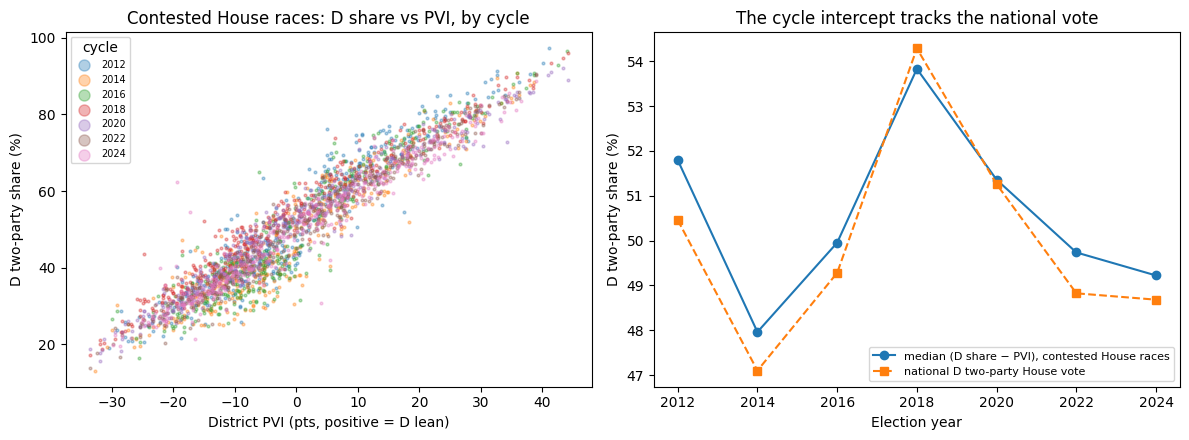

corr(cycle intercept, national vote) over 7 cycles = 0.978


In [ ]:
contested_house = results[(results.contested == 1) & (results.office == "house")]
cycle_intercept = (contested_house.dem_share - contested_house.pvi).groupby(
    contested_house.year).median()
nat_since_first = NAT_DEM_BY_YEAR.loc[FIRST_TRAIN_YEAR:]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for year, group in contested_house.groupby("year"):
    axes[0].scatter(group.pvi, group.dem_share, s=4, alpha=0.35, label=str(year))
axes[0].set(xlabel="District PVI (pts, positive = D lean)", ylabel="D two-party share (%)",
            title="Contested House races: D share vs PVI, by cycle")
axes[0].legend(markerscale=4, fontsize=7, title="cycle")
axes[1].plot(cycle_intercept.index, cycle_intercept.values, "o-",
             label="median (D share − PVI), contested House races")
axes[1].plot(nat_since_first.index, nat_since_first.values, "s--",
             label="national D two-party House vote")
axes[1].set(xlabel="Election year", ylabel="D two-party share (%)",
            title="The cycle intercept tracks the national vote")
axes[1].legend(fontsize=8)
show_figure(fig, "eda_pvi_and_cycle_intercept")
intercept_corr = np.corrcoef(cycle_intercept.values,
                             NAT_DEM_BY_YEAR.loc[cycle_intercept.index].values)[0, 1]
print(f"corr(cycle intercept, national vote) over {len(cycle_intercept)} cycles = "
      f"{intercept_corr:.3f}")

**Figure 1.** Left: within each cycle, D share is close to linear in PVI. Right: the cycle's typical offset from PVI (the median of D share − PVI) moves with the national House vote. The whole cloud on the left shifts up and down with the national environment, and defining the target relative to the national vote removes that shift.

Figure 2 compares the generic ballot with the national House vote that followed.

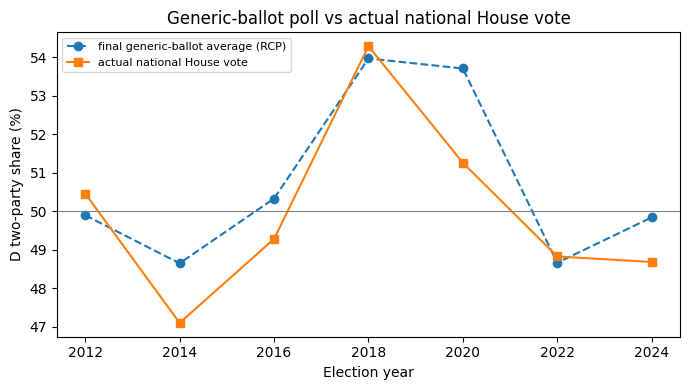

Largest miss: 2020 (-2.45 pts); misses overstating Democrats: 4 of 7 cycles


In [ ]:
history = YEAR_FACTORS.dropna(subset=["actual_nat_dem"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.index, history.poll_dem2, "o--", label="final generic-ballot average (RCP)")
ax.plot(history.index, history.actual_nat_dem, "s-", label="actual national House vote")
ax.axhline(50, color="grey", lw=0.8)
ax.set(xlabel="Election year", ylabel="D two-party share (%)",
       title="Generic-ballot poll vs actual national House vote")
ax.legend(fontsize=8)
show_figure(fig, "eda_generic_ballot_error")
worst = history.poll_error.abs().idxmax()
print(f"Largest miss: {worst} ({history.loc[worst, 'poll_error']:+.2f} pts); "
      f"misses overstating Democrats: {(history.poll_error < 0).sum()} of {len(history)} cycles")

**Figure 2.** The gap between the lines is each year's national polling error. The polls overstated Democrats in four of the seven cycles, most of all in 2020. An error like this moves every race in the same direction, which makes it the largest single source of uncertainty in the seat counts.

## 5. Model

### 5.1 Specification

**Target.** One row per contested race $i$ in cycle $t$, with target

$$y_{it} = \text{D share}_{it} - \text{national House D share}_t ,$$

the race's result relative to the national vote of its own cycle.

**Regression.** Weighted least squares on the features of Sections 3.4–3.7:

$$y_{it} = \beta_0 + \mathbf{x}_{it}'\boldsymbol{\beta} + \varepsilon_{it}, \qquad \text{with } \boldsymbol{\beta} \text{ chosen to minimise } \sum_{i,t} w_t\, \varepsilon_{it}^2 .$$

**Recency weights.** When forecasting cycle $T$, every race in training cycle $t$ gets weight

$$w_t = \delta^{\,|T - t|/2 \;-\; d_{\min}},$$

where $\delta$ = `RECENCY_DECAY` = 0.75 and $d_{\min}$ is the distance, in cycles, of the closest training cycle, which therefore gets weight 1. For 2026: 2024 → 1, 2022 → 0.75, 2020 → 0.56, 2018 → 0.42, 2016 → 0.32, 2014 → 0.24, 2012 → 0.18. In leave-one-cycle-out validation $T$ is the held-out cycle, so its neighbours on both sides count most; in forward-chaining it is the next cycle, as it is for 2026. Setting $\delta = 1$ gives ordinary least squares.

The weights affect fitting only. Every evaluation metric counts each race once, and the uncertainty model (6.3) is fitted on unweighted held-out errors, because down-weighting old cycles would leave even fewer national misses to estimate the tails from.

**National level.** The forecast adds the predicted relative share back to a national level $N_t$:

$$\widehat{\text{share}}_{it} = \operatorname{clip}\left(N_t + \hat{y}_{it},\ 1,\ 99\right), \qquad N_t = \text{generic ballot}_t + \frac{\sum_s w_s\,(\text{actual}_s - \text{poll}_s)}{\sum_s w_s + n_0},$$

where the sums run over the cycles the model was fitted on and $n_0$ = `NAT_SHRINK_N0` = 3. The second term is the recency-weighted average past polling miss, shrunk toward zero. Because the recency weights sum to less than the number of cycles, the shrinkage is stronger than it would be with equal weights. With `RECENCY_WEIGHT_NATIONAL = False` every $w_s = 1$.

**Validation: leave one cycle out (LOCO).** Grouped cross-validation with the cycle as the group: fit on six cycles, predict the seventh, and repeat for each. Both the regression and the polling-bias correction use only the six fitting cycles. Races in the same election share a national environment, so a random K-fold split would put siblings of every test race in the training set and understate the error. Section 6.2 adds a stricter forward-chaining test that trains only on earlier elections.

### 5.2 Look-ahead and leakage

| Possible leak | How it is handled |
|---|---|
| Features built from post-election information | PVI uses earlier presidential results only (crosstab in 2.3). Prior results come from the previous cycle. Scandal markers use page versions from before the cutoff. State demographics use an ACS vintage released before the election; district values are an exception (item 5 below). Race polls stop 7 days before election day in every year. Expert ratings stop 13 days before wherever an archived page exists, and no 2026 rating is dated after the forecast date. |
| The target leaking into a feature | Money is standardised within cycle using money alone. The actual national vote appears only in the target and in the polling-bias correction, which uses fitting cycles only. |
| Test cycles informing the fit | LOCO and forward-chaining refit the regression and the bias correction inside each split, with recency weights measured from that split's test cycle. The uncertainty model is refitted inside each split of the calibration backtest (6.4). |

What remains imperfect:

1. LOCO trains on later elections when predicting earlier ones. Forward-chaining removes this.
2. Historical FEC totals cover the whole cycle, including late money that follows expected competitiveness; 2026 money stops on 30 September.
3. The feature set and the judgment settings in 1.3 were chosen while looking at these same held-out results, so no number in Section 6 is a clean out-of-sample test.
4. Ratings for 2012 and the 2014–2018 House races are final ratings published after the cutoff. `rating_x_final` gives them a separate slope, so the 2026 forecast uses the slope of cutoff-time ratings, learned mostly from 2020–2024.
5. In every training year except 2020, district demographics come from the ACS of the election year, published after the election (`ALLOW_SAME_YEAR_DISTRICT_ACS`).

### 5.3 Fitting the final model

The final model is fitted on all training races with the 2026 recency weights. The first table shows the national level each past cycle would have been given, using only the other cycles' polling misses, next to the actual national vote. The coefficients follow.

In [ ]:
train = hist[hist.year >= FIRST_TRAIN_YEAR].reset_index(drop=True)
TRAIN_YEARS = sorted(train.year.unique())
LOCO_SPLITS = list(LeaveOneGroupOut().split(train, groups=train.year))
FINAL_NAME = "Linear: race-level features (final)"
FINAL_MODEL = LinearRegression()


def cycle_weights(years, target_year: int, decay: float = RECENCY_DECAY) -> np.ndarray:
    """Recency weight of each entry of `years` when forecasting `target_year`.

    Each cycle (2 years) of distance from the target multiplies the weight by `decay`; the closest
    cycle present gets weight 1. decay = 1 gives equal weights.
    """
    distance = np.abs(int(target_year) - np.asarray(years, dtype=int)) / 2
    return decay ** (distance - distance.min())


def national_anchor(year: int, fit_years, n0: float = NAT_SHRINK_N0,
                    decay: float = RECENCY_DECAY) -> float:
    """Generic-ballot D share for `year` plus the shrunken, recency-weighted mean polling error."""
    errors = YEAR_FACTORS.loc[list(fit_years), "poll_error"].dropna()
    weights = cycle_weights(errors.index, year, decay if RECENCY_WEIGHT_NATIONAL else 1.0)
    return (YEAR_FACTORS.loc[year, "poll_dem2"]
            + float((weights * errors.values).sum()) / (weights.sum() + n0))


TRAIN_WEIGHTS = cycle_weights(train.year, ELECTION_YEAR)
final_model = clone(FINAL_MODEL).fit(train[FEATURES], train.target, sample_weight=TRAIN_WEIGHTS)
fitted = final_model.predict(train[FEATURES])
weight_by_year = pd.Series(TRAIN_WEIGHTS, index=train.year.values).groupby(level=0).first()
effective_cycles = weight_by_year.sum() ** 2 / (weight_by_year ** 2).sum()
print(f"Recency weights for {ELECTION_YEAR} (RECENCY_DECAY = {RECENCY_DECAY}): "
      + ", ".join(f"{year}: {w:.2f}" for year, w in weight_by_year.items())
      + f"; effective number of cycles {effective_cycles:.1f} of {len(weight_by_year)}")
print(f"Fitted on {len(train):,} races ({TRAIN_YEARS[0]}-{TRAIN_YEARS[-1]}), {len(FEATURES)} "
      f"features; intercept {final_model.intercept_:+.2f} pts; in-sample MAE "
      f"{np.abs(train.target - fitted).mean():.3f} pts (optimistic: see Section 6 for held-out)")
print("National level by cycle (generic ballot + shrunken, recency-weighted bias from the other "
      "cycles) vs actual national vote:")
display(pd.DataFrame({
    "poll": YEAR_FACTORS.loc[TRAIN_YEARS, "poll_dem2"],
    "national level": [national_anchor(y, [c for c in TRAIN_YEARS if c != y])
                       for y in TRAIN_YEARS],
    "actual": YEAR_FACTORS.loc[TRAIN_YEARS, "actual_nat_dem"]}, index=TRAIN_YEARS).round(2))
coef_table = pd.DataFrame({"group": [GROUP_OF[c] for c in FEATURES],
                           "coefficient": final_model.coef_},
                          index=[FEATURE_LABELS[c] for c in FEATURES])
coef_table.round(3)

Recency weights for 2026 (RECENCY_DECAY = 0.75): 2012: 0.18, 2014: 0.24, 2016: 0.32, 2018: 0.42, 2020: 0.56, 2022: 0.75, 2024: 1.00; effective number of cycles 5.4 of 7
Fitted on 2,948 races (2012-2024), 46 features; intercept +1.32 pts; in-sample MAE 2.322 pts (optimistic: see Section 6 for held-out)
National level by cycle (generic ballot + shrunken, recency-weighted bias from the other cycles) vs actual national vote:


,poll,national level,actual
2012,49.89,49.35,50.46
2014,48.65,48.38,47.10
2016,50.33,49.92,49.28
2018,53.96,53.32,54.28
2020,53.70,53.46,51.26
2022,48.66,48.04,48.82
2024,49.84,49.48,48.68


,group,coefficient
"PVI (district lean, D+)",partisanship,0.458
PVI × no comparable prior result,partisanship,0.376
Senate race,partisanship,-0.314
Senate × PVI,partisanship,0.079
Prior result vs national (same lines),prior result,0.334
Prior result available,prior result,-1.061
Prior result × open seat,prior result,0.055
Senate incumbent's prior result vs national,Senate prior result,0.123
Senate prior result available,Senate prior result,-1.052
"Incumbency (+1 D, −1 R)",incumbency & seniority,1.795


**Reading the coefficients.** Each coefficient is the change in predicted D share, in pts relative to the national vote, per unit of the feature with the others held fixed. Units differ: PVI and prior results are in pts, money in standard deviations, indicators are 0/1, and signed features such as `inc` are +1 for D and −1 for R. A few things stand out.

* **Polls and ratings take over from PVI where they exist.** The PVI slope is 0.46 per point, plus 0.38 where there is no comparable prior result, which includes every Senate race. In rated races `rating_x_pvi` subtracts 0.40, and in polled Senate races `poll_x_pvi` subtracts another 0.46. In a polled, rated Senate race the net PVI slope is close to zero, and the forecast rests on the poll (0.64 per point of difference from the generic ballot) and the rating (about 1.1 pts per rating step).
* **Incumbency** is worth about 1.8 pts in the House and about 3 pts in the Senate (adding `senate_x_inc`), less in rated or polled races, where the interactions absorb part of it.
* **The scandal "unknown" flags matter more than the scandal flags.** A D candidate with no usable Wikipedia page costs about 1 pt, which more likely reflects a low-profile candidate than anything to do with scandal. The D-scandal coefficient has the wrong sign and is unstable (5.4).
* **"No D FEC money" has a positive coefficient** (+2.2). This does not mean money is irrelevant: a missing D total also pushes the money z-score toward its lower clip, and the flag partly offsets that.
* **Demographic coefficients are small,** a few hundredths of a point per point of share, but the features span wide ranges. The Hispanic share and its swing interaction have opposite signs and largely cancel at the 2026 swing.

Standard errors are not shown. Residuals are correlated within a cycle and within a state, so the usual OLS standard errors would be too small. The next section uses a cycle-level stability check instead.

### 5.4 Coefficient stability

Each coefficient is re-estimated seven times, leaving out one cycle at a time; the remaining cycles keep their 2026 weights. A coefficient whose sign or size depends heavily on which election is dropped is driven by a single cycle and should not be leaned on.

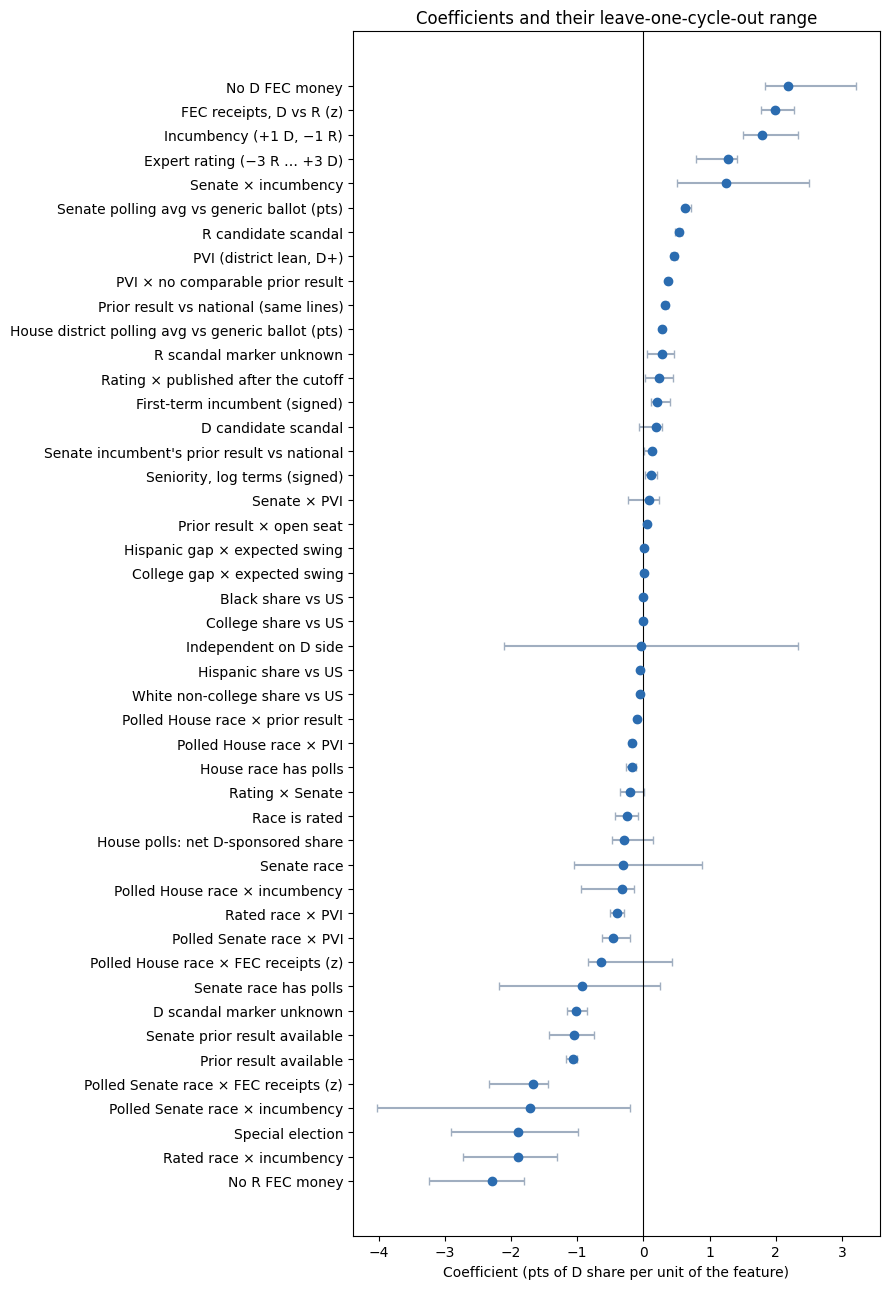

Coefficients whose sign depends on which cycle is left out: Senate race, Senate × PVI, D candidate scandal, Independent on D side, College share vs US, Black share vs US, Senate race has polls, House polls: net D-sponsored share, Polled House race × FEC receipts (z), Rating × Senate


In [ ]:
loco_coefs = pd.DataFrame(
    [clone(FINAL_MODEL).fit(train.iloc[fit_idx][FEATURES], train.target.values[fit_idx],
                            sample_weight=TRAIN_WEIGHTS[fit_idx]).coef_
     for fit_idx, _ in LOCO_SPLITS],
    columns=FEATURES, index=[f"without {train.year.iloc[test_idx[0]]}"
                             for _, test_idx in LOCO_SPLITS])
stability = pd.DataFrame({"all cycles": final_model.coef_,
                          "min": np.minimum(loco_coefs.min(), final_model.coef_),
                          "max": np.maximum(loco_coefs.max(), final_model.coef_)}, index=FEATURES)
stability["sign changes"] = (np.sign(stability["min"]) != np.sign(stability["max"]))

fig, ax = plt.subplots(figsize=(9, 0.25 * len(FEATURES) + 1.5))
order = stability["all cycles"].sort_values().index
positions = np.arange(len(order))
ax.errorbar(stability.loc[order, "all cycles"], positions,
            xerr=[stability.loc[order, "all cycles"] - stability.loc[order, "min"],
                  stability.loc[order, "max"] - stability.loc[order, "all cycles"]],
            fmt="o", color="#2b6cb0", ecolor="#a0aec0", capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(positions, [FEATURE_LABELS[c] for c in order])
ax.set(xlabel="Coefficient (pts of D share per unit of the feature)",
       title="Coefficients and their leave-one-cycle-out range")
show_figure(fig, "coefficient_stability")
print("Coefficients whose sign depends on which cycle is left out:",
      ", ".join(FEATURE_LABELS[c] for c in stability.index[stability["sign changes"]]) or "none")

**Figure 3.** Dots are the full-sample coefficients; bars span the seven leave-one-cycle-out estimates. Because the units differ, bar lengths can be compared within a feature but not across features. The core structural terms (PVI, prior result, incumbency, money, the expert rating) keep their sign whichever cycle is dropped. The features printed above as changing sign carry little reliable information on their own; Section 8 shows how much each actually moves the 2026 forecasts. Wide bars on the poll interactions are expected, since few races are polled in any one cycle.

## 6. Evaluation

### 6.1 Held-out accuracy

Each cycle is predicted by a regression and a polling-bias correction estimated from the other six cycles (LOCO, 5.1). These held-out predictions produce the tables below and are also the errors the uncertainty model is fitted on.

All metrics are in pts of D share:

* **MAE**: mean absolute error, the typical miss per race.
* **RMSE**: root mean squared error, which weights large misses more.
* **bias**: mean of actual − predicted; positive means the model underestimated Democrats.
* **R²**: share of between-race variance explained. It is high mostly because PVI separates safe D seats from safe R seats, so it says little about the races that decide control.
* **winner_acc**: share of races in which the predicted winner won.
* **competitive**: the same metrics for races with |PVI| ≤ 10, where errors matter most.

In [ ]:
def to_share(national, relative):
    """Point forecast of D share: national level plus predicted relative share, clipped."""
    return np.clip(national + relative, *SHARE_CLIP)


def held_out(estimator, frame: pd.DataFrame, features: list[str], splits,
             decay: float = RECENCY_DECAY) -> np.ndarray:
    """D-share predictions for every row in a test split (NaN elsewhere).

    The regression and the polling-bias correction are both estimated from that split's training
    cycles only, recency-weighted by distance from the split's (single) test cycle.
    """
    out = np.full(len(frame), np.nan)
    for fit_idx, test_idx in splits:
        fit, test = frame.iloc[fit_idx], frame.iloc[test_idx]
        require(test.year.nunique() == 1, "each test split must hold a single cycle")
        test_year = int(test.year.iloc[0])
        model = clone(estimator).fit(fit[features], fit.target,
                                     sample_weight=cycle_weights(fit.year, test_year, decay))
        national = national_anchor(test_year, sorted(fit.year.unique()), decay=decay)
        out[test_idx] = to_share(national, model.predict(test[features]))
    return out


def score_predictions(actual, predicted) -> pd.Series:
    """Accuracy metrics for predicted vs actual D share (both in %)."""
    error = actual - predicted
    return pd.Series({
        "n": len(error),
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
        "bias": error.mean(),
        "R2": r2_score(actual, predicted),
        "winner_acc": ((actual > 50) == (predicted > 50)).mean(),
    })


def metrics_by_year(frame: pd.DataFrame, pred_col: str = "pred") -> pd.DataFrame:
    """score_predictions per cycle plus a pooled row, for all races and competitive races."""
    def by_year(rows):
        table = rows.groupby("year")[["dem_share", pred_col]].apply(
            lambda g: score_predictions(g.dem_share, g[pred_col]))
        table.loc["pooled"] = score_predictions(rows.dem_share, rows[pred_col])
        return table
    return pd.concat({"all": by_year(frame),
                      "competitive": by_year(frame[frame.competitive == 1])}, axis=1)


oos = train.copy()                                   # held-out ("out-of-sample") predictions
oos["pred"] = held_out(FINAL_MODEL, train, FEATURES, LOCO_SPLITS)
oos_metrics = metrics_by_year(oos)
oos_metrics.round(3)

all                                        competitive                                       
             n    MAE   RMSE   bias     R2 winner_acc           n    MAE   RMSE   bias     R2 winner_acc
year                                                                                                    
2012     421.0  3.535  4.562  1.898  0.927      0.950       226.0  3.440  4.480  1.553  0.809      0.920
2014     394.0  2.686  3.340 -0.431  0.958      0.970       198.0  2.703  3.350 -0.763  0.889      0.939
2016     404.0  3.011  3.858 -0.426  0.950      0.985       199.0  2.684  3.537 -1.005  0.887      0.970
2018     419.0  2.443  3.102  0.166  0.961      0.955       190.0  2.343  3.032  0.388  0.826      0.911
2020     441.0  3.157  3.754 -2.976  0.948      0.921       195.0  3.432  3.878 -3.306  0.707      0.831
2022     436.0  2.452  3.284  0.889  0.958      0.943       180.0  2.488  3.527  1.043  0.780      0.861
2024     433.0  1.920  2.801 -0.174  0.967      0.961       176.0  1.816  2.564 -0.365  0.868      0.915
pooled  2948.0  2.741  3.567 -0.161  0.953      0.954      1364.0  2.734  3.564 -0.328  0.845      0.908

**Table 1. Held-out accuracy by cycle (LOCO).** Each row is a cycle predicted by a model that never saw it. The pooled bias is close to zero, but individual cycles are not: the model underestimated Democrats by 1.9 pts in 2012 and overestimated them by 3.0 pts in 2020, largely because the national level was off in those years (compare the national-level table in 5.3). Errors within a cycle move together, which is why the seat counts later in this section are much noisier than the race-level error suggests.

The figure compares each held-out prediction with the result.

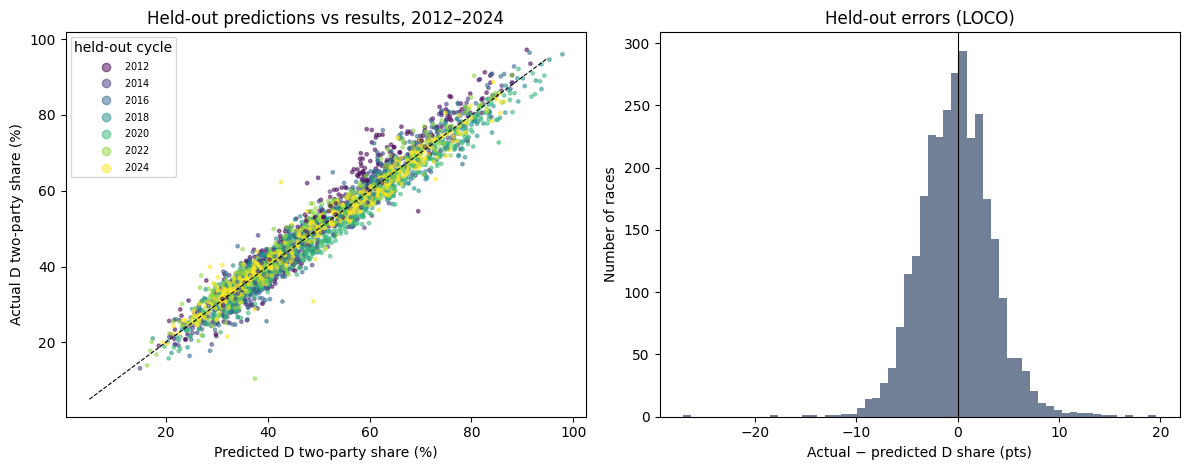

Pooled held-out MAE 2.74 pts, RMSE 3.57 pts, bias -0.16 pts; excess kurtosis of errors 2.31 (0 for a normal distribution)


In [ ]:
residuals = oos.dem_share - oos.pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
points = axes[0].scatter(oos.pred, oos.dem_share, c=oos.year, cmap="viridis", s=6, alpha=0.5)
axes[0].plot([5, 95], [5, 95], "k--", lw=0.8, label="perfect prediction")
axes[0].legend(*points.legend_elements(), fontsize=7, title="held-out cycle")
axes[0].set(xlabel="Predicted D two-party share (%)", ylabel="Actual D two-party share (%)",
            title=f"Held-out predictions vs results, {TRAIN_YEARS[0]}–{TRAIN_YEARS[-1]}")
axes[1].hist(residuals, bins=60, color="#718096")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set(xlabel="Actual − predicted D share (pts)", ylabel="Number of races",
            title="Held-out errors (LOCO)")
show_figure(fig, "oos_predictions")
print(f"Pooled held-out MAE {np.abs(residuals).mean():.2f} pts, "
      f"RMSE {np.sqrt((residuals ** 2).mean()):.2f} pts, bias {residuals.mean():+.2f} pts; "
      f"excess kurtosis of errors {stats.kurtosis(residuals):.2f} (0 for a normal distribution)")

**Figure 4.** Left: held-out predictions against results, coloured by cycle. Right: the error distribution. Its excess kurtosis is positive, meaning heavier tails than a normal distribution, which is why the race-level errors in the simulation are drawn from a Student-t (6.3).

### 6.2 Baselines, ablations and a forward-in-time test

Does the model earn its features? It is compared with simpler models that predict the same target, use the same recency weights and national level (except where noted), and are scored the same way.

| Model | What it does |
|---|---|
| National level only | Every race lands at the national level plus the mean relative share of the training races (a constant model). |
| Uniform swing | Carries forward the race's previous result relative to its cycle's national vote; where there is none, a regression on PVI and incumbency. A standard political-science baseline. |
| Linear: PVI + incumbency | OLS on two features. |
| Linear: without demographics / race polls / House polls / expert ratings | Ablations: the final model with one block of features removed (shown only if the block is in use). |
| Linear: equal cycle weights | The final model with `RECENCY_DECAY` = 1, so every cycle counts the same in the regression and the bias correction. |
| Linear: race-level features (final) | The model used for the forecast. |

Two validation schemes:

* **Leave-one-cycle-out**, all seven cycles, as in 6.1.
* **Forward-chaining**: to predict cycle $t$, train only on earlier cycles, so 2016–2024 are predicted from a growing history. This is closer to the real forecasting situation.

Besides vote-share error, the table reports **mean |House seat error|**: predicted minus actual D wins among each tested cycle's contested House races, averaged in absolute value over cycles.

In [ ]:
class UniformSwing(BaseEstimator, RegressorMixin):
    """Carry the prior result (vs national) forward; PVI + incumbency where there is none."""

    def fit(self, X, y, sample_weight=None):
        y = np.asarray(y, float)
        w = np.ones(len(y)) if sample_weight is None else np.asarray(sample_weight, float)
        lag = X["lag_avail"].values == 1
        self.ols_ = LinearRegression().fit(X.loc[~lag, ["pvi", "inc"]], y[~lag],
                                           sample_weight=w[~lag])
        self.offset_ = (float(np.average(y[lag] - X.loc[lag, "lag_rel_f"].values,
                                         weights=w[lag])) if lag.any() else 0.0)
        return self

    def predict(self, X):
        out = self.ols_.predict(X[["pvi", "inc"]])
        lag = X["lag_avail"].values == 1
        out[lag] = X.loc[lag, "lag_rel_f"].values + self.offset_
        return out


NO_DEMO_NAME = "Linear: without demographics"
NO_POLL_NAME = "Linear: without race polls"
NO_HOUSE_POLL_NAME = "Linear: without House polls"
NO_RATING_NAME = "Linear: without expert ratings"
EQUAL_WEIGHT_NAME = "Linear: equal cycle weights"
ABLATION_NAMES = [NO_DEMO_NAME, NO_POLL_NAME, NO_HOUSE_POLL_NAME, NO_RATING_NAME,
                  EQUAL_WEIGHT_NAME]
BASELINES = {
    "National level only": (DummyRegressor(strategy="mean"), FEATURES),
    "Uniform swing": (UniformSwing(), ["pvi", "inc", "lag_rel_f", "lag_avail"]),
    "Linear: PVI + incumbency": (LinearRegression(), ["pvi", "inc"]),
}
if DEMO_FEATURES:
    BASELINES[NO_DEMO_NAME] = (LinearRegression(),
                               [f for f in FEATURES if f not in DEMO_FEATURES])
if POLL_FEATURES_IN_USE:
    BASELINES[NO_POLL_NAME] = (LinearRegression(),
                               [f for f in FEATURES if f not in POLL_FEATURES_IN_USE])
if HOUSE_FEATURES_IN_USE:
    BASELINES[NO_HOUSE_POLL_NAME] = (LinearRegression(),
                                     [f for f in FEATURES if f not in HOUSE_FEATURES_IN_USE])
if RATING_FEATURES_IN_USE:
    BASELINES[NO_RATING_NAME] = (LinearRegression(),
                                 [f for f in FEATURES if f not in RATING_FEATURES_IN_USE])
BASELINES[EQUAL_WEIGHT_NAME] = (FINAL_MODEL, FEATURES)
BASELINES[FINAL_NAME] = (FINAL_MODEL, FEATURES)
BASELINE_DECAY = {EQUAL_WEIGHT_NAME: 1.0}    # every other model uses RECENCY_DECAY
FORWARD_SPLITS = [(np.flatnonzero(train.year < year), np.flatnonzero(train.year == year))
                  for year in FORWARD_TEST_YEARS]
SCHEMES = {"leave-one-cycle-out": LOCO_SPLITS, "forward-chaining": FORWARD_SPLITS}


def house_seat_error(frame: pd.DataFrame, pred: np.ndarray) -> tuple[float, pd.Series]:
    """Mean |predicted - actual D wins| in contested House races, over the tested cycles."""
    tested = frame.assign(pred=pred).dropna(subset=["pred"])
    house = tested[tested.office == "house"]
    errors = ((house.pred > 50).groupby(house.year).sum()
              - (house.dem_share > 50).groupby(house.year).sum())
    return errors.abs().mean(), errors


def compare_models(models: dict, frame: pd.DataFrame, schemes: dict, precomputed=None):
    """Score every model under every validation scheme (pooled over the tested races)."""
    precomputed = precomputed or {}
    rows, seat_errors = [], {}
    for scheme, splits in schemes.items():
        for name, (estimator, features) in models.items():
            pred = precomputed.get((scheme, name))
            if pred is None:
                pred = held_out(estimator, frame, features, splits,
                                decay=BASELINE_DECAY.get(name, RECENCY_DECAY))
            tested = ~np.isnan(pred)
            scores = score_predictions(frame.dem_share.values[tested], pred[tested])
            competitive = tested & (frame.competitive.values == 1)
            scores["MAE, competitive"] = np.abs(frame.dem_share.values[competitive]
                                                - pred[competitive]).mean()
            scores["mean |House seat error|"], seat_errors[(scheme, name)] = house_seat_error(
                frame, pred)
            rows.append({"scheme": scheme, "model": name, **scores})
    return pd.DataFrame(rows).set_index(["scheme", "model"]), pd.DataFrame(seat_errors).T


baseline_table, seat_error_table = compare_models(
    BASELINES, train, SCHEMES,
    precomputed={("leave-one-cycle-out", FINAL_NAME): oos.pred.values})  # reuse 6.1
display(baseline_table.round(3))
print("House seat error by cycle, forward-chaining (predicted - actual D wins, contested races):")
seat_error_table.loc["forward-chaining"].dropna(axis=1, how="all")

n     MAE    RMSE   bias     R2  winner_acc  MAE, competitive  mean |House seat error|
scheme              model                                                                                                                           
leave-one-cycle-out National level only                  2948.0  13.883  16.387 -0.172 -0.002       0.528             7.539                  182.857
                    Uniform swing                        2948.0   3.133   4.244 -0.256  0.933       0.945             3.330                    7.571
                    Linear: PVI + incumbency             2948.0   3.304   4.365 -0.214  0.929       0.951             3.414                   10.000
                    Linear: without demographics         2948.0   2.706   3.546 -0.176  0.953       0.955             2.741                   11.143
                    Linear: without race polls           2948.0   2.800   3.625 -0.162  0.951       0.955             2.805                   11.857
                    Linear: without House polls          2948.0   2.781   3.601 -0.163  0.952       0.953             2.781                   11.714
                    Linear: without expert ratings       2948.0   2.812   3.681 -0.187  0.949       0.953             2.817                    8.714
                    Linear: equal cycle weights          2948.0   2.779   3.608 -0.222  0.951       0.956             2.770                    9.857
                    Linear: race-level features (final)  2948.0   2.741   3.567 -0.161  0.953       0.954             2.734                   11.571
forward-chaining    National level only                  2133.0  13.806  16.257 -0.506 -0.006       0.488             6.950                  201.200
                    Uniform swing                        2133.0   2.958   4.046 -0.632  0.938       0.946             3.104                    7.200
                    Linear: PVI + incumbency             2133.0   3.194   4.203 -0.891  0.933       0.952             3.265                    9.800
                    Linear: without demographics         2133.0   2.655   3.516 -0.813  0.953       0.949             2.631                   12.000
                    Linear: without race polls           2133.0   2.741   3.594 -0.750  0.951       0.947             2.684                   14.200
                    Linear: without House polls          2133.0   2.735   3.604 -0.776  0.951       0.949             2.655                   13.400
                    Linear: without expert ratings       2133.0   2.749   3.659 -0.695  0.949       0.953             2.697                    9.200
                    Linear: equal cycle weights          2133.0   2.746   3.601 -0.906  0.951       0.949             2.626                   12.600
                    Linear: race-level features (final)  2133.0   2.684   3.550 -0.776  0.952       0.950             2.589                   13.400

House seat error by cycle, forward-chaining (predicted - actual D wins, contested races):


year,2016,2018,2020,2022,2024
National level only,213.0,192.0,204.0,-200.0,-197.0
Uniform swing,1.0,-27.0,2.0,-1.0,5.0
Linear: PVI + incumbency,-2.0,-23.0,16.0,-4.0,-4.0
Linear: without demographics,0.0,-12.0,31.0,-12.0,-5.0
Linear: without race polls,1.0,-8.0,37.0,-18.0,-7.0
Linear: without House polls,1.0,-9.0,35.0,-16.0,-6.0
Linear: without expert ratings,-2.0,-21.0,22.0,-1.0,0.0
Linear: equal cycle weights,1.0,-12.0,37.0,-8.0,-5.0
Linear: race-level features (final),1.0,-10.0,37.0,-13.0,-6.0


**Table 2. Model comparison.** Within a scheme every row is scored on the same races. The forward-chaining rows, which are the more realistic test:

* **Vote share.** The final model has the lowest MAE (2.68 pts), 0.27 pts better than uniform swing, the best simple baseline. Race polls and expert ratings each improve it by about 0.06 pts.
* **Seat counts.** The final model is worse than uniform swing here: an average miss of 13.4 seats against 7.2. Most of the gap comes from 2020, when the final model over-predicted Democratic House seats by 37 against uniform swing's 2, and from 2022 (−13 against −1). In 2018 uniform swing missed by more (−27 against −10). Seat totals are dominated by the national miss and by one or two cycles, so this column is noisy, but it is a reason not to read the seat forecast as more precise than the vote-share forecast. Removing the expert ratings raises MAE but lowers the seat error (9.2).
* **Demographics** do not help: removing them lowers MAE (2.684 → 2.655) and the seat error (13.4 → 12.0). Only competitive-race MAE is slightly better with them.
* **Recency weights** lower MAE a little (2.75 → 2.68) and raise the seat error (12.6 → 13.4).

The leave-one-cycle-out rows tell the same story. Differences of a few hundredths of a point are within what a different set of seven elections could produce.

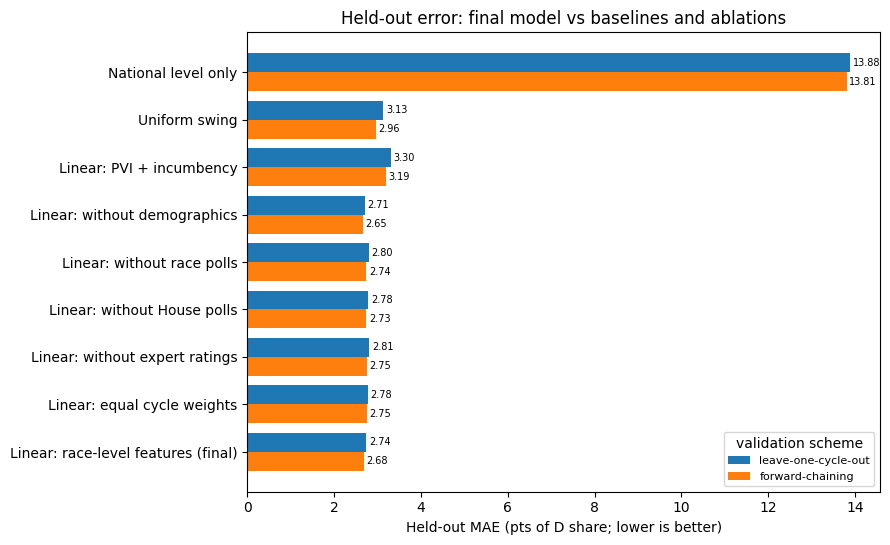

leave-one-cycle-out: final model MAE 2.74 pts vs best simple baseline 3.13 pts (0.39 pts better)
forward-chaining: final model MAE 2.68 pts vs best simple baseline 2.96 pts (0.27 pts better)

'Linear: without demographics' -> final model:
  leave-one-cycle-out  MAE 2.706 -> 2.741; competitive MAE 2.741 -> 2.734; mean |House seat error| 11.1 -> 11.6
  forward-chaining     MAE 2.655 -> 2.684; competitive MAE 2.631 -> 2.589; mean |House seat error| 12.0 -> 13.4

'Linear: without race polls' -> final model:
  leave-one-cycle-out  MAE 2.800 -> 2.741; competitive MAE 2.805 -> 2.734; mean |House seat error| 11.9 -> 11.6
  forward-chaining     MAE 2.741 -> 2.684; competitive MAE 2.684 -> 2.589; mean |House seat error| 14.2 -> 13.4

'Linear: without House polls' -> final model:
  leave-one-cycle-out  MAE 2.781 -> 2.741; competitive MAE 2.781 -> 2.734; mean |House seat error| 11.7 -> 11.6
  forward-chaining     MAE 2.735 -> 2.684; competitive MAE 2.655 -> 2.589; mean |House seat error| 13.4 -> 1

In [ ]:
mae_wide = baseline_table.MAE.unstack("scheme").loc[list(BASELINES)]
fig, ax = plt.subplots(figsize=(9, 0.45 * len(mae_wide) + 1.5))
positions = np.arange(len(mae_wide))
for offset, scheme in zip([-0.2, 0.2], SCHEMES):
    bars = ax.barh(positions + offset, mae_wide[scheme], height=0.4, label=scheme)
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax.set_yticks(positions, mae_wide.index)
ax.invert_yaxis()
ax.set(xlabel="Held-out MAE (pts of D share; lower is better)", ylabel="",
       title="Held-out error: final model vs baselines and ablations")
ax.legend(title="validation scheme", fontsize=8)
show_figure(fig, "baseline_comparison")

best_simple = mae_wide.drop(index=[FINAL_NAME, *ABLATION_NAMES], errors="ignore").min()
for scheme in SCHEMES:
    gain = best_simple[scheme] - mae_wide.loc[FINAL_NAME, scheme]
    print(f"{scheme}: final model MAE {mae_wide.loc[FINAL_NAME, scheme]:.2f} pts vs best simple "
          f"baseline {best_simple[scheme]:.2f} pts ({abs(gain):.2f} pts "
          f"{'better' if gain > 0 else 'worse'})")
for name in ABLATION_NAMES:
    if name in BASELINES:
        print(f"\n'{name}' -> final model:")
        for scheme in SCHEMES:
            before = baseline_table.loc[(scheme, name)]
            after = baseline_table.loc[(scheme, FINAL_NAME)]
            print(f"  {scheme:<20} MAE {before.MAE:.3f} -> {after.MAE:.3f}; competitive MAE "
                  f"{before['MAE, competitive']:.3f} -> {after['MAE, competitive']:.3f}; "
                  f"mean |House seat error| {before['mean |House seat error|']:.1f} -> "
                  f"{after['mean |House seat error|']:.1f}")

**Figure 5.** Held-out MAE under both schemes. The printed lines give the exact differences between the final model, the best simple baseline and each ablation.

**Where race polls help.** Polls cover a minority of races, so their effect is diluted in the pooled table. The next cell scores the model with and without the poll features on the races where polls can matter, and shows how the raw polling average would have done on its own.

In [ ]:
def subset_scores(name: str, splits, scheme: str, masks: dict) -> list[dict]:
    """Held-out scores of model `name` on each boolean race subset in `masks`."""
    estimator, features = BASELINES[name]
    pred = (oos.pred.values if (scheme, name) == ("leave-one-cycle-out", FINAL_NAME)
            else held_out(estimator, train, features, splits,
                          decay=BASELINE_DECAY.get(name, RECENCY_DECAY)))
    rows = []
    for subset, mask in masks.items():
        m = mask & ~np.isnan(pred)
        s = score_predictions(train.dem_share.values[m], pred[m])
        rows.append({"scheme": scheme, "races": subset, "model": name, "n": int(s.n),
                     "MAE": s.MAE, "RMSE": s.RMSE, "winner_acc": s.winner_acc})
    return rows


poll_rows = []
is_senate = train.senate.values == 1
if SENATE_FEATURES_IN_USE:
    masks = {"all Senate": is_senate,
             "polled Senate": is_senate & (train.sen_poll_avail.values == 1)}
    for scheme, splits in SCHEMES.items():
        for name in [NO_POLL_NAME, FINAL_NAME]:
            poll_rows += subset_scores(name, splits, scheme, masks)
if HOUSE_FEATURES_IN_USE:
    masks = {"competitive House": ~is_senate & (train.competitive.values == 1),
             "polled House": ~is_senate & (train.house_poll_avail.values == 1)}
    for scheme, splits in SCHEMES.items():
        for name in [NO_HOUSE_POLL_NAME, FINAL_NAME]:
            poll_rows += subset_scores(name, splits, scheme, masks)
if poll_rows:
    display(pd.DataFrame(poll_rows).set_index(["scheme", "races", "model"]).round(3))
    for label, avail, avg in [("Senate", "sen_poll_avail", "sen_poll_avg"),
                              ("House", "house_poll_avail", "house_poll_avg")]:
        if avail in train:
            polled = train[train[avail] == 1]
            err = polled.dem_share - polled[avg]
            print(f"{label}: raw polling average alone on {len(polled)} polled training races: "
                  f"MAE {err.abs().mean():.2f} pts, bias (actual - poll) {err.mean():+.2f} pts")
    for feature in ["sen_poll_rel", "house_poll_rel", "house_poll_partisan"]:
        if feature in FEATURES:
            print(f"{FEATURE_LABELS[feature]}: coefficient "
                  f"{final_model.coef_[FEATURES.index(feature)]:+.3f}")
else:
    print("No race-poll features are in use.")

n    MAE   RMSE  winner_acc
scheme              races             model                                                              
leave-one-cycle-out all Senate        Linear: without race polls            232  3.194  4.441       0.927
                    polled Senate     Linear: without race polls            195  2.983  3.970       0.913
                    all Senate        Linear: race-level features (final)   232  2.826  4.037       0.914
                    polled Senate     Linear: race-level features (final)   195  2.436  3.184       0.908
forward-chaining    all Senate        Linear: without race polls            167  3.104  4.316       0.910
                    polled Senate     Linear: without race polls            137  2.900  3.862       0.891
                    all Senate        Linear: race-level features (final)   167  2.856  4.254       0.928
                    polled Senate     Linear: race-level features (final)   137  2.335  3.081       0.927
leave-one-cycle-out competitive House Linear: without House polls          1231  2.793  3.545       0.909
                    polled House      Linear: without House polls           462  2.792  3.453       0.816
                    competitive House Linear: race-level features (final)  1231  2.745  3.511       0.912
                    polled House      Linear: race-level features (final)   462  2.616  3.260       0.820
forward-chaining    competitive House Linear: without House polls           849  2.659  3.375       0.895
                    polled House      Linear: without House polls           330  2.685  3.326       0.803
                    competitive House Linear: race-level features (final)   849  2.601  3.331       0.894
                    polled House      Linear: race-level features (final)   330  2.522  3.162       0.791

Senate: raw polling average alone on 195 polled training races: MAE 2.63 pts, bias (actual - poll) -1.37 pts
House: raw polling average alone on 462 polled training races: MAE 3.31 pts, bias (actual - poll) -0.54 pts
Senate polling avg vs generic ballot (pts): coefficient +0.636
House district polling avg vs generic ballot (pts): coefficient +0.286
House polls: net D-sponsored share: coefficient -0.287


In polled Senate races the poll features cut MAE by about half a point under both schemes (2.98 → 2.44 under LOCO, 2.90 → 2.34 forward-chaining), and under LOCO the model beats the raw polling average on the same races (2.63) by about 0.2 pts. Part of that edge is a level correction: in this window the raw Senate average overstated Democrats by 1.4 pts on average. In the House the gain is smaller (2.79 → 2.62 in polled races) and the raw polls are worse (3.31), as one would expect from sparse and often partisan polling. A poll coefficient below 1 means the model trusts a poll only partially, and the negative `house_poll_partisan` coefficient means D-sponsored House polls are discounted.

### 6.3 The uncertainty model

A point forecast says nothing about how likely each candidate is to win. The simulation adds three independent errors to each race's point forecast, a standard random-effects structure:

$$\text{simulated share}_i = \widehat{\text{share}}_i + \varepsilon_{\text{shared}} + \varepsilon_{\text{state}(i)} + \varepsilon_i, \qquad \text{clipped to } [0.5,\ 99.5].$$

| Term | Shared by |
|---|---|
| $\varepsilon_{\text{shared}}$ | Every race in the cycle |
| $\varepsilon_{\text{state}}$ | Races in the same state and cycle |
| $\varepsilon_i$ | One race |

The shared term covers the national polling miss plus any common shift in how races sit relative to the national vote. The parameters are estimated with every held-out race counted once, not recency-weighted: the tails are set by rare misses, and down-weighting old cycles would leave even fewer of them.

Each race's simulations are summarised as a win probability, P(D share > 50), and an 80% interval (10th to 90th percentile). The probabilities are scored with:

* **Brier score**: mean squared difference between P(D win) and the 0/1 outcome. Lower is better; always saying 50% scores 0.25.
* **Log loss**: mean negative log-likelihood of the outcomes, with probabilities clipped to [0.001, 0.999].
* **80% coverage**: share of results inside their 80% intervals. The target is 0.80.

In [ ]:
RACE_ERROR_DF_GRID = [3, 4, 5, 6, 8, 10, 15, 30, 1000]   # 1000 stands for "normal"


def race_category(frame: pd.DataFrame) -> np.ndarray:
    """Race type that sets the race-specific error SD."""
    polled = frame["sen_poll_avail"] if "sen_poll_avail" in frame else 0
    return np.select([(frame.senate == 1) & (polled == 1), frame.senate == 1, frame.inc == 0,
                      frame.lag_avail == 1],
                     ["senate_polled", "senate", "house_open", "house_inc_lag"], "house_inc_nolag")


def fit_uncertainty(held_out_frame: pd.DataFrame) -> dict:
    """Estimate shared, state and race-level error parameters from held-out errors."""
    o = held_out_frame.copy()
    o["err"] = o.dem_share - o.pred
    year_mean = o.groupby("year").err.mean()
    sd_common = max(float(np.sqrt((year_mean ** 2).mean())), NATIONAL_SD_FLOOR)

    o["e1"] = o.err - o.groupby("year").err.transform("mean")      # remove the shared miss
    by_state = o.groupby(["year", "state"]).e1
    n_state, mean_state = by_state.transform("size"), by_state.transform("mean")
    multi = n_state >= 2
    within_var = (((o.e1 - mean_state)[multi] ** 2).sum()
                  / (o[multi].groupby(["year", "state"]).size() - 1).sum())
    state_means = o[multi].groupby(["year", "state"]).agg(m=("e1", "mean"), n=("e1", "size"))
    sigma_state = float(np.sqrt(max((state_means.m ** 2 - within_var / state_means.n).mean(),
                                    0.0)))

    o["cat"] = race_category(o)
    # Race-type SD net of the state component; the variance floor of 0.25 keeps it >= 0.5 pts
    sigma_cat = o.groupby("cat").e1.apply(
        lambda e: float(np.sqrt(max((e ** 2).mean() - sigma_state ** 2, 0.25)))).to_dict()
    z = o.e1 / np.sqrt(o.cat.map(sigma_cat) ** 2 + sigma_state ** 2)
    log_lik = {nu: stats.t.logpdf(z, nu, scale=np.sqrt((nu - 2) / nu)).sum()
               for nu in RACE_ERROR_DF_GRID}
    return {"sd_common": sd_common, "sigma_state": sigma_state, "sigma_cat": sigma_cat,
            "df": max(log_lik, key=log_lik.get), "n_resid": len(o)}


def t_scaled(rng: np.random.Generator, df: float, size) -> np.ndarray:
    """Student-t draws rescaled to unit variance (normal when df is very large)."""
    if df >= 1000:
        return rng.standard_normal(size)
    return rng.standard_t(df, size) * np.sqrt((df - 2) / df)


def simulate_shares(frame: pd.DataFrame, unc: dict, n_sims: int, rng: np.random.Generator,
                    extra_common_sd: float = 0.0) -> np.ndarray:
    """Simulated D shares, shape (n_sims, n_races), with shared, state and race errors."""
    sd_common = np.sqrt(unc["sd_common"] ** 2 + extra_common_sd ** 2)
    common = sd_common * t_scaled(rng, COMMON_ERROR_DF, n_sims)
    state_codes, state_idx = np.unique(frame.state.values, return_inverse=True)
    state = unc["sigma_state"] * rng.standard_normal((n_sims, len(state_codes)))
    categories = pd.Series(race_category(frame))
    unknown = set(categories) - set(unc["sigma_cat"])
    require(not unknown, f"no fitted error SD for race type(s) {sorted(unknown)}")
    sigma = categories.map(unc["sigma_cat"]).values
    race = t_scaled(rng, unc["df"], (n_sims, len(frame))) * sigma
    shares = frame.pred.values[None, :] + common[:, None] + state[:, state_idx] + race
    return np.clip(shares, *SIM_CLIP)


def prob_summary(frame: pd.DataFrame, sims: np.ndarray,
                 interval: float = INTERVAL) -> pd.DataFrame:
    """Add each race's P(D win) and central prediction interval to `frame`."""
    tail = (1 - interval) / 2
    out = frame.copy()
    out["p_dem_win"] = (sims > 50).mean(axis=0)
    out["lo"] = np.percentile(sims, 100 * tail, axis=0)
    out["hi"] = np.percentile(sims, 100 * (1 - tail), axis=0)
    return out


def prob_metrics(summary: pd.DataFrame) -> pd.Series:
    """Brier score, log loss and interval coverage for probabilistic forecasts."""
    won = (summary.dem_share > 50).astype(int)
    p = summary.p_dem_win.clip(1e-3, 1 - 1e-3)
    covered = (summary.dem_share >= summary.lo) & (summary.dem_share <= summary.hi)
    return pd.Series({"n": len(summary), "Brier": ((p - won) ** 2).mean(),
                      "log loss": -(won * np.log(p) + (1 - won) * np.log(1 - p)).mean(),
                      f"{INTERVAL:.0%} coverage": covered.mean(),
                      f"mean {INTERVAL:.0%} width (pts)": (summary.hi - summary.lo).mean()})

### 6.4 Calibration backtest

Are the probabilities and seat ranges trustworthy? A forecast is calibrated if races given a 70% chance are won about 70% of the time, about 80% of results fall inside their 80% intervals, and the actual House seat count falls inside its simulated 80% range in about four cycles out of five.

Each past cycle is forecast the way 2026 is:

1. Choose the fitting cycles: all others for LOCO, only earlier ones for forward-chaining.
2. Fit the error parameters on held-out errors within the fitting cycles (an inner LOCO), so the test cycle never informs its own uncertainty.
3. Fit the regression on the fitting cycles, recency-weighted from the test cycle, and predict the test cycle.
4. Simulate `N_SIMS_BACKTEST` elections of the test cycle and score them.

In [ ]:
def probabilistic_backtest(frame: pd.DataFrame, scheme: str, n_sims: int):
    """Probabilistic forecasts for each held-out cycle, using only that split's fitting cycles."""
    years = sorted(frame.year.unique())
    test_years = years if scheme == "leave-one-cycle-out" else FORWARD_TEST_YEARS
    pieces, seats = [], []
    for t in test_years:
        fit_years = [y for y in years if (y != t if scheme == "leave-one-cycle-out" else y < t)]
        fit = frame[frame.year.isin(fit_years)].reset_index(drop=True)
        inner = list(LeaveOneGroupOut().split(fit, groups=fit.year))
        unc = fit_uncertainty(fit.assign(pred=held_out(FINAL_MODEL, fit, FEATURES, inner)))
        model = clone(FINAL_MODEL).fit(fit[FEATURES], fit.target,
                                       sample_weight=cycle_weights(fit.year, t))
        cycle = frame[frame.year == t].reset_index(drop=True).copy()
        cycle["pred"] = to_share(national_anchor(t, fit_years), model.predict(cycle[FEATURES]))
        sims = simulate_shares(cycle, unc, n_sims, np.random.default_rng(SEED + int(t)))
        pieces.append(prob_summary(cycle, sims))
        house = (cycle.office == "house").values
        sim_seats = (sims[:, house] > 50).sum(axis=1)
        actual = int((cycle.dem_share.values[house] > 50).sum())
        lo, hi = np.percentile(sim_seats, [10, 90])
        seats.append({"scheme": scheme, "year": t, "actual D wins (contested House)": actual,
                      "simulated median": np.median(sim_seats), "80% range": f"{lo:.0f}-{hi:.0f}",
                      "inside 80% range": bool(lo <= actual <= hi),
                      "shared SD": unc["sd_common"], "state SD": unc["sigma_state"],
                      "largest race SD": max(unc["sigma_cat"].values()),
                      "race error df": unc["df"]})
    return pd.concat(pieces, ignore_index=True), pd.DataFrame(seats).set_index(["scheme", "year"])


def calibration_by_year(summary: pd.DataFrame) -> pd.DataFrame:
    """prob_metrics per cycle plus a pooled row."""
    table = summary.groupby("year")[["dem_share", "p_dem_win", "lo", "hi"]].apply(prob_metrics)
    table.loc["pooled"] = prob_metrics(summary)
    return table


prob_backtest, seat_check_loco = probabilistic_backtest(train, "leave-one-cycle-out",
                                                        N_SIMS_BACKTEST)
prob_forward, seat_check_fwd = probabilistic_backtest(train, "forward-chaining", N_SIMS_BACKTEST)
calibration_table = calibration_by_year(prob_backtest)
calibration_forward = calibration_by_year(prob_forward)
print("Leave-one-cycle-out calibration:")
display(calibration_table.round(3))
print("Forward-chaining calibration:")
display(calibration_forward.round(3))
seat_check = pd.concat([seat_check_loco, seat_check_fwd])
print("House seat counts vs their simulated distributions:")
seat_check.round(3)

Leave-one-cycle-out calibration:


,n,Brier,log loss,80% coverage,mean 80% width (pts)
year,,,,,
2012,421.0,0.034,0.114,0.746,9.774
2014,394.0,0.022,0.071,0.850,9.338
2016,404.0,0.016,0.057,0.792,9.258
2018,419.0,0.032,0.108,0.876,9.712
2020,441.0,0.050,0.147,0.805,9.862
2022,436.0,0.039,0.121,0.927,11.095
2024,433.0,0.028,0.094,0.952,10.022
pooled,2948.0,0.032,0.103,0.850,9.881


Forward-chaining calibration:


,n,Brier,log loss,80% coverage,mean 80% width (pts)
year,,,,,
2016,404.0,0.020,0.077,0.918,13.649
2018,419.0,0.085,0.312,1.000,48.976
2020,441.0,0.057,0.172,0.878,12.604
2022,436.0,0.039,0.123,0.929,11.365
2024,433.0,0.028,0.094,0.952,10.022
pooled,2133.0,0.046,0.156,0.935,19.169


House seat counts vs their simulated distributions:


actual D wins (contested House)  simulated median 80% range  inside 80% range  shared SD  state SD  largest race SD  race error df
scheme              year                                                                                                                                    
leave-one-cycle-out 2012                              181             169.0   154-189              True      2.250     1.974            5.814              6
                    2014                              147             144.0   131-157              True      2.250     1.951            6.521              8
                    2016                              159             161.0   151-174              True      2.250     1.537            6.595              6
                    2018                              195             184.0   167-204              True      2.250     2.062            7.095              8
                    2020                              203             235.0   215-253             False      2.250     2.016            7.238              8
                    2022                              200             187.0   167-206              True      2.250     1.621            4.558             10
                    2024                              197             191.0   174-209              True      2.250     2.063            6.782             10
forward-chaining    2016                              159             165.0   153-180              True      2.250     2.873           16.620             10
                    2018                              195             204.5   178-229              True      2.454    12.500           47.597              3
                    2020                              203             235.0   208-257             False      2.250     2.656            8.324              8
                    2022                              200             187.0   168-208              True      2.250     1.844            5.225             15
                    2024                              197             191.0   174-209              True      2.250     2.063            6.782             10

**Reading the tables.**

* **Race-level intervals are somewhat too wide.** Pooled LOCO coverage is 0.85 against a target of 0.80, and 0.93–0.95 in 2022 and 2024. Coverage swings between cycles even for a well-calibrated model, because the shared error moves every race at once.
* **Seat ranges.** Under LOCO the actual House count falls inside its 80% range in six of seven cycles. The miss is 2020, the year of the largest polling error. The shared SD sits at the 2.25-pt floor in every LOCO split, so these ranges reflect that choice (1.3) as much as the data.
* **The early forward-chaining splits are unreliable.** The 2016 split is fitted on two cycles and the 2018 split on three, and the inner LOCO inside them fits on one or two cycles at a time. The 2018 split's largest race-level SD (47.6 pts) and mean interval width (49 pts) show that its error model broke down, so its perfect coverage and its "inside" seat result mean nothing. The 2016 split is inflated too (largest race SD 16.6 pts). Leaving out 2018, the forward-chaining seat range contained the actual count in three of four cycles.

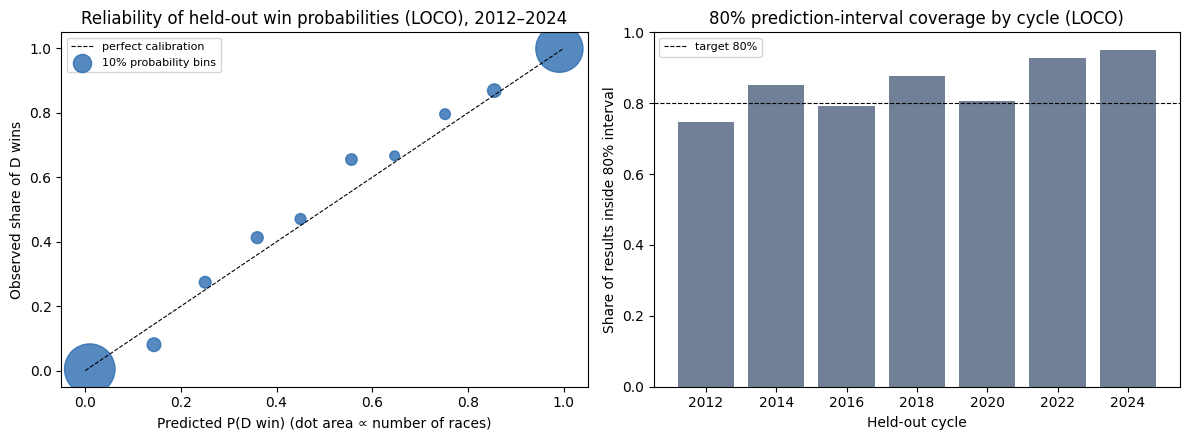

Pooled 80% coverage: 0.850; races with 10-90% probabilities: 493, mean |observed - predicted| in those bins: 0.043


In [ ]:
bins = np.linspace(0, 1, 11)
prob_backtest["p_bin"] = pd.cut(prob_backtest.p_dem_win, bins, include_lowest=True)
reliability = prob_backtest.groupby("p_bin", observed=True).agg(
    predicted=("p_dem_win", "mean"), observed=("dem_share", lambda s: (s > 50).mean()),
    races=("p_dem_win", "size"))
coverage_col = f"{INTERVAL:.0%} coverage"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration")
axes[0].scatter(reliability.predicted, reliability.observed, s=10 + reliability.races,
                color="#2b6cb0", alpha=0.8, label="10% probability bins")
axes[0].set(xlabel="Predicted P(D win) (dot area ∝ number of races)",
            ylabel="Observed share of D wins",
            title=f"Reliability of held-out win probabilities (LOCO), "
                  f"{TRAIN_YEARS[0]}–{TRAIN_YEARS[-1]}")
axes[0].legend(fontsize=8, loc="upper left", markerscale=0.5)
cycle_coverage = calibration_table[coverage_col].drop("pooled")
axes[1].bar(cycle_coverage.index.astype(str), cycle_coverage.values, color="#718096")
axes[1].axhline(INTERVAL, color="k", ls="--", lw=0.8, label=f"target {INTERVAL:.0%}")
axes[1].set(ylim=(0, 1), xlabel="Held-out cycle",
            ylabel=f"Share of results inside {INTERVAL:.0%} interval",
            title=f"{INTERVAL:.0%} prediction-interval coverage by cycle (LOCO)")
axes[1].legend(fontsize=8)
show_figure(fig, "calibration")
middle = reliability[(reliability.predicted > 0.1) & (reliability.predicted < 0.9)]
print(f"Pooled {coverage_col}: {calibration_table.loc['pooled', coverage_col]:.3f}; "
      f"races with 10-90% probabilities: {int(middle.races.sum())}, "
      f"mean |observed - predicted| in those bins: "
      f"{np.average((middle.observed - middle.predicted).abs(), weights=middle.races):.3f}")

**Figure 6.** Left: reliability diagram. Each dot is a 10%-wide bin of predicted probabilities, and dots on the diagonal are perfectly calibrated. Most races fall in the bottom and top bins (safe seats), so the middle bins are the ones that matter. In most of them Democrats won somewhat more often than predicted, which fits the seat PITs above, mostly above 0.5. Right: 80% interval coverage by held-out cycle. With seven cycles, every calibration number here is itself noisy.

## 7. The 2026 forecast

### 7.1 Race forecasts and the seat simulation

The final model from 5.3 is applied to the 2026 races the competition scores. The national level is the 2026 generic-ballot average plus the shrunken, recency-weighted polling-bias correction from all seven training cycles. The error parameters are fitted on the LOCO held-out errors from 6.1, and `N_SIMS` elections are simulated with `POLL_TIMING_SD` added to the shared error.

**Unusual races.** The model treats every scored race the same way; what differs is how the race file defines the D-side share.

* Unscored races (`no_R_side`, `same_party_D/R`) keep the race file's `fixed_prediction` and count as certain seats for that side.
* Louisiana's jungle primaries use the combined D-side vs R-side share. Georgia (runoff rule) and the ranked-choice races (Alaska, Maine) use the final two-way share.
* Independents on the D side count as D-side seats, following the competition's convention.
* Montana's Senate race, where Bankhead (D) and Bodnar (I) both run against Alme (R), uses the combined non-Republican share (`race_type` in `ZERO_WIN_RACE_TYPES`). Under plurality rules a split D side is assumed to lose, so `p_dem_win` is set to 0 and the seat is Republican in every simulation. That is an assumption, not something the model estimates.
* Senate control: seats not up in 2026 are added from `senate_seats_not_up_2026.csv`. Democrats need 51 seats; at 50–50 the Republican vice president breaks ties.

In [ ]:
UNC_FINAL = fit_uncertainty(oos)
print("Uncertainty parameters (pts):", json.dumps(UNC_FINAL, indent=1, default=float))

forecast = races_2026.copy()
scored = forecast.scored == 1
forecast["pred"] = np.nan
NATIONAL_LEVEL_2026 = national_anchor(ELECTION_YEAR, TRAIN_YEARS)
forecast.loc[scored, "pred"] = to_share(NATIONAL_LEVEL_2026,
                                        final_model.predict(forecast.loc[scored, FEATURES]))
sim_races = forecast[scored].reset_index(drop=True)
sims_2026 = simulate_shares(sim_races, UNC_FINAL, N_SIMS, np.random.default_rng(SEED),
                            extra_common_sd=POLL_TIMING_SD)
race_probs = prob_summary(sim_races, sims_2026)
require(len(race_probs) == scored.sum() and np.isfinite(sims_2026).all(), "simulation failed")
d_can_win = ~sim_races.race_type.isin(ZERO_WIN_RACE_TYPES).values   # combined D-side races
race_probs.loc[~d_can_win, "p_dem_win"] = 0.0

fixed = forecast[~scored]
house_fixed_d = int(((fixed.office == "house") & (fixed.fixed_prediction == 1)).sum())
senate_fixed_d = int(((fixed.office == "senate") & (fixed.fixed_prediction == 1)).sum())
notup = raw["notup"]
dem_not_up = int(notup.loc[notup.party.str.startswith("D"), "seats_not_up"].item())
is_house = (sim_races.office == "house").values
d_wins = (sims_2026 > 50) & d_can_win[None, :]
house_seats = d_wins[:, is_house].sum(axis=1) + house_fixed_d
senate_seats = d_wins[:, ~is_house].sum(axis=1) + senate_fixed_d + dem_not_up
seat_sims = pd.DataFrame({"sim": np.arange(1, N_SIMS + 1),
                          "house_dem_seats": house_seats.astype(int),
                          "senate_dem_seats": senate_seats.astype(int)})

national_poll = YEAR_FACTORS.loc[ELECTION_YEAR, "poll_dem2"]
poll_window = GENERIC_BY_YEAR.loc[ELECTION_YEAR, "poll_window"]
print(f"Generic ballot: D {national_poll:.2f}% of the two-party vote (RCP {poll_window}); "
      f"national level after the polling-bias correction: D {NATIONAL_LEVEL_2026:.2f}%")
print(f"Certain D seats: House {house_fixed_d}; Senate seats not up {dem_not_up} "
      f"+ {senate_fixed_d} unscored")
print(f"P(Senate 50-50, R control via the vice president) = {(senate_seats == 50).mean():.3f}")


def seat_summary(seats: np.ndarray, majority: int) -> list[float]:
    """Median, 10th/90th percentiles, P(majority) and mean of simulated D seat counts."""
    return [np.median(seats), np.percentile(seats, 10), np.percentile(seats, 90),
            (seats >= majority).mean(), seats.mean()]


summary_2026 = pd.DataFrame(
    {"House D seats": seat_summary(house_seats, HOUSE_MAJORITY),
     "Senate D seats": seat_summary(senate_seats, SENATE_MAJORITY)},
    index=["median", "10th pct", "90th pct",
           f"P(majority: {HOUSE_MAJORITY} / {SENATE_MAJORITY})", "mean"])
summary_2026.round(3)

Uncertainty parameters (pts): {
 "sd_common": 2.25,
 "sigma_state": 1.8785345436924876,
 "sigma_cat": {
  "house_inc_lag": 2.2114538786936344,
  "house_inc_nolag": 3.00853426167314,
  "house_open": 3.131475468347063,
  "senate": 6.38357396434938,
  "senate_polled": 1.9473154524345389
 },
 "df": 8,
 "n_resid": 2948
}
Generic ballot: D 54.37% of the two-party vote (RCP 10/09-10/26); national level after the polling-bias correction: D 53.93%
Certain D seats: House 17; Senate seats not up 34 + 0 unscored
P(Senate 50-50, R control via the vice president) = 0.116


,House D seats,Senate D seats
median,242.000,51.000
10th pct,222.000,47.000
90th pct,267.000,55.000
P(majority: 218 / 51),0.938,0.546
mean,243.854,50.983


**Table 3. 2026 seat forecast.** Median and 10th–90th percentiles of simulated Democratic seats, and the probability of a Democratic majority. The polling-bias correction lowers the national level from the generic ballot's 54.37% to 53.93%, about 0.4 pts toward the Republicans. Two caveats from Section 6 apply: the width of these ranges rests heavily on `NATIONAL_SD_FLOOR`, and in the backtest the model's House seat totals were less accurate than a uniform-swing baseline's.

### 7.2 Seat distributions

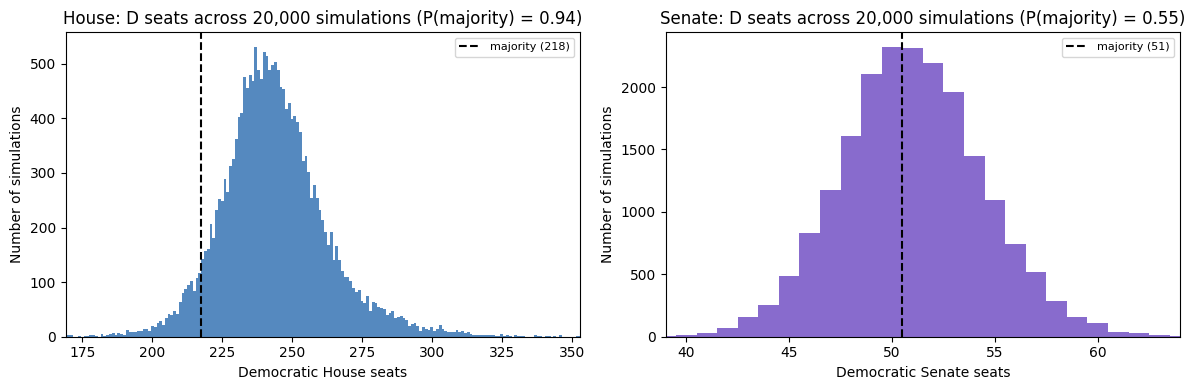

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, seats, majority, chamber, color in [
        (axes[0], house_seats, HOUSE_MAJORITY, "House", "#2b6cb0"),
        (axes[1], senate_seats, SENATE_MAJORITY, "Senate", "#6b46c1")]:
    ax.hist(seats, bins=np.arange(seats.min() - 0.5, seats.max() + 1.5), color=color, alpha=0.8)
    ax.axvline(majority - 0.5, color="k", ls="--", label=f"majority ({majority})")
    ax.set(xlabel=f"Democratic {chamber} seats", ylabel="Number of simulations",
           title=f"{chamber}: D seats across {N_SIMS:,} simulations "
                 f"(P(majority) = {(seats >= majority).mean():.2f})")
    ax.set_xlim(np.percentile(seats, 0.1) - 1, np.percentile(seats, 99.9) + 1)  # hide rare tails
    ax.legend(fontsize=8)
show_figure(fig, "seat_distributions")

**Figure 7.** Simulated Democratic seats, with the dashed line at a majority. The x-axes cover the middle 99.8% of simulations; the extreme tails come from the Student-t errors and are not meaningful. The width of each histogram comes mostly from the shared national error.

### 7.3 Output files and the format check

* `forecast.csv`: the race-level submission in the competition's format. One row per 2026 race, shares and interval bounds as fractions, unscored races at their fixed prediction. `pred_dem_share` is clipped into `[lo_80, hi_80]` because the competition's checker requires the point forecast to lie inside the interval; the simulated percentiles and the point forecast can differ slightly near the clipping bounds.
* `seat_sims.csv`: one row per simulated election, with Democratic seat totals for each chamber.
* `forecast_detailed.csv`: not submitted. Adds candidates, PVI, incumbency, scandal markers, the expert rating and the source of the demographic values, for review.

In [ ]:
review_columns = ["race_id", "office", "state", "race_type", "scored", "fixed_prediction",
                  "dem_candidate", "rep_candidate", "pvi", "inc", "open_seat",
                  "d_scandal_marker", "r_scandal_marker", "rating_mean", "demo_source"]
detailed = forecast[[c for c in review_columns if c in forecast]].copy()
by_race = race_probs.set_index("race_id")
detailed["pred_dem_share"] = detailed.race_id.map(by_race.pred) / 100
detailed["p_dem_win"] = detailed.race_id.map(by_race.p_dem_win)
detailed["lo_80"] = detailed.race_id.map(by_race.lo) / 100
detailed["hi_80"] = detailed.race_id.map(by_race.hi) / 100
for column in ["pred_dem_share", "p_dem_win", "lo_80", "hi_80"]:
    detailed.loc[detailed.scored == 0, column] = detailed.loc[detailed.scored == 0,
                                                              "fixed_prediction"]
detailed["pred_dem_share"] = detailed.pred_dem_share.clip(detailed.lo_80, detailed.hi_80)
detailed["asof"] = FORECAST_DATE
forecast_csv = detailed[["race_id", "pred_dem_share", "p_dem_win", "lo_80", "hi_80", "asof"]]

forecast_csv.to_csv(OUTPUT_DIR / "forecast.csv", index=False)
seat_sims.to_csv(OUTPUT_DIR / "seat_sims.csv", index=False)
detailed.to_csv(OUTPUT_DIR / "forecast_detailed.csv", index=False)
print("Wrote forecast.csv, seat_sims.csv and forecast_detailed.csv. The ten closest scored races:")
detailed[detailed.scored == 1].assign(margin=lambda d: (d.p_dem_win - 0.5).abs()).nsmallest(
    10, "margin")[["race_id", "dem_candidate", "rep_candidate", "pred_dem_share", "p_dem_win",
                   "lo_80", "hi_80"]].round(3)

Wrote forecast.csv, seat_sims.csv and forecast_detailed.csv. The ten closest scored races:


,race_id,dem_candidate,rep_candidate,pred_dem_share,p_dem_win,lo_80,hi_80
197,HOU_ME_02_2026,Matthew Dunlap,Paul LePage,0.502,0.511,0.447,0.555
76,HOU_CO_04_2026,Eileen Laubacher,Lauren Boebert,0.501,0.514,0.454,0.548
435,SEN_AK_2026,Mary Peltola,Dan Sullivan,0.498,0.478,0.453,0.544
343,HOU_SC_01_2026,Nancy Lacore,Jenny Honeycutt,0.503,0.526,0.449,0.556
2,HOU_AL_02_2026,Shomari Figures,Rhett Marques,0.498,0.472,0.445,0.550
207,HOU_MI_10_2026,Christina Hines,Mike Bouchard,0.504,0.537,0.450,0.558
77,HOU_CO_05_2026,Jessica Killin,Jeff Crank,0.496,0.456,0.450,0.543
132,HOU_IA_02_2026,Lindsay James,Joe Mitchell,0.504,0.544,0.450,0.559
201,HOU_MI_04_2026,Sean McCann,Bill Huizenga,0.505,0.554,0.459,0.551
13,HOU_AZ_02_2026,Jonathan Nez,Eli Crane,0.495,0.442,0.448,0.541


The next cell is a Python port of the competition's `check_forecast.R`. It re-reads both files from disk and checks their format, the fixed predictions and the seat ranges. It also checks that the mean simulated seat count matches the sum of the race probabilities, which it must if the two files are consistent.

In [ ]:
def check_forecast(fc: pd.DataFrame, sims: pd.DataFrame, race_list: pd.DataFrame,
                   not_up: pd.DataFrame):
    """Python port of the competition's check_forecast.R. Returns (errors, warnings, E[H], E[S])."""
    errors, warns = [], []
    value_cols = ["pred_dem_share", "p_dem_win", "lo_80", "hi_80"]
    if missing := {"race_id", *value_cols} - set(fc.columns):
        errors.append(f"missing columns {missing}")
    if fc.race_id.duplicated().any():
        errors.append("duplicate race_id")
    if set(race_list.race_id) - set(fc.race_id):
        errors.append("missing races")
    if set(fc.race_id) - set(race_list.race_id):
        errors.append("extra race_ids")
    for column in value_cols:
        values = pd.to_numeric(fc[column], errors="coerce")
        if values.isna().any():
            errors.append(f"{column} has NA")
        if (values > 1).any() or (values < 0).any():
            errors.append(f"{column} outside [0, 1]")
    if (fc.lo_80 > fc.hi_80).any():
        errors.append("lo_80 > hi_80")
    if ((fc.pred_dem_share < fc.lo_80 - 1e-9) | (fc.pred_dem_share > fc.hi_80 + 1e-9)).any():
        errors.append("pred outside interval")
    is_scored = fc.race_id.isin(race_list.race_id[race_list.scored == 1])
    if (is_scored & ((fc.hi_80 - fc.lo_80).abs() < 1e-9)).any():
        warns.append("zero-width interval in a scored race")
    split = is_scored & (((fc.pred_dem_share > .5) & (fc.p_dem_win < .5))
                         | ((fc.pred_dem_share < .5) & (fc.p_dem_win > .5)))
    if split.any():
        warns.append(f"share and probability point to different winners in "
                     f"{list(fc.race_id[split])}")
    fixed_rows = race_list[race_list.fixed_prediction.notna()][
        ["race_id", "fixed_prediction"]].merge(fc, on="race_id")
    for column in value_cols:
        if ((fixed_rows[column] - fixed_rows.fixed_prediction).abs() > 1e-9).any():
            errors.append(f"{column} differs from fixed_prediction in unscored races")
    if "asof" in fc and pd.to_datetime(fc["asof"], format="%Y-%m-%d",
                                       errors="coerce").isna().any():
        warns.append("asof not YYYY-MM-DD")

    d_not_up = int(not_up.loc[not_up.party.str.startswith("D"), "seats_not_up"].item())
    n_senate = int((race_list.office == "senate").sum())
    if len(sims) < 1000:
        errors.append("fewer than 1000 sims")
    if sims.sim.duplicated().any():
        errors.append("duplicate sim ids")
    for column in ["house_dem_seats", "senate_dem_seats"]:
        if (sims[column] != sims[column].round()).any():
            errors.append(f"{column} not whole numbers")
    if not sims.house_dem_seats.between(0, 435).all():
        errors.append("house seats out of range")
    if not sims.senate_dem_seats.between(d_not_up, d_not_up + n_senate).all():
        errors.append("senate seats out of range")
    expected_house = fc.p_dem_win[fc.race_id.isin(
        race_list.race_id[race_list.office == "house"])].sum()
    expected_senate = d_not_up + fc.p_dem_win[fc.race_id.isin(
        race_list.race_id[race_list.office == "senate"])].sum()
    if abs(sims.house_dem_seats.mean() - expected_house) > 5:
        warns.append("House sims vs sum of p_dem_win differ by > 5")
    if abs(sims.senate_dem_seats.mean() - expected_senate) > 2:
        warns.append("Senate sims vs sum of p_dem_win differ by > 2")
    return errors, warns, expected_house, expected_senate


errors, warns, expected_house, expected_senate = check_forecast(
    pd.read_csv(OUTPUT_DIR / "forecast.csv"), pd.read_csv(OUTPUT_DIR / "seat_sims.csv"),
    races, raw["notup"])
print(f"Sum of House p_dem_win = {expected_house:.1f} vs mean simulated "
      f"{seat_sims.house_dem_seats.mean():.1f}; Senate {expected_senate:.1f} vs "
      f"{seat_sims.senate_dem_seats.mean():.1f}")
print("Warnings:", warns or "none")
print("Errors:", errors or "none, check passed")
require(not errors, f"submission files fail the format check: {errors}")

Sum of House p_dem_win = 243.9 vs mean simulated 243.9; Senate 51.0 vs 51.0
Warnings: none
Errors: none, check passed


### 7.4 What the race polls change

For each polled 2026 race, the table compares the final forecast with the forecast from the same model refitted without that chamber's poll features. `moved by` is the difference in pts of D share.

In [ ]:
def poll_effect_table(chamber_mask: pd.Series, avail: str, avg: str, n: str,
                      drop_features: list[str]) -> pd.DataFrame:
    """Polled 2026 races: forecast with and without the given poll features."""
    reduced = [f for f in FEATURES if f not in drop_features]
    model = clone(FINAL_MODEL).fit(train[reduced], train.target, sample_weight=TRAIN_WEIGHTS)
    t = race_probs[chamber_mask & (race_probs[avail] == 1)].copy()
    if t.empty:
        return t
    t["without polls"] = to_share(NATIONAL_LEVEL_2026, model.predict(t[reduced]))
    t = t.rename(columns={avg: "poll avg", n: "pollsters", "pred": "final forecast",
                          "p_dem_win": "P(D win)"})
    t["moved by"] = t["final forecast"] - t["without polls"]
    return t.set_index("race_id")[["dem_candidate", "rep_candidate", "pollsters", "poll avg",
                                   "without polls", "final forecast", "moved by", "P(D win)"]
                                  ].sort_values("P(D win)").round(2)


if SENATE_FEATURES_IN_USE:
    print("Senate:")
    display(poll_effect_table(race_probs.senate == 1, "sen_poll_avail", "sen_poll_avg",
                              "sen_poll_n", SENATE_FEATURES_IN_USE))
if HOUSE_FEATURES_IN_USE:
    house_table = poll_effect_table(race_probs.senate == 0, "house_poll_avail", "house_poll_avg",
                                    "house_poll_n", HOUSE_FEATURES_IN_USE)
    print(f"House: {len(house_table)} polled districts")
    if len(house_table):
        display(house_table)

Senate:


,dem_candidate,rep_candidate,pollsters,poll avg,without polls,final forecast,moved by,P(D win)
race_id,,,,,,,,
SEN_MT_2026,Alani Bankhead; Seth Bodnar,Kurt Alme,2,53.53,43.56,47.58,4.02,0.00
SEN_ID_2026,Todd Achilles,Jim Risch,1,32.88,36.89,31.38,-5.51,0.00
SEN_SD_2026,Brian Bengs,Mike Rounds,1,50.59,38.41,42.80,4.40,0.02
SEN_AR_2026,Hallie Shoffner,Tom Cotton,2,44.44,40.97,42.98,2.01,0.02
SEN_FL_2026,Angela Nixon,Ashley Moody,7,46.16,46.74,44.39,-2.35,0.06
SEN_MS_2026,Scott Colom,Cindy Hyde-Smith,1,48.00,43.06,44.55,1.49,0.06
SEN_NE_2026,Dan Osborn,Pete Ricketts,3,48.70,46.57,47.82,1.25,0.26
SEN_SC_2026,Annie Andrews,Darline Graham Nordone,2,48.15,49.96,47.79,-2.17,0.26
SEN_KS_2026,Adam Hamilton,Roger Marshall,5,50.90,48.06,48.35,0.29,0.31


House: 63 polled districts


,dem_candidate,rep_candidate,pollsters,poll avg,without polls,final forecast,moved by,P(D win)
race_id,,,,,,,,
HOU_ID_01_2026,Kaylee Peterson,Russ Fulcher,1,33.33,31.39,31.87,0.48,0.00
HOU_SD_01_2026,Nikki Gronli,Marty Jackley,1,34.78,36.62,35.53,-1.09,0.00
HOU_VA_06_2026,Beth Macy,Ben Cline,1,32.95,40.81,38.57,-2.24,0.00
HOU_GA_03_2026,Maura Keller,Brian Jack,1,47.37,37.26,39.62,2.36,0.00
HOU_TN_05_2026,Chaz Molder,Charlie Hatcher,1,47.13,44.82,43.98,-0.84,0.08
...,...,...,...,...,...,...,...,...
HOU_RI_02_2026,Seth Magaziner,Vic Mellor,2,57.83,60.64,59.59,-1.05,0.99
HOU_NM_03_2026,Teresa Leger Fernandez,Martin Zamora,1,57.61,60.62,59.82,-0.81,0.99
HOU_CT_02_2026,Joe Courtney,George Austin,1,61.18,60.18,59.93,-0.25,0.99


The final forecast is not constrained to lie between the polling average and the no-poll forecast, because the poll indicator and its interactions shift the level as well as blending in the poll. In most competitive Senate races the polls pulled the forecast toward the Republican, and in Idaho, Florida, South Carolina, Maine, Ohio, Iowa, Alaska and Minnesota the final forecast is below both the polling average and the no-poll forecast. On their polling averages alone, Democrats would lead in Maine, Ohio, Iowa, Alaska and Kansas; the model has them behind in all five. The direction is consistent with the backtest, where the raw Senate average overstated Democrats by about 1.4 pts, but the size of the adjustment comes from coefficients estimated on fewer than 200 polled Senate races. In safely Republican states with closer-than-expected polls (South Dakota, Arkansas, Mississippi, Nebraska, Kansas) the polls moved the forecast toward the Democrat.

## 8. What drives the forecasts

### 8.1 Feature contributions (exact SHAP values)

For a linear model, the SHAP value of feature $j$ for race $i$ has a closed form,

$$\phi_{ij} = \beta_j \left(x_{ij} - \bar{x}_j\right),$$

where $\bar{x}_j$ is the feature's mean over the training races. No sampling or approximation is involved. The `shap` package  draws the plots. Values are in pts of D share: positive pushes toward the Democrat, negative toward the Republican, relative to a race with average training features (the "base value"). For every race,

$$\widehat{\text{share}}_i = N_{2026} + \text{base value} + \sum_j \phi_{ij} \qquad \text{(before the [1, 99] clip).}$$

SHAP describes how the model uses its inputs. Correlated features (PVI and the prior result; a poll average and its interactions; the Hispanic share and its swing interaction) split credit according to their coefficients, often in opposite directions, so the group totals at the end of this section are more meaningful than the individual values.

SHAP values for 452 scored 2026 races; base value (relative share of a race with average features) = +0.14 pts


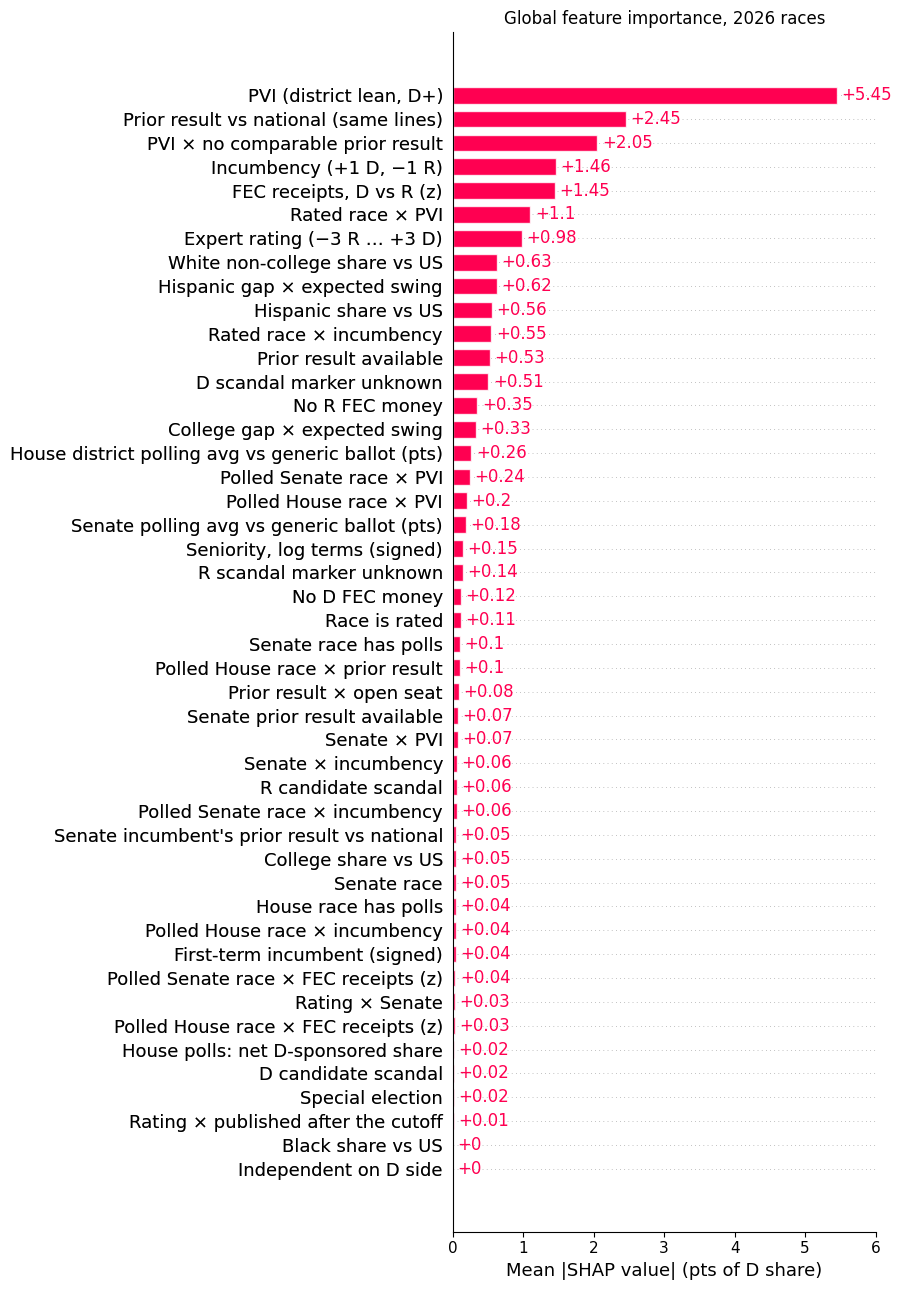

In [ ]:
X_2026 = sim_races[FEATURES]
train_mean = train[FEATURES].mean()
contributions = (X_2026 - train_mean).values * final_model.coef_
base_value = float(final_model.predict(train_mean.to_frame().T)[0])
shap_values = shap.Explanation(values=contributions,
                               base_values=np.full(len(X_2026), base_value),
                               data=X_2026.values,
                               feature_names=[FEATURE_LABELS[c] for c in FEATURES])
require(np.allclose(shap_values.values.sum(axis=1) + shap_values.base_values,
                    final_model.predict(X_2026), atol=1e-6),
        "SHAP values do not add up to predictions")
print(f"SHAP values for {len(X_2026)} scored {ELECTION_YEAR} races; base value (relative share "
      f"of a race with average features) = {base_value:+.2f} pts")

shap.plots.bar(shap_values, max_display=len(FEATURES), show=False)
fig = plt.gcf()
fig.set_size_inches(9, 0.25 * len(FEATURES) + 1.5)
plt.title(f"Global feature importance, {ELECTION_YEAR} races")
plt.xlabel("Mean |SHAP value| (pts of D share)")
show_figure(fig, "shap_importance_bar")

**Figure 8.** Mean absolute contribution of each feature to the 2026 forecasts.

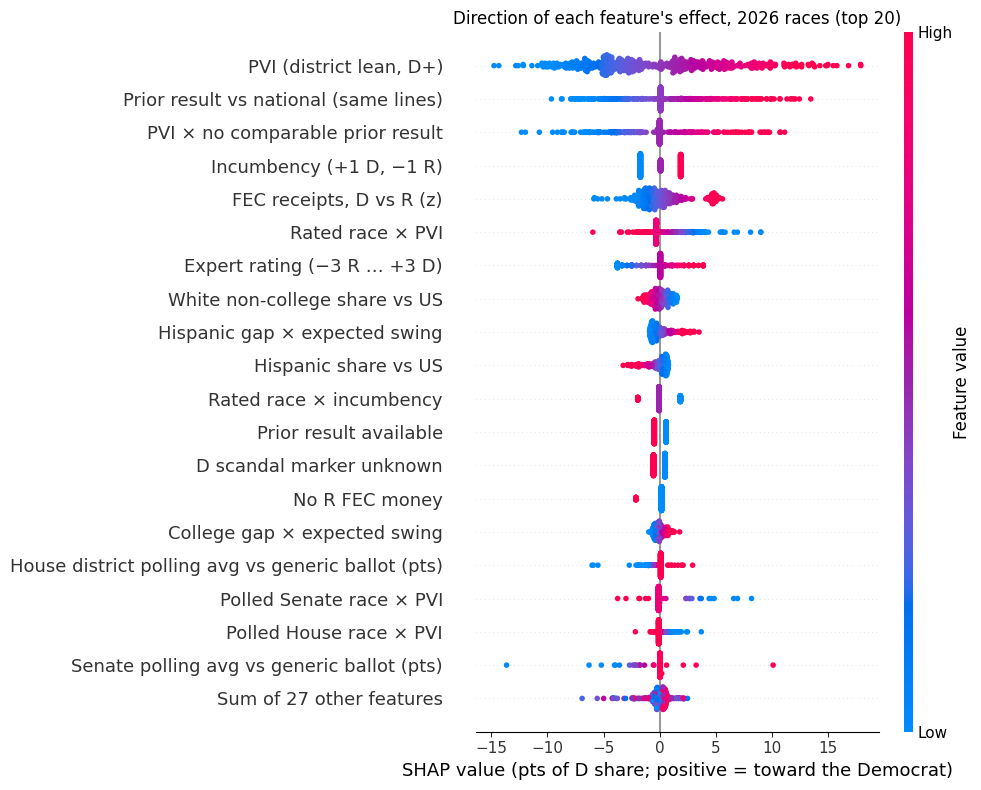

In [ ]:
shap.plots.beeswarm(shap_values, max_display=20, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 8)
plt.title(f"Direction of each feature's effect, {ELECTION_YEAR} races (top 20)")
plt.xlabel("SHAP value (pts of D share; positive = toward the Democrat)")
show_figure(fig, "shap_beeswarm")

**Figure 9.** Each dot is a 2026 race, coloured by the feature's value (red high, blue low). In a linear model each feature's dots lie on a line, so the colour gradient shows the direction of the effect: for a positive coefficient, red dots sit to the right.

In [ ]:
shap_table = pd.DataFrame({
    "feature": FEATURES,
    "label": [FEATURE_LABELS[c] for c in FEATURES],
    "group": [GROUP_OF[c] for c in FEATURES],
    "mean |SHAP|": np.abs(shap_values.values).mean(axis=0),
    "mean SHAP": shap_values.values.mean(axis=0),
}).sort_values("mean |SHAP|", ascending=False).reset_index(drop=True)
group_shap = (pd.DataFrame(shap_values.values, columns=FEATURES).T
              .groupby([GROUP_OF[c] for c in FEATURES]).sum().T
              .abs().mean().sort_values(ascending=False).rename("mean |group SHAP| (pts)"))
display(shap_table.round(3))
print("By feature group (SHAP values summed within the group, then averaged in absolute value):")
group_shap.round(3).to_frame()

,feature,label,group,mean |SHAP|,mean SHAP
0,pvi,"PVI (district lean, D+)",partisanship,5.450,-0.125
1,lag_rel_f,Prior result vs national (same lines),prior result,2.454,0.405
2,pvi_nolag,PVI × no comparable prior result,partisanship,2.051,-0.481
3,inc,"Incumbency (+1 D, −1 R)",incumbency & seniority,1.463,0.035
4,money_z,"FEC receipts, D vs R (z)",money (FEC),1.451,-0.002
5,rating_x_pvi,Rated race × PVI,expert ratings,1.101,0.408
6,rating,Expert rating (−3 R … +3 D),expert ratings,0.977,-0.350
7,demo_white_noncollege,White non-college share vs US,demographics,0.627,0.004
8,hispanic_x_swing,Hispanic gap × expected swing,demographics,0.624,-0.039
9,demo_hispanic,Hispanic share vs US,demographics,0.559,-0.005


By feature group (SHAP values summed within the group, then averaged in absolute value):


,mean |group SHAP| (pts)
partisanship,7.556
prior result,2.786
incumbency & seniority,1.700
money (FEC),1.212
demographics,0.821
expert ratings,0.660
scandal (Wikipedia),0.570
House polls,0.128
Senate polls,0.115
Senate prior result,0.088


Partisanship dominates. Summed within each group, the PVI terms move the average 2026 forecast by about 7.6 pts, followed by the prior result (2.8), incumbency (1.7) and money (1.2). The group totals for demographics (0.8) and expert ratings (0.7) are much smaller than the sum of their members' individual values, because their features partly cancel. Polls move the average race by only about 0.1 pts per chamber because most races are unpolled; in the polled races the effect is much larger (7.4).

### 8.2 Explaining one forecast

The waterfall breaks down the forecast for the closest scored race, the one with P(D win) nearest 50%. Starting from the base value at the bottom and adding each feature's contribution gives the predicted share relative to the national vote; adding the national level gives the forecast, as the printed line shows.

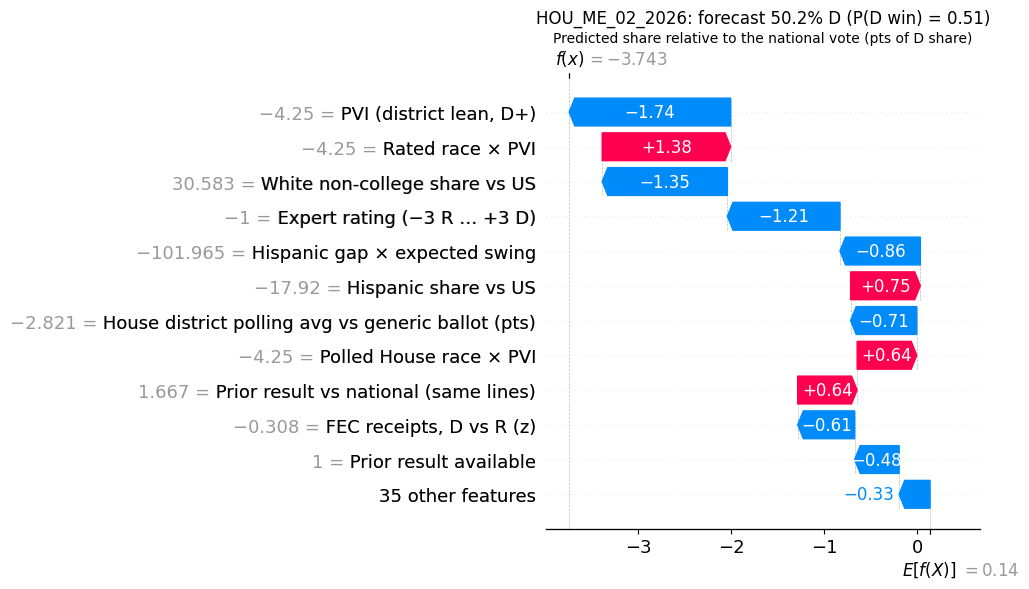

HOU_ME_02_2026: national level 53.93% + base value +0.14 + SHAP sum -3.88 = 50.19% D


In [ ]:
closest = int((race_probs.p_dem_win - 0.5).abs().idxmin())
closest_race = race_probs.loc[closest]
shap.plots.waterfall(shap_values[closest], max_display=12, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 6)
plt.title(f"{closest_race.race_id}: forecast {closest_race.pred:.1f}% D "
          f"(P(D win) = {closest_race.p_dem_win:.2f})")
plt.xlabel("Predicted share relative to the national vote (pts of D share)")
show_figure(fig, "shap_waterfall_closest_race")
print(f"{closest_race.race_id}: national level {NATIONAL_LEVEL_2026:.2f}% "
      f"+ base value {base_value:+.2f} + SHAP sum "
      f"{shap_values.values[closest].sum():+.2f} = {closest_race.pred:.2f}% D")

**Figure 10.** In ME-02 almost every contribution points toward the Republican. The model puts the district about 3.7 pts more Republican than the nation, and the race is a toss-up only because the national level (53.9% D) offsets that. The PVI terms show the interaction structure from 5.3 at work: the raw PVI contribution (−1.7) is mostly cancelled by the rated-race and polled-race interactions (+1.4 and +0.6), with the rating itself (Lean R) carrying the partisanship instead.

## 9. Saved outputs

The next cell writes the fitted model, its settings, the evaluation tables and the package versions to `OUTPUT_DIR`.

| File | Contents |
|---|---|
| `forecast.csv`, `seat_sims.csv`, `forecast_detailed.csv` | The 2026 forecast (7.3) |
| `linear_model.joblib`, `linear_model_info.json` | Fitted model; features, coefficients, settings and headline metrics |
| `coefficients.csv`, `coefficient_stability.csv` | Sections 5.3–5.4 |
| `eval_oos_by_year.csv`, `eval_baselines.csv` | Sections 6.1–6.2 |
| `eval_calibration.csv`, `eval_calibration_forward.csv`, `eval_seat_check.csv` | Section 6.4 |
| `shap_importance_2026.csv`, `seat_summary_2026.csv` | Sections 8.1 and 7.1 |
| `scandal_markers.csv`, `data_manifest.csv` | The markers as used, and the input manifest |
| `environment.json` | Python and package versions |
| `figures/*.png` | Every figure, written only when `SAVE_FIGURES = True` |

In [ ]:
joblib.dump(final_model, OUTPUT_DIR / "linear_model.joblib", compress=3)
run_info = {
    "model": "LinearRegression (weighted least squares, recency weights by cycle)",
    "target": "dem_share - actual national House D share",
    "national_level": "generic ballot + sum(w * (actual - poll)) / (sum(w) + NAT_SHRINK_N0)",
    "nat_shrink_n0": NAT_SHRINK_N0,
    "recency_decay": RECENCY_DECAY,
    "recency_weight_national": RECENCY_WEIGHT_NATIONAL,
    "cycle_weights_2026": {int(year): float(w) for year, w in weight_by_year.items()},
    "national_level_2026": NATIONAL_LEVEL_2026,
    "features": FEATURES,
    "intercept": final_model.intercept_,
    "coefficients": dict(zip(FEATURES, final_model.coef_)),
    "cv": f"leave-one-cycle-out over {TRAIN_YEARS[0]}-{TRAIN_YEARS[-1]}",
    "loco_mae": float(oos_metrics.loc["pooled", ("all", "MAE")]),
    "forward_mae": float(baseline_table.loc[("forward-chaining", FINAL_NAME), "MAE"]),
    "seed": SEED,
    "forecast_date": FORECAST_DATE,
    "settings": {"use_demographics": DEMOGRAPHICS is not None,
                 "use_district_demographics": DISTRICT_DEMOGRAPHICS is not None,
                 "allow_same_year_district_acs": ALLOW_SAME_YEAR_DISTRICT_ACS,
                 "use_ratings": RATINGS is not None,
                 "use_swing_interactions": USE_SWING_INTERACTIONS,
                 "use_senate_polls": SENATE_POLLS is not None,
                 "use_house_polls": HOUSE_POLLS is not None,
                 "poll_window_days": POLL_WINDOW_DAYS, "national_sd_floor": NATIONAL_SD_FLOOR,
                 "poll_timing_sd": POLL_TIMING_SD, "n_sims": N_SIMS},
    "uncertainty": UNC_FINAL,
}
with open(OUTPUT_DIR / "linear_model_info.json", "w") as handle:
    json.dump(run_info, handle, indent=1, default=float)
with open(OUTPUT_DIR / "environment.json", "w") as handle:
    json.dump({"python": sys.version.split()[0], **PACKAGE_VERSIONS}, handle, indent=1)

coef_table.to_csv(OUTPUT_DIR / "coefficients.csv")
stability.to_csv(OUTPUT_DIR / "coefficient_stability.csv")
oos_metrics.to_csv(OUTPUT_DIR / "eval_oos_by_year.csv")
baseline_table.to_csv(OUTPUT_DIR / "eval_baselines.csv")
calibration_table.to_csv(OUTPUT_DIR / "eval_calibration.csv")
calibration_forward.to_csv(OUTPUT_DIR / "eval_calibration_forward.csv")
seat_check.to_csv(OUTPUT_DIR / "eval_seat_check.csv")
shap_table.to_csv(OUTPUT_DIR / "shap_importance_2026.csv", index=False)
summary_2026.to_csv(OUTPUT_DIR / "seat_summary_2026.csv")
print("Saved:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved: ['coefficient_stability.csv', 'coefficients.csv', 'data_manifest.csv', 'environment.json', 'eval_baselines.csv', 'eval_calibration.csv', 'eval_calibration_forward.csv', 'eval_oos_by_year.csv', 'eval_seat_check.csv', 'figures', 'forecast.csv', 'forecast_detailed.csv', 'linear_model.joblib', 'linear_model_info.json', 'scandal_markers.csv', 'seat_sims.csv', 'seat_summary_2026.csv', 'shap_importance_2026.csv']


## 10. Limitations

The forecast supports a transparent estimate of each race's vote share and win probability, conditional on the national level being roughly right and on 2026 resembling 2012–2024.

### Data

* **Money is measured at different times.** Historical FEC totals cover the whole cycle, including late money that follows expected competitiveness and post-election receipts; the 2026 numbers stop on 30 September. Standardising within cycle narrows the gap but does not close it. Rebuilding the historical totals from reports that close by 30 September would.
* **Race polls are not collected the same way in every year** (3.6). The 2012–2022 polls cover only the final three weeks of each campaign and are dated differently from the 2024–2026 polls. House polls are sparse (a median of one pollster per polled race) and often partisan internals.
* **Scandal markers are heuristic.** About half of the candidates are unknown, a keyword classifier misses some scandals and flags some false positives, and 505 markers were corrected by hand. The unknown flag probably measures candidate prominence more than scandal.
* **Expert ratings change meaning over time.** For 2012 and the 2014–2018 House races only the final ratings survive, better informed than 2026 ratings taken 13 days out, so the slope used for 2026 rests mainly on 2020–2024 House races and on Senate races. Ratings also draw on the polls and fundraising the model already uses, so their coefficients measure only what they add beyond those.
* **Some inputs are older than the forecast date.** The ratings and the 2026 scandal markers were read on 21 October, six days before `FORECAST_DATE`. Rebuilding with `build_race_ratings.py` and `wikipedia_scandal.py --forecast-date 2026-10-27` would align them.
* **PVI comes in several vintages** (crosstab in 2.3), so a given PVI does not mean exactly the same thing in every cycle. The basis of the 2026 PVI is not recorded in the race file.
* **District demographics look ahead and mix estimate types.** In every training year except 2020, district values come from an ACS release published after the election (3.5). The 173 districts redrawn for 2026 use a 2020–2024 5-year ACS, all others 1-year estimates.


## 11. Summary

The next cell prints the headline numbers from this run.

In [ ]:
pooled_oos = oos_metrics.loc["pooled"]
forward = baseline_table.xs("forward-chaining")
seats_fwd = seat_check.xs("forward-chaining")
seats_loco = seat_check.xs("leave-one-cycle-out")
best_baseline_fwd = forward.drop(index=[FINAL_NAME, *ABLATION_NAMES], errors="ignore").MAE.min()
print(f"Training data: {len(train):,} contested races, {TRAIN_YEARS[0]}-{TRAIN_YEARS[-1]}; "
      f"{len(FEATURES)} features")
print(f"Recency weights: RECENCY_DECAY = {RECENCY_DECAY}, effective number of cycles "
      f"{effective_cycles:.1f} of {len(TRAIN_YEARS)}; forward-chaining MAE with equal weights "
      f"{forward.loc[EQUAL_WEIGHT_NAME, 'MAE']:.2f} pts")
print(f"Held-out accuracy (leave-one-cycle-out): MAE {pooled_oos[('all', 'MAE')]:.2f} pts, "
      f"RMSE {pooled_oos[('all', 'RMSE')]:.2f} pts, R² {pooled_oos[('all', 'R2')]:.3f}, "
      f"winners {pooled_oos[('all', 'winner_acc')]:.1%} "
      f"(competitive seats: MAE {pooled_oos[('competitive', 'MAE')]:.2f}, "
      f"winners {pooled_oos[('competitive', 'winner_acc')]:.1%})")
print(f"Forward-chaining MAE: final model {forward.loc[FINAL_NAME, 'MAE']:.2f} pts vs best simple "
      f"baseline {best_baseline_fwd:.2f} pts; mean |House seat error| "
      f"{forward.loc[FINAL_NAME, 'mean |House seat error|']:.1f} seats")
print(f"Probabilistic (LOCO): Brier {calibration_table.loc['pooled', 'Brier']:.3f}, "
      f"80% coverage {calibration_table.loc['pooled', coverage_col]:.2f}")
print(f"Seat check: actual House seats inside the simulated 80% range in "
      f"{int(seats_loco['inside 80% range'].sum())} of {len(seats_loco)} cycles (LOCO) and "
      f"{int(seats_fwd['inside 80% range'].sum())} of {len(seats_fwd)} (forward-chaining)")
print(f"National level for {ELECTION_YEAR}: D {NATIONAL_LEVEL_2026:.2f}% "
      f"(generic ballot {national_poll:.2f}%)")
print(f"House: median {np.median(house_seats):.0f} D seats "
      f"(80% range {np.percentile(house_seats, 10):.0f}-{np.percentile(house_seats, 90):.0f}), "
      f"P(D majority) = {(house_seats >= HOUSE_MAJORITY).mean():.2f}")
print(f"Senate: median {np.median(senate_seats):.0f} D seats "
      f"(80% range {np.percentile(senate_seats, 10):.0f}-{np.percentile(senate_seats, 90):.0f}), "
      f"P(D majority) = {(senate_seats >= SENATE_MAJORITY).mean():.2f}, "
      f"P(50-50) = {(senate_seats == 50).mean():.2f}")
print("Top feature groups by mean |SHAP|:", ", ".join(group_shap.index[:3]))
print(f"Submission files: {OUTPUT_DIR / 'forecast.csv'} and {OUTPUT_DIR / 'seat_sims.csv'}; "
      f"format check: {'passed' if not errors else 'FAILED'}"
      + (f" with warnings {warns}" if warns else ""))

Training data: 2,948 contested races, 2012-2024; 46 features
Recency weights: RECENCY_DECAY = 0.75, effective number of cycles 5.4 of 7; forward-chaining MAE with equal weights 2.75 pts
Held-out accuracy (leave-one-cycle-out): MAE 2.74 pts, RMSE 3.57 pts, R² 0.953, winners 95.4% (competitive seats: MAE 2.73, winners 90.8%)
Forward-chaining MAE: final model 2.68 pts vs best simple baseline 2.96 pts; mean |House seat error| 13.4 seats
Probabilistic (LOCO): Brier 0.032, 80% coverage 0.85
Seat check: actual House seats inside the simulated 80% range in 6 of 7 cycles (LOCO) and 4 of 5 (forward-chaining)
National level for 2026: D 53.93% (generic ballot 54.37%)
House: median 242 D seats (80% range 222-267), P(D majority) = 0.94
Senate: median 51 D seats (80% range 47-55), P(D majority) = 0.55, P(50-50) = 0.12
Top feature groups by mean |SHAP|: partisanship, prior result, incumbency & seniority
Submission files: /content/drive/MyDrive/Election Predicting/outputs_linear_updated/forecast.csv an

**What the results show.**

1. **Race-level accuracy.** Forward-chaining is the more realistic test. On it the model misses by about 2.7 pts per race on average, roughly 0.3 pts better than carrying each district's last result forward. Most of the skill comes from partisanship, the prior result and incumbency. Polls and expert ratings each add a little; demographics add nothing measurable.
2. **Seat totals are the weak point.** In the backtest the model's House seat totals missed by more than uniform swing's, mainly because of 2020. The seat distributions are best read as a statement about the national environment, not as a precise count.
3. **2026.** The generic ballot put Democrats at 54.4% of the two-party vote, and the polling-bias correction lowers that to 53.9%. From there the model gives Democrats a 94% chance of a House majority and a 55% chance in the Senate. The Senate turns on a handful of races within about a point of even: Alaska, Iowa, Ohio and Maine just on the Republican side, with Michigan and Minnesota a little further on the Democratic side.
4. **What would make it wrong.** A national polling miss larger than any in 2012–2024; a swing concentrated in particular kinds of districts, as in 2018; or Senate polls that, unlike in the training years, understate the Democrats.